In [2]:
import numpy as np
import healpy as hp

import matplotlib
from matplotlib import pyplot as plt

from scipy import stats
import matplotlib.gridspec as gridspec
import astropy.cosmology.units as cu
import astropy.units as u
import site
site.addsitedir('/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts') 
import quaia
import sampler
import seaborn as sns
from matplotlib.colors import LogNorm
import matplotlib.patches as mpatches
import pyccl as ccl
from matplotlib.lines import Line2D
from matplotlib import cm
from scipy.optimize import minimize
from astropy.cosmology import Planck18
from dynesty import NestedSampler
from dynesty import plotting as dyplot
from dynesty import utils as dyfunc
from astropy.coordinates import SkyCoord
from scipy import linalg
from scipy.special import gamma
from healpy.newvisufunc import projview
from scipy import special

In [3]:
matplotlib.rcParams['ytick.labelsize'] = 18
matplotlib.rcParams['xtick.labelsize'] = 18
matplotlib.rcParams['axes.labelsize'] = 22
matplotlib.rcParams['legend.fontsize'] = 18
matplotlib.rcParams['axes.titlesize'] = 20

# G20.5
## Define parameters

In [4]:
G_hi = 20.5

In [5]:
nthreads = 18

In [6]:
z_bins = np.array([0.0, 1.0, 2.0, 3.0, 4.6])
z_array = range(len(z_bins)-1)
mask = 0.5

In [7]:
cosmo_planck18 = ccl.Cosmology(
    Omega_c=Planck18.Odm0,
    Omega_b=Planck18.Ob0,
    h=Planck18.h,
    Neff=Planck18.Neff,
    T_CMB=Planck18.Tcmb0.value,
    m_nu=Planck18.m_nu,
    sigma8=0.8102,   # or pull from wherever your actual source specifies Planck18's sigma8
    n_s=0.9665        # same
)

In [8]:
Delta = 200
delta_c = 1.686

In [9]:
hmf = ccl.halos.MassFuncTinker10()

In [10]:
M_max = 16.8 #15

## Define functions

In [11]:
def a_median(tab_datahi_mask_zbin0, key_zbin0 = ''):
    return 1/(1+np.median(tab_datahi_mask_zbin0['redshift_quaia'+key_zbin0]))

In [12]:
def nu(M, delta_c = delta_c, a = 1, cosmo = cosmo_planck18):
    
    sigma = cosmo.sigmaM(M, a = a)
   
    return delta_c/sigma

In [13]:
def n_g_theory(bins, n_total, a = 1, cosmo = cosmo_planck18, hmf = hmf, recenter = True):

    if recenter == True:
        bins = quaia.recenter(bins)
    nm = hmf(cosmo, bins, a)/cosmo['h']**3
    n_g = nm/(bins*np.log(10))*n_total
    n_g[np.isnan(n_g)]=0
    
    return n_g, nm

def bias(bins, n_m, a = 1, cosmo = cosmo_planck18, mod = False, recenter = True):

    n_g, nm = n_g_theory(bins, n_m, a = a, cosmo = cosmo, recenter = recenter)
    if recenter == True:
        print('recentering')
        bins = quaia.recenter(bins)
    n_g = np.trapz(n_g, bins)
    dn_dm = nm/(bins*np.log(10))

    b1_E_tinker = b1_E_func(nu(bins, a = a, cosmo = cosmo), mod = mod)

    n_m[~np.isfinite(n_m)]=0 
    integrand = dn_dm*n_m
    integrand[np.isnan(integrand)]=0
    
    return bias_function(n_g, integrand, b1_E_tinker, bins, recenter = recenter), n_g

In [14]:
def b1_E_func(nu, Delta = Delta, delta_c = delta_c, mod = False):

    delta_c = 1.686
    
    if mod == False:
        y = np.log10(Delta)
        A =  1.0+0.24*y*np.exp(-(4/y)**4)
        a = 0.44*y-0.88
        B = 0.183
        b =  1.5
        C = 0.019+0.107*y+0.19*np.exp(-(4/y)**4)
        c = 2.4
        
    else:
        A =  1.0
        a = 0.0906
        B = -4.5002
        b =  2.1419
        C = 4.9148
        c = 2.1419
        
    return 1-A*nu**a/(nu**a+delta_c**a)+B*nu**b+C*nu**c # Jose et al
    
def bias_function(n_g, integrand, b, bins, recenter = True):
    
    if recenter == True:
        print('recentering')
        bins = quaia.recenter(bins)
        
    return 1/n_g*np.trapz(integrand*b, bins)

In [15]:
def cf_2h(bins, n_m, a, cosmo, cf_matter, recenter = True):
    
    b_q, n_g = bias(bins, n_m, a, cosmo, recenter = recenter)
    return b_q**2*cf_matter, b_q

# Visualize the luminosity threshold cuts and redshift bins

In [16]:
L_array = np.array([-32, -27, -26, -25, -20], dtype = float)[::-1]

In [17]:
L_bins = L_array[::-1][:0:-1]
L_bins

array([-20., -25., -26., -27.])

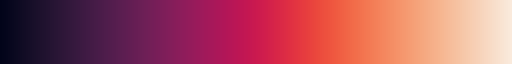

In [18]:
cmap = sns.color_palette("rocket", as_cmap=True)
cmap

In [19]:
b = 30
fac_rand = 25
tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _ = quaia.make_bins(G_hi, 0, True, 'z', 
                                                                                             bins = [0,4.6], tab_gcat_type = 'data', fac_rand = fac_rand, 
                                                                                              mask_type = 'b', b = b, n_bins = None)

Leaving tab_gcat_catalog unbinned
Pixels masked by MC but not already by selfunc: 10324
G20.5: 0.30              907242 vs 1295502


Text(0, 0.5, '$K$-correction')

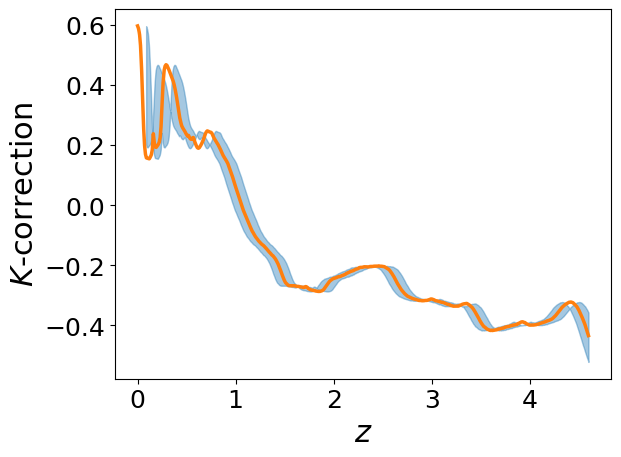

In [40]:
import scipy.interpolate as interp

k = np.loadtxt('../data/maps/datafile4.txt')
k_z = interp.interp1d(k[:,0], k[:,1], bounds_error=False)
zz = np.linspace(0, 4.6, 2000)
s = np.median(tab_datahi_mask_zbin0['redshift_quaia_err'])
lo, hi = k_z(zz - s), k_z(zz + s)

plt.plot(zz, k_z(zz), c='C1', lw=2.5)
plt.fill_between(zz, np.minimum(lo, hi), np.maximum(lo, hi), color='C0', alpha=0.4)
plt.xlabel('$z$'); plt.ylabel('$K$-correction')

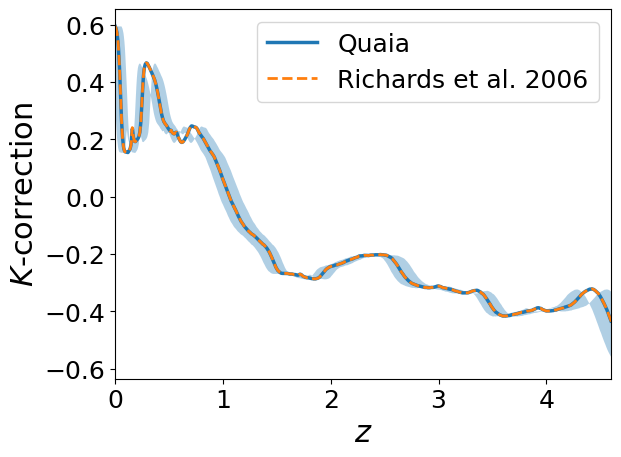

In [50]:
k = np.loadtxt('../data/maps/datafile4.txt')
k_z = interp.interp1d(k[:,0], k[:,1], bounds_error=False)

tab = tab_datahi_mask_zbin0
z  = np.asarray(tab['redshift_quaia'])
sz = np.asarray(tab['redshift_quaia_err'])

# median sigma_z as a function of z
edges = np.linspace(0, 4.6, 24)
zc = 0.5*(edges[1:] + edges[:-1])
ib = np.digitize(z, edges)
s_med = np.array([np.nanmedian(sz[ib==j]) if np.any(ib==j) else np.nan
                  for j in range(1, len(edges))])
ok = np.isfinite(s_med)

zz = np.linspace(0, 4.6, 1000)
s_zz = np.interp(zz, zc[ok], s_med[ok])
lo = k_z(np.clip(zz - s_zz, k[:,0].min(), None))
hi = k_z(zz + s_zz)

# fig, ax = plt.subplots(figsize=(10, 8))
plt.fill_between(zz, np.minimum(lo, hi), np.maximum(lo, hi),
                color='C0', alpha=0.35, lw=0)#, label=r'$K(z\pm\sigma_z)$')
plt.plot(zz, k_z(zz), c='C0', lw=2.5, label='Quaia')
plt.plot(k[:,0], k[:,1], c='C1', ls='--', lw=2, label='Richards et al. 2006')
# for zb in [1, 2, 3]:
#     ax.axvline(zb, c='gray', lw=0.8, alpha=0.6)   # optional: your z bin edges
plt.xlim(0, 4.6)
plt.xlabel('$z$'); plt.ylabel('$K$-correction')
plt.legend()
# fig.tight_layout()
plt.show()

In [88]:
cmap_rocket = sns.color_palette("flare_r", n_colors = 1)
cmap_rocket

[(0.76214598, 0.25492998, 0.40539471)]

In [99]:
import importlib
importlib.reload(quaia)

<module 'quaia' from '/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/quaia.py'>

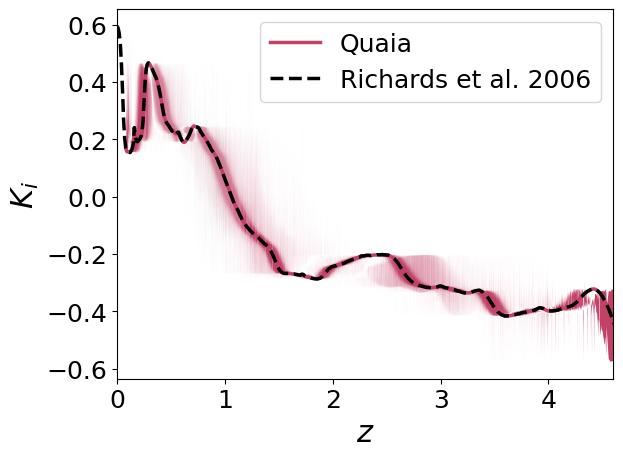

array([ 2351.99612994, 13397.25003193, 11312.87200823, ...,
       20331.42198124, 12512.68945875,  4349.94408756])

In [100]:
quaia.absolute(tab_datahi_mask_zbin0, G_hi, plot = True, color1 = cmap_rocket[0], color2 = 'black')

<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:64: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:64: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_80126/3567817471.py:30: SyntaxWarning: invalid escape sequence '\m'
  ax2_hi.set_ylabel('$N_\mathrm{QSO}$')
/tmp/ipykernel_80126/3567817471.py:64: SyntaxWarning: invalid escape sequence '\m'
  ax3_hi.set_xlabel('$N_\mathrm{QSO}$')


Pixels masked by MC but not already by selfunc: 35
G20.5_zmin0.0zmax1.0_Lmin-32.0Lmax-27.0: 0.59              754 vs 1860
Pixels masked by MC but not already by selfunc: 365
G20.5_zmin1.0zmax2.0_Lmin-32.0Lmax-27.0: 0.46              20349 vs 38015
Pixels masked by MC but not already by selfunc: 1035
G20.5_zmin2.0zmax3.0_Lmin-32.0Lmax-27.0: 0.37              64134 vs 102196
Pixels masked by MC but not already by selfunc: 256
G20.5_zmin3.0zmax4.6_Lmin-32.0Lmax-27.0: 0.26              21337 vs 28856
Pixels masked by MC but not already by selfunc: 88
G20.5_zmin0.0zmax1.0_Lmin-27.0Lmax-26.0: 0.50              5182 vs 10412
Pixels masked by MC but not already by selfunc: 1173
G20.5_zmin1.0zmax2.0_Lmin-27.0Lmax-26.0: 0.39              88880 vs 144714
Pixels masked by MC but not already by selfunc: 1522
G20.5_zmin2.0zmax3.0_Lmin-27.0Lmax-26.0: 0.24              119349 vs 156795
Pixels masked by MC but not already by selfunc: 49
G20.5_zmin3.0zmax4.6_Lmin-27.0Lmax-26.0: 0.12              6706 vs

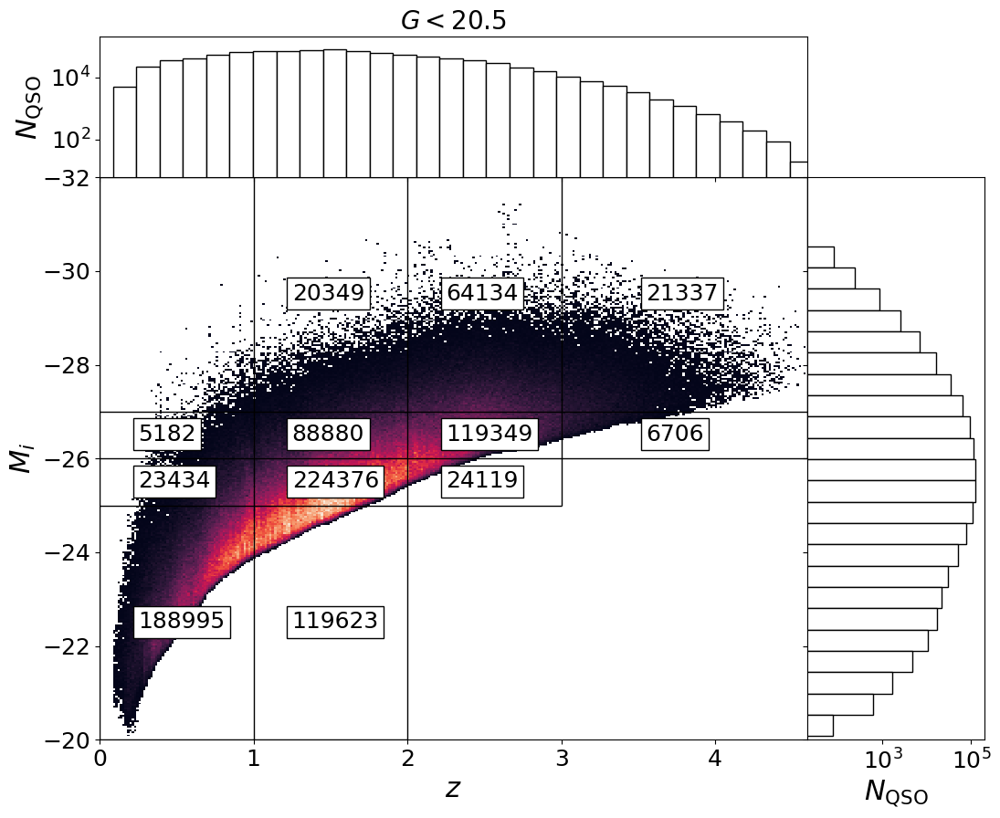

In [26]:
# plot!
fig = plt.figure(figsize = (12.5, 10))
gs = gridspec.GridSpec(2, 2, hspace = 0, height_ratios=[1,4], width_ratios=[4,1], wspace = 0)
# b = 30
# fac_rand = 25
ax1_hi = fig.add_subplot(gs[2])


# tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _ = quaia.make_bins(G_hi, 0, True, 'z', 
#                                                                                              bins = [0,4.6], tab_gcat_type = 'data', fac_rand = fac_rand, 
#                                                                                               mask_type = 'b', b = b, n_bins = None)
# quaia.absolute(tab_datahi_mask_zbin0, G_hi)

h1, xedges, yedges, image = ax1_hi.hist2d(tab_datahi_mask_zbin0['redshift_quaia'], tab_datahi_mask_zbin0['M_i'], cmap = cmap, bins = 300, 
                                       cmin = 1)

for L_bin, xmax in zip(L_array, [z_bins[2], z_bins[3], z_bins[4], z_bins[4], z_bins[4]]):
    ax1_hi.hlines(L_bin, color = 'black', xmin = z_bins[0], xmax = xmax, linewidth = 1)
for z_bin, ymax in zip(z_bins, [L_bins[0], L_bins[0], L_bins[0], L_bins[1], L_bins[2]]):
    ax1_hi.vlines(z_bin, color = 'black', ymin = -32, ymax = ymax, linewidth = 1)

ax1_hi.set_ylabel('$M_i$')
ax1_hi.set_xlabel('$z$')
ax1_hi.set_ylim(-20, -32)
ax1_hi.set_xlim(z_bins[0], z_bins[-1])

ax2_hi = fig.add_subplot(gs[0])
ax2_hi.hist(tab_datahi_mask_zbin0['redshift_quaia'], color = 'white', edgecolor = 'black', bins = 30)
ax2_hi.set_title('$G<{}$'.format(G_hi))
ax2_hi.set_ylabel('$N_\mathrm{QSO}$')
ax2_hi.set_yscale('log')
ax2_hi.set_xlim(z_bins[0], z_bins[-1])
ax2_hi.set_ylim(6,2e5)
ax2_hi.set_xticklabels([])

ax3_hi = fig.add_subplot(gs[3])
ax3_hi.hist(tab_datahi_mask_zbin0['M_i'], color = 'white', edgecolor = 'black', orientation = 'horizontal', bins = 25)

N_cut_b = []

for j in range(len(L_bins)):

    N_z=[]
    
    for i in z_array:

        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _ = quaia.make_bins(G_hi, [i, j], True, ['z', 'L'], 
                                                                                 bins = [z_bins, L_array[::-1]], tab_gcat_type = 'data', 
                                                                                  method = ['minmax', 'minmax'], fac_rand = fac_rand, 
                                                                                  mask_type = 'b', b = b, n_bins = [None, None])

        N_z.append(len(tab_datahi_mask_zbin0))

    N_cut_b.append(N_z)

for i in z_array:
    
    for j in range(len(L_bins)):

        if np.round(N_cut_b[j][i]/1000)>1:
        
            ax1_hi.text(quaia.recenter(z_bins)[i]-0.25, quaia.recenter(L_array[::-1])[j]+0.125, N_cut_b[j][i], fontsize = 18, color = 'black', bbox=dict(facecolor='white'))
        
ax3_hi.set_xlabel('$N_\mathrm{QSO}$')
ax3_hi.set_xscale('log')
ax3_hi.set_yticklabels([])
ax3_hi.set_ylim(-20, -32)
ax3_hi.set_xlim(2e1,2e5)

# plt.savefig('../figures/M_z_bins_b.pdf', bbox_inches = 'tight')

plt.show()

# Plot selection function masks

In [22]:
N = 50 #20 #65 #50 #30 #15 #80

In [20]:
NSIDE = 64
NPIX = hp.nside2npix(NSIDE)
name_catalog = '$Gaia$-$unWISE$ Quasar Catalog'

In [21]:
cmap_map = 'plasma'
cbar_ticks = [5, 10, 20]

## G20.5

In [77]:
LMC = SkyCoord(['05 23 34.6 -69 45 22'], unit=(u.hourangle, u.deg)) #https://simbad.u-strasbg.fr/simbad/sim-id?Ident=Large+Magellanic+Cloud

In [78]:
LMC_radius = 9*u.deg

In [79]:
SMC = SkyCoord(['00 52 38.0 -72 48 01'], unit=(u.hourangle, u.deg)) # https://simbad.u-strasbg.fr/simbad/sim-id?Ident=small+Magellanic+Cloud

In [80]:
SMC_radius = 5*u.deg

In [81]:
theta, phi = hp.pix2ang(NSIDE, range(NPIX), lonlat=True)
c = SkyCoord(ra=theta*u.degree, dec=phi*u.degree)
LMC_idx, _, _, _ = SkyCoord.search_around_sky(LMC, c, LMC_radius)
SMC_idx, _, _, _ = SkyCoord.search_around_sky(SMC, c, SMC_radius)
MC_idx = np.append(LMC_idx,SMC_idx)
MC_mask = np.full_like(range(NPIX), True, dtype = bool)
MC_mask[MC_idx] = False

Pixels masked by MC but not already by selfunc: 2468
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.33              218365 vs 324336
3.940797221057329 4.944497375296836
Pixels masked by MC but not already by selfunc: 4785
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.30              453228 vs 648196
8.228892185807624 10.213002345442376
Pixels masked by MC but not already by selfunc: 2764
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.28              207602 vs 286508
3.739485674706775 4.707861330501559
Pixels masked by MC but not already by selfunc: 307
G20.5_zmin3.0zmax4.6_Lmax-20.0: 0.23              28043 vs 36458
0.4741271220885251 0.6669454690573082
Pixels masked by MC but not already by selfunc: 490
G20.5_zmin0.0zmax1.0_Lmax-25.0: 0.46              29985 vs 55261
0.5091564268842362 0.7109363465532638
Pixels masked by MC but not already by selfunc: 3840
G20.5_zmin1.0zmax2.0_Lmax-25.0: 0.33              336125 vs 502242
6.096805273982156 7.580155989038678
Pixels masked by MC but not already by selfunc: 2764
G20.5_zmin2.

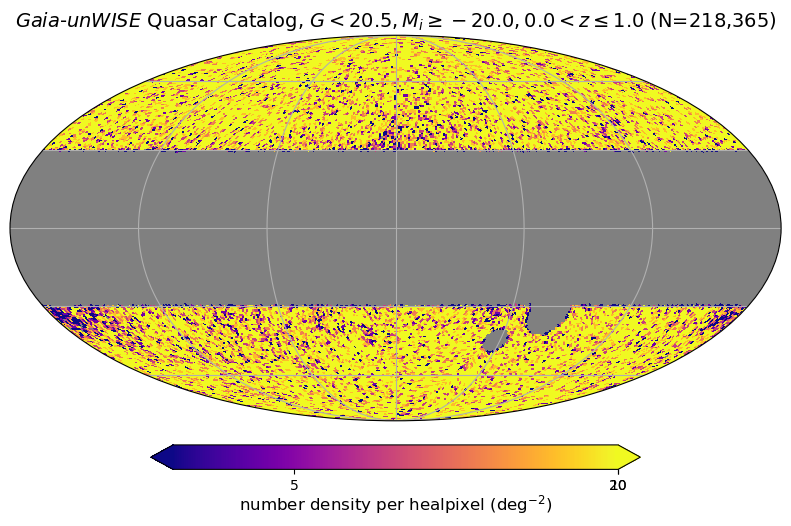

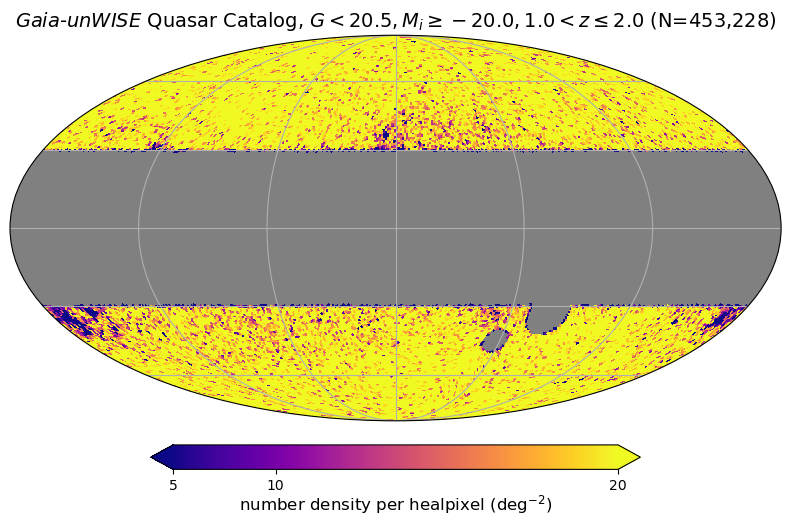

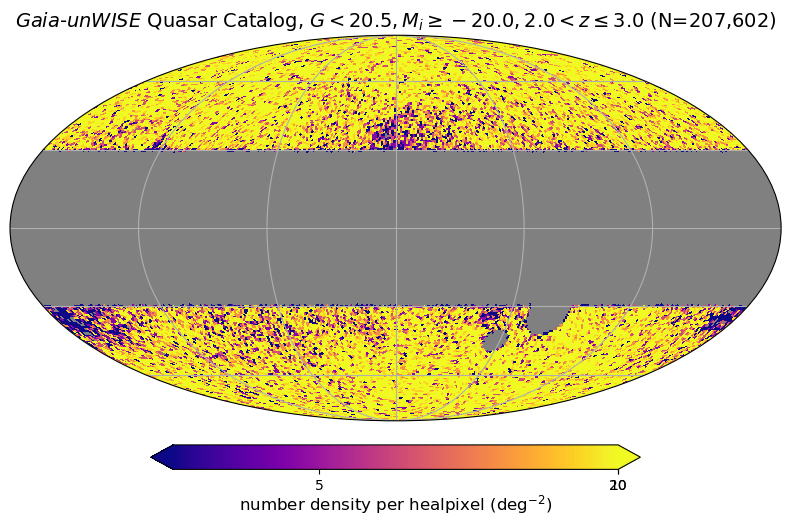

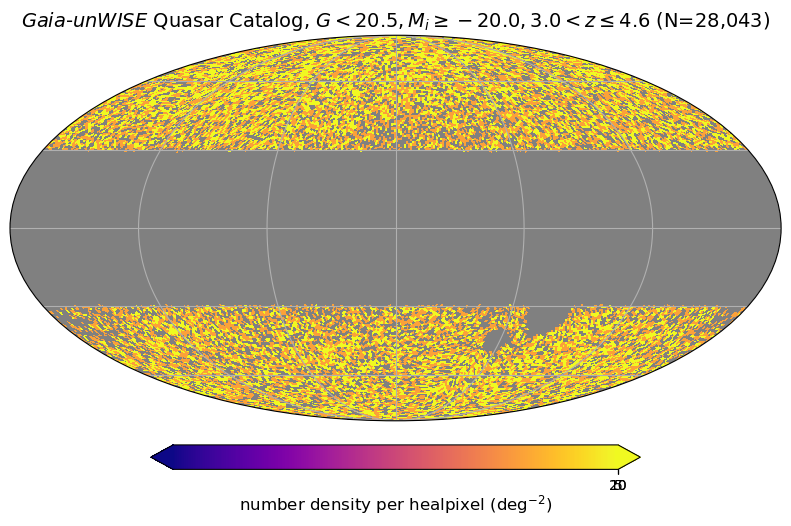

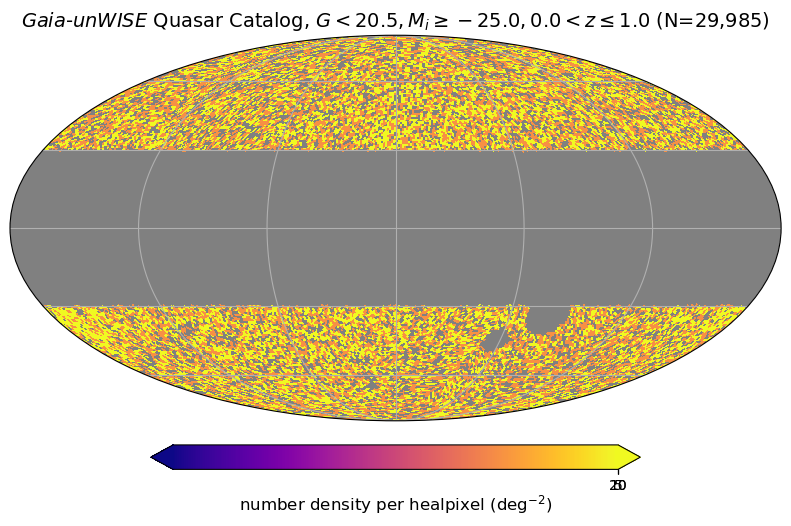

...

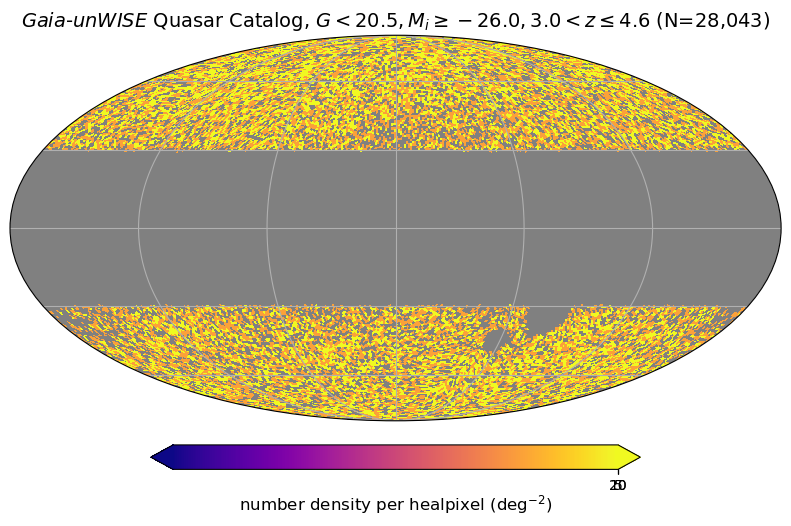

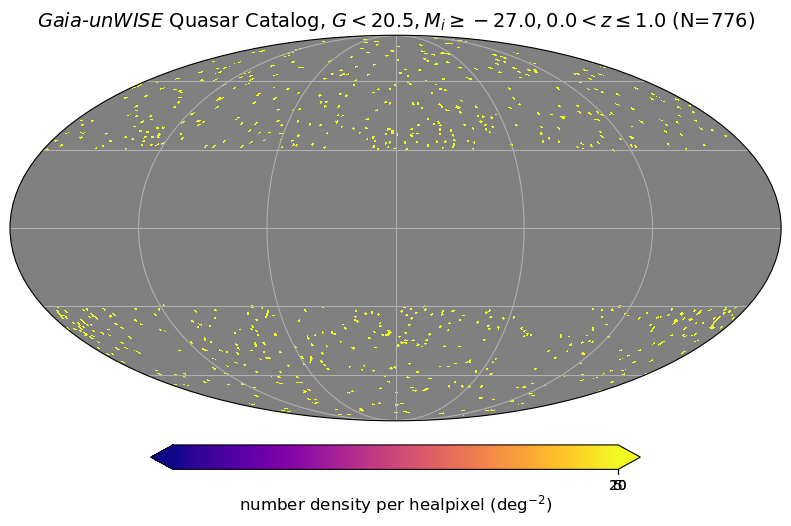

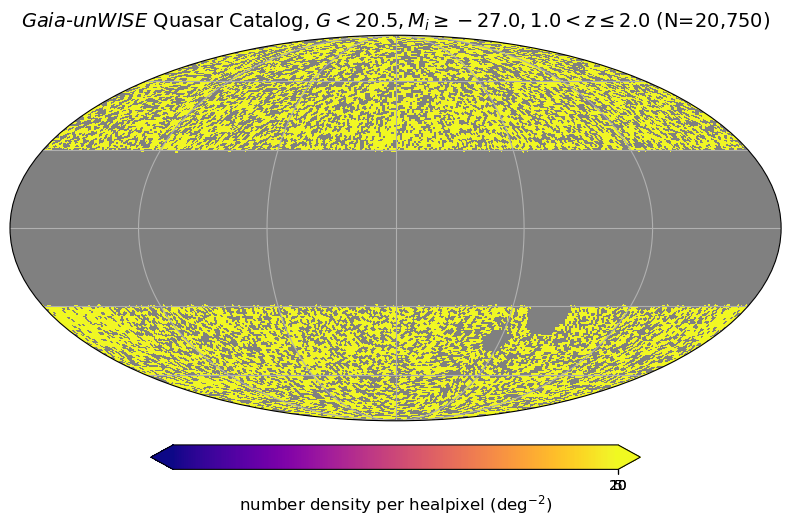

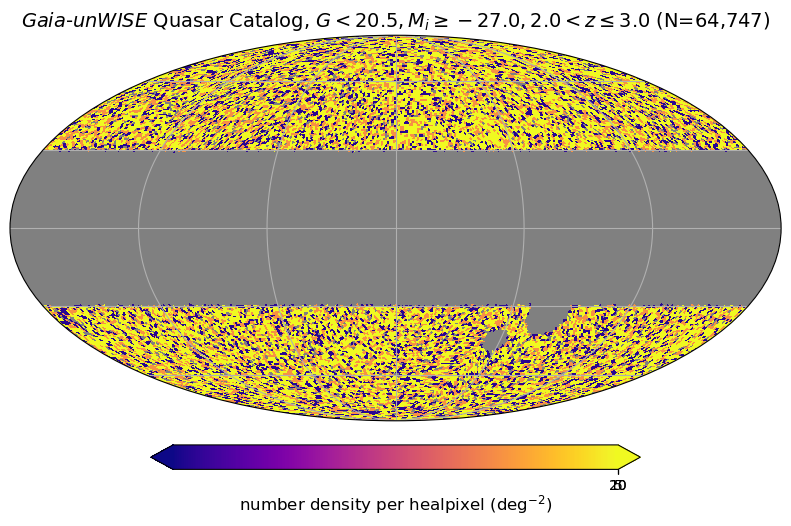

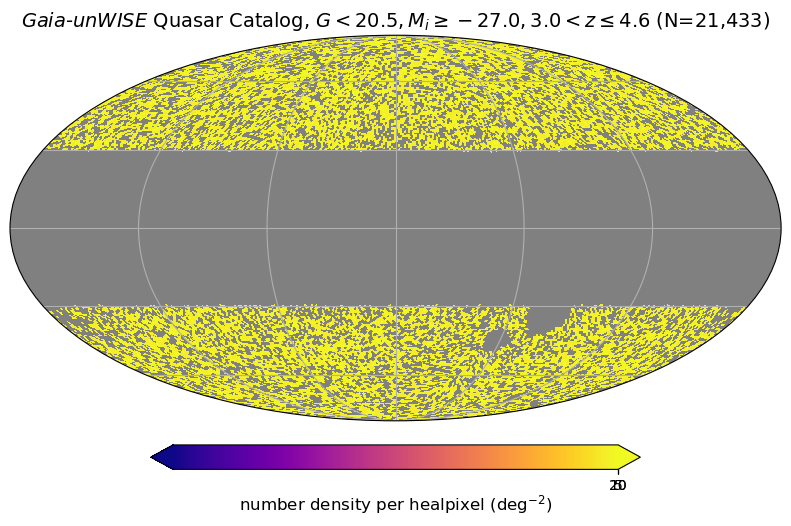

In [29]:
fac_rand = 25
fac_stdev = 0.1
for i in range(len(L_bins)):
            
    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, selfunc_hi_bin0 = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                         bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                          method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                          mask_type = 'b', b = 30, n_bins = [None, None])

        N_gcatlo_mask = len(tab_datahi_mask_zbin0)
        pixel_indices_datahi_bin0 = hp.ang2pix(NSIDE, tab_datahi_mask_zbin0['ra'], tab_datahi_mask_zbin0['dec'], lonlat=True)
        map_gcatlo = np.bincount(pixel_indices_datahi_bin0, minlength=NPIX)
        print(np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), np.mean(map_gcatlo)+fac_stdev*np.std(map_gcatlo))
        title_gcatlo = rf"{name_catalog}, $G<{G_hi}, M_i\geq{L_bins[i]}, {z_bins[j]:.1f}<z \leq{z_bins[j+1]:.1f}$ (N={N_gcatlo_mask:,})"
        projview(map_gcatlo/hp.pixelfunc.nside2pixarea(NSIDE, degrees = True), title=title_gcatlo,
                    unit=r"number density per healpixel (deg$^{-2})$", cmap=cmap_map, coord=['C','G'],
                    min=np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), max=np.mean(map_gcatlo)+10*fac_stdev*np.std(map_gcatlo), 
                norm='log', graticule=True, cbar_ticks=cbar_ticks, graticule_labels=False) #True

Pixels masked by MC but not already by selfunc: 3194
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.01              321142 vs 324336
6.100357525056854 6.966943907234812
Pixels masked by MC but not already by selfunc: 6208
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.01              641988 vs 648196
12.22679440404088 13.89576418970912
Pixels masked by MC but not already by selfunc: 3576
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.01              282932 vs 286508
5.322589700340599 6.189942851742735
Pixels masked by MC but not already by selfunc: 386
G20.5_zmin3.0zmax4.6_Lmax-20.0: 0.01              36072 vs 36458
0.6340809602539831 0.8336924772460169
Pixels masked by MC but not already by selfunc: 633
G20.5_zmin0.0zmax1.0_Lmax-25.0: 0.01              54628 vs 55261
0.9940867347129998 1.2287322757036667
Pixels masked by MC but not already by selfunc: 5036
G20.5_zmin1.0zmax2.0_Lmax-25.0: 0.01              497206 vs 502242
9.486649364911504 10.744714567380164
Pixels masked by MC but not already by selfunc: 3576
G20.5_zmin2.

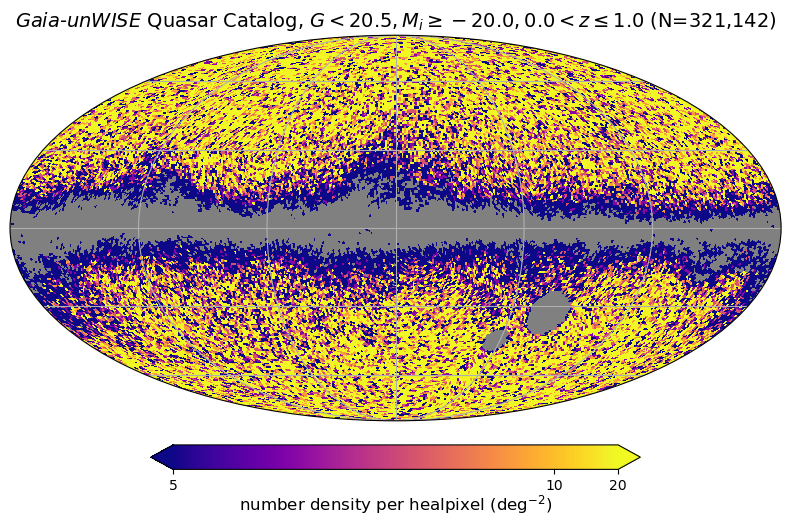

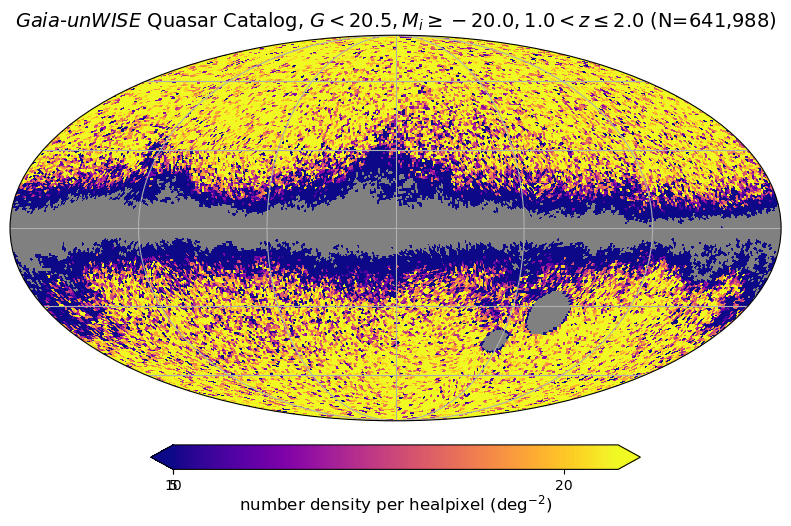

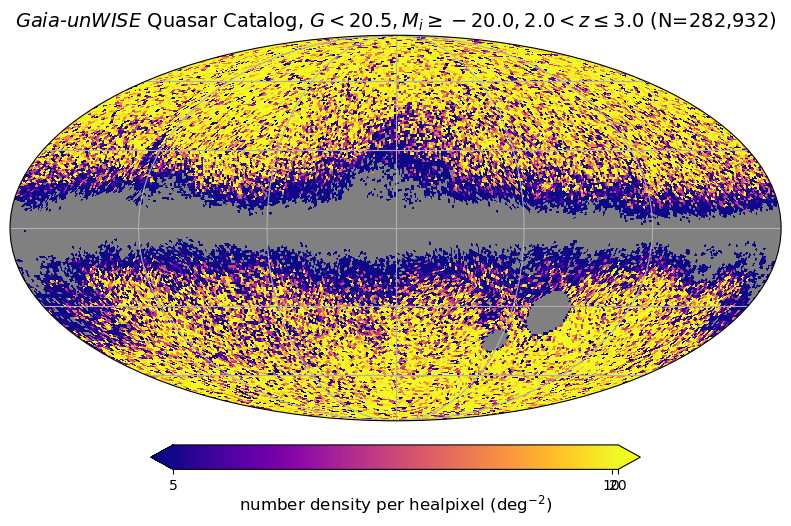

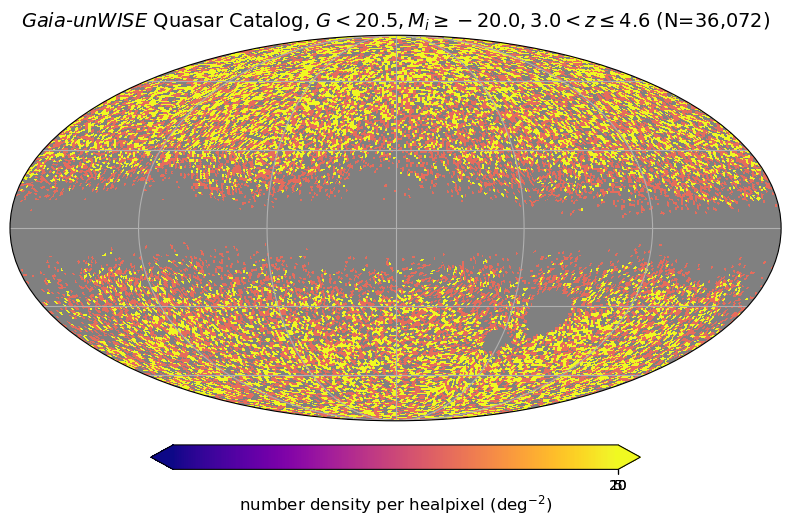

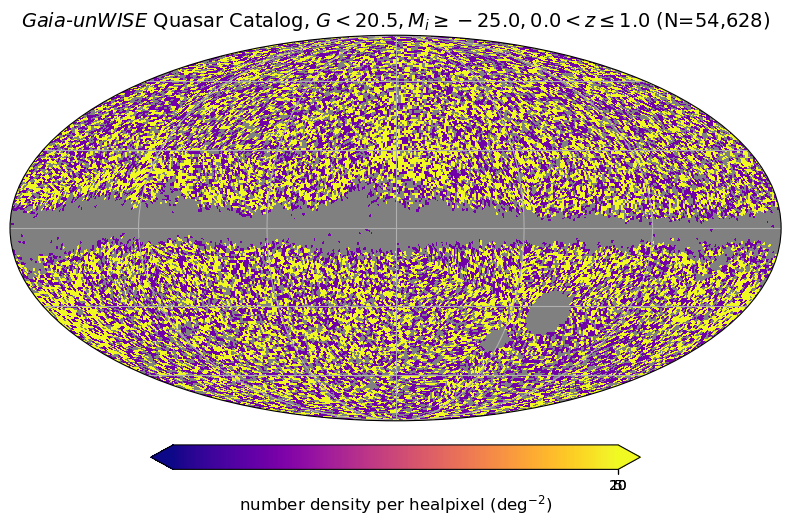

...

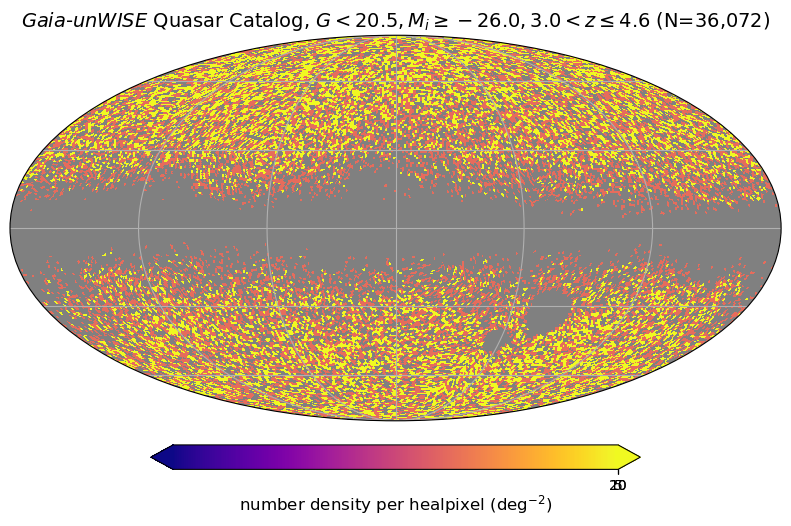

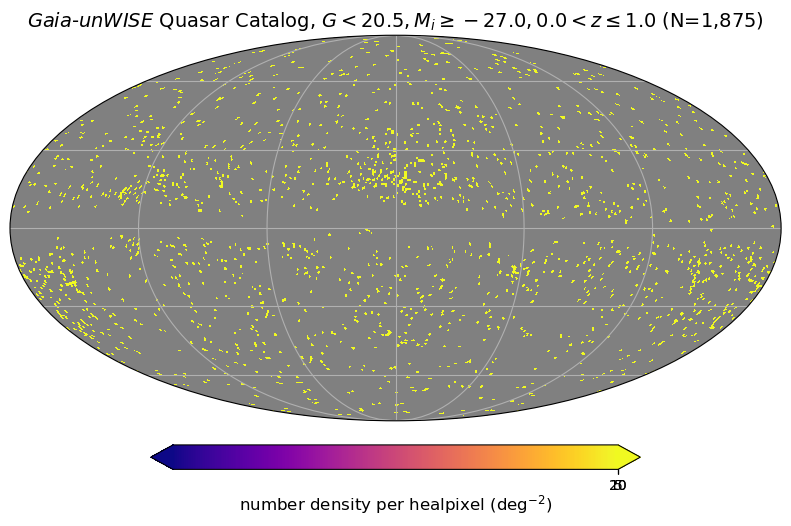

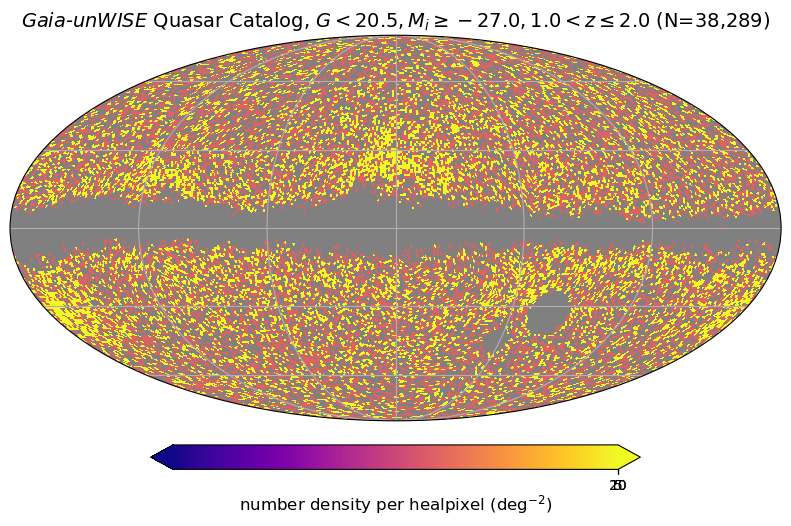

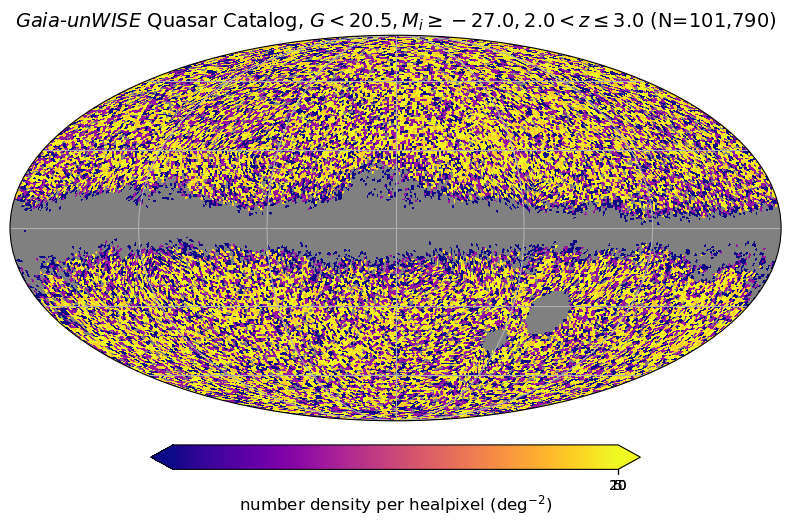

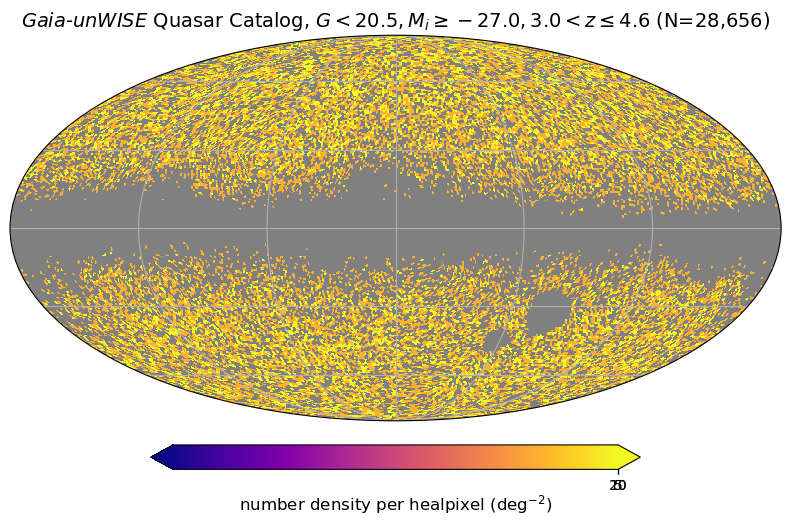

In [30]:
fac_rand = 25
fac_stdev = 0.1
for i in range(len(L_bins)):
            
    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, selfunc_hi_bin0 = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                         bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                          method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                          mask_type = 'b', n_bins = [None, None])

        N_gcatlo_mask = len(tab_datahi_mask_zbin0)
        pixel_indices_datahi_bin0 = hp.ang2pix(NSIDE, tab_datahi_mask_zbin0['ra'], tab_datahi_mask_zbin0['dec'], lonlat=True)
        map_gcatlo = np.bincount(pixel_indices_datahi_bin0, minlength=NPIX)
        print(np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), np.mean(map_gcatlo)+fac_stdev*np.std(map_gcatlo))
        title_gcatlo = rf"{name_catalog}, $G<{G_hi}, M_i\geq{L_bins[i]}, {z_bins[j]:.1f}<z \leq{z_bins[j+1]:.1f}$ (N={N_gcatlo_mask:,})"
        projview(map_gcatlo/hp.pixelfunc.nside2pixarea(NSIDE, degrees = True), title=title_gcatlo,
                    unit=r"number density per healpixel (deg$^{-2})$", cmap=cmap_map, coord=['C','G'],
                    min=np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), max=np.mean(map_gcatlo)+10*fac_stdev*np.std(map_gcatlo), 
                norm='log', graticule=True, cbar_ticks=cbar_ticks, graticule_labels=False) #True

Pixels masked by MC but not already by selfunc: 0
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.00              324336 vs 324336
6.167971551259819 7.029294073740181
Pixels masked by MC but not already by selfunc: 0
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.00              648196 vs 648196
12.359020604083884 14.016142156332783
Pixels masked by MC but not already by selfunc: 0
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.00              286508 vs 286508
5.395528244730168 6.262512119853166
Pixels masked by MC but not already by selfunc: 0
G20.5_zmin3.0zmax4.6_Lmax-20.0: 0.00              36458 vs 36458
0.6416812850843313 0.841798532624002
Pixels masked by MC but not already by selfunc: 0
G20.5_zmin0.0zmax1.0_Lmax-25.0: 0.00              55261 vs 55261
1.0064565970766537 1.2421192492775128
Pixels masked by MC but not already by selfunc: 0
G20.5_zmin1.0zmax2.0_Lmax-25.0: 0.00              502242 vs 502242
9.593614909427338 10.842664387447662
Pixels masked by MC but not already by selfunc: 0
G20.5_zmin2.0zmax3.0_Lmax-25.0

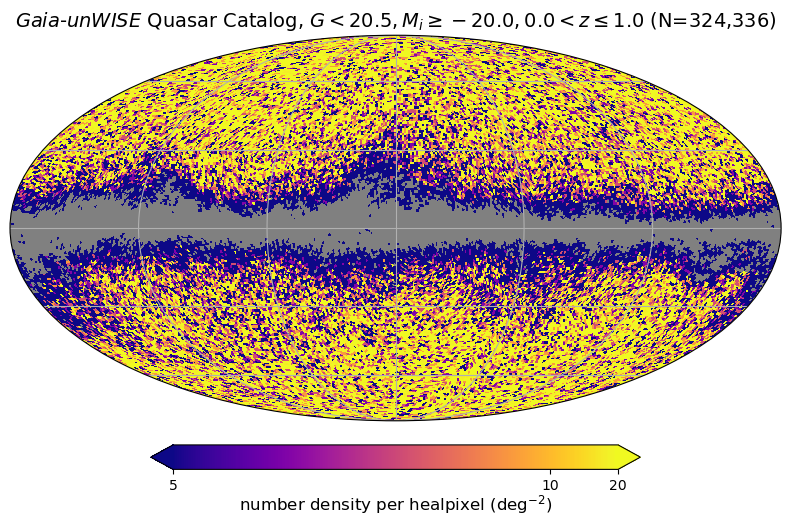

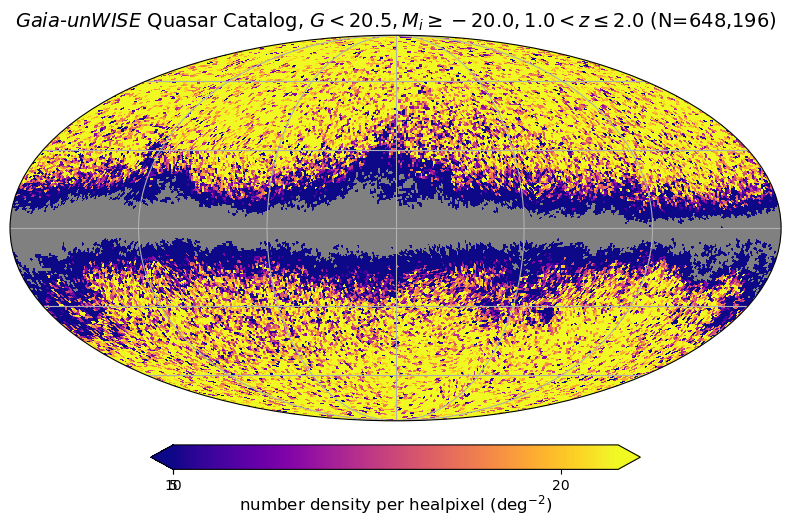

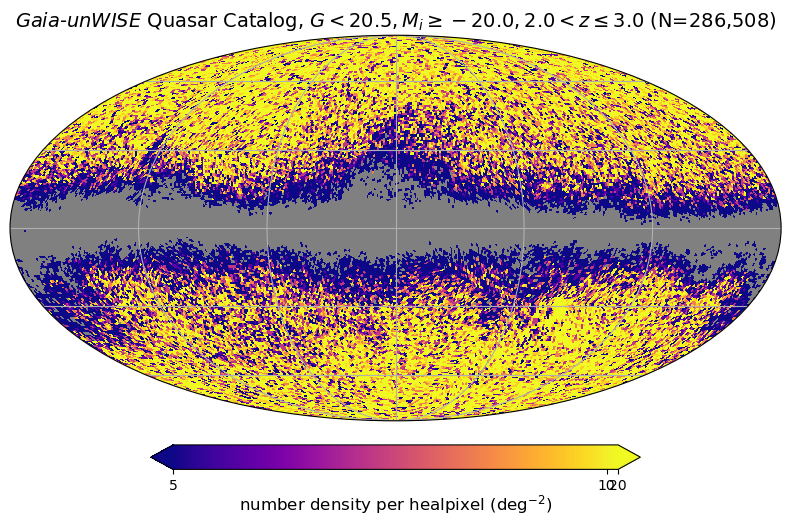

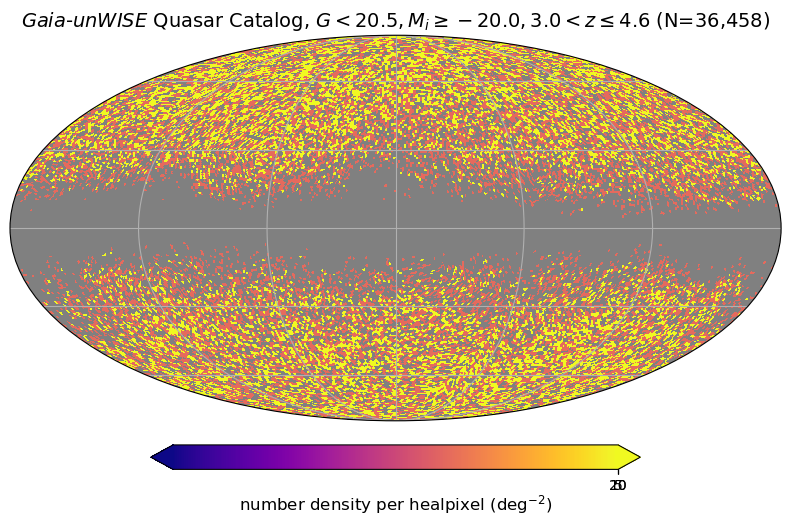

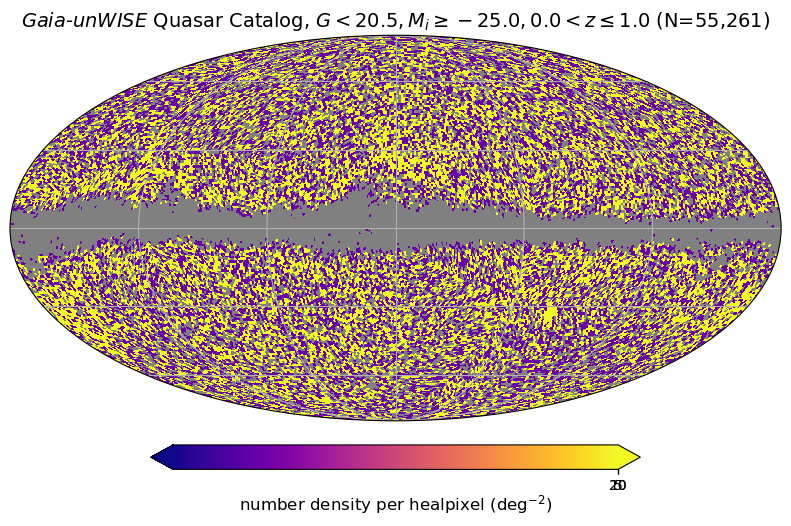

...

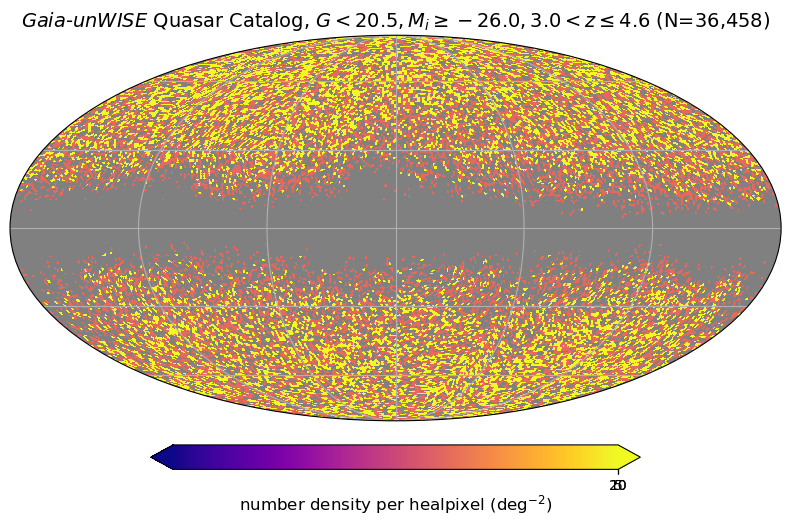

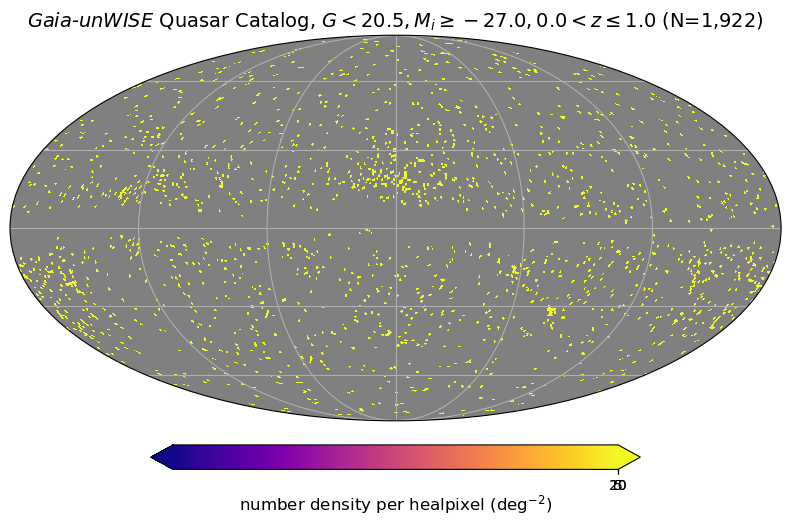

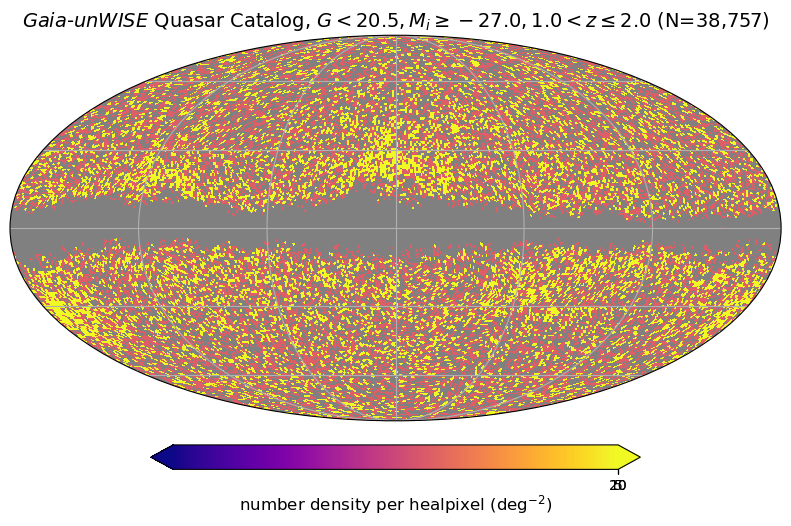

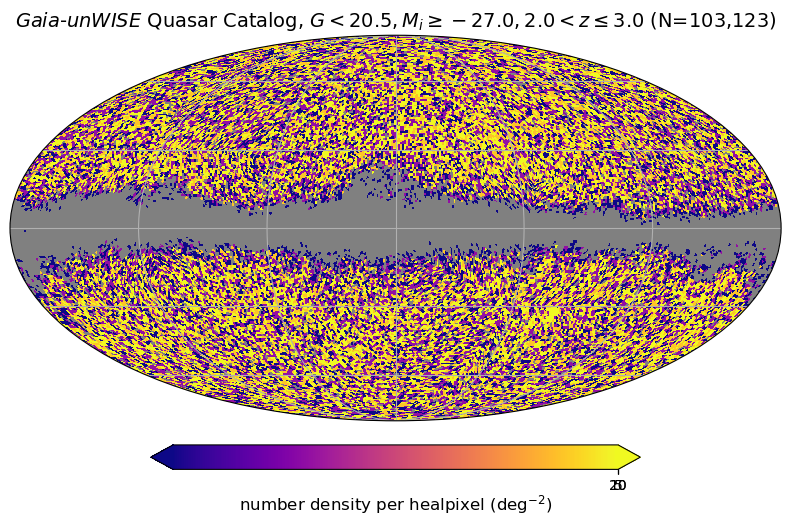

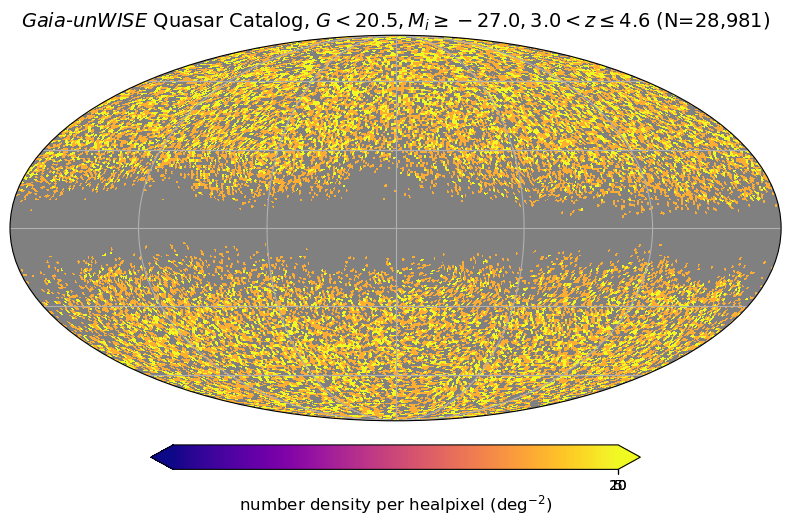

In [31]:
fac_rand = 25
fac_stdev = 0.1
for i in range(len(L_bins)):
            
    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, selfunc_hi_bin0 = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                         bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                          method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                          mask_type = 'b', n_bins = [None, None], MC = '_')

        N_gcatlo_mask = len(tab_datahi_mask_zbin0)
        pixel_indices_datahi_bin0 = hp.ang2pix(NSIDE, tab_datahi_mask_zbin0['ra'], tab_datahi_mask_zbin0['dec'], lonlat=True)
        map_gcatlo = np.bincount(pixel_indices_datahi_bin0, minlength=NPIX)
        print(np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), np.mean(map_gcatlo)+fac_stdev*np.std(map_gcatlo))
        title_gcatlo = rf"{name_catalog}, $G<{G_hi}, M_i\geq{L_bins[i]}, {z_bins[j]:.1f}<z \leq{z_bins[j+1]:.1f}$ (N={N_gcatlo_mask:,})"
        projview(map_gcatlo/hp.pixelfunc.nside2pixarea(NSIDE, degrees = True), title=title_gcatlo,
                    unit=r"number density per healpixel (deg$^{-2})$", cmap=cmap_map, coord=['C','G'],
                    min=np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), max=np.mean(map_gcatlo)+10*fac_stdev*np.std(map_gcatlo), 
                norm='log', graticule=True, cbar_ticks=cbar_ticks, graticule_labels=False) #True

Pixels masked by MC but not already by selfunc: 0
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.00              324336 vs 324336
3.5840039838187336 9.613261641181266
Pixels masked by MC but not already by selfunc: 0
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.00              648196 vs 648196
7.38765594733719 18.987506813079477
Pixels masked by MC but not already by selfunc: 0
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.00              286508 vs 286508
2.7945766193611736 8.86346374522216
Pixels masked by MC but not already by selfunc: 0
G20.5_zmin3.0zmax4.6_Lmax-20.0: 0.00              36458 vs 36458
0.04132954246531928 1.442150275243014


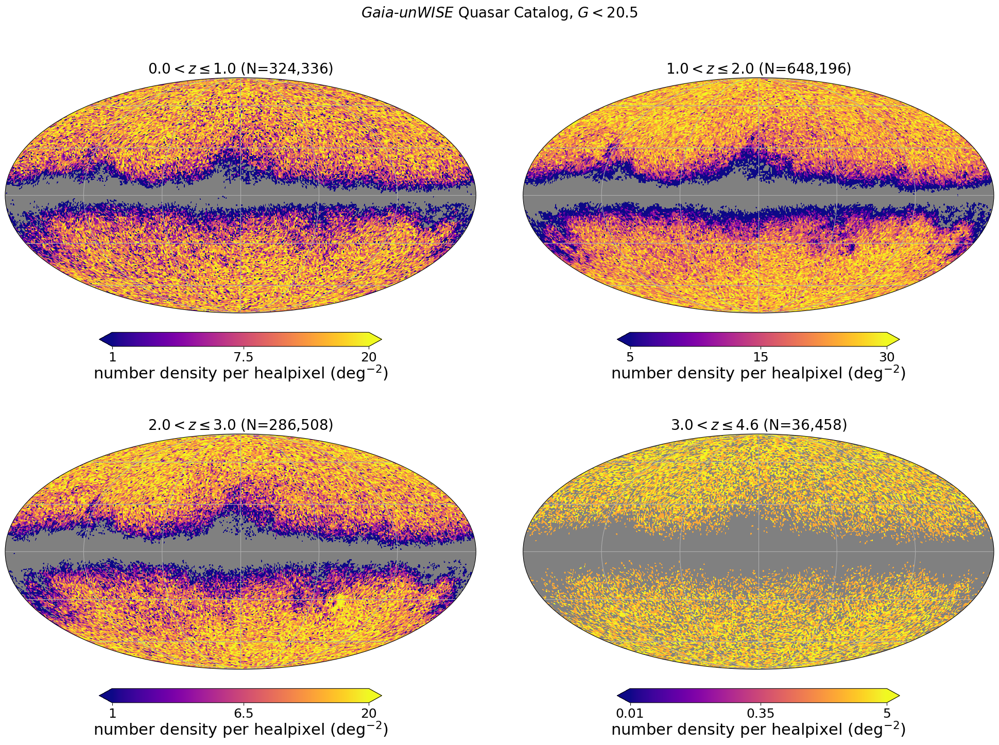

In [71]:
fig = plt.figure(figsize = (20, 16))

fac_rand = 25
fac_stdev = 0.7
i = 0
ticks = [[1, 7.5, 20], [5, 15, 30], [1, 6.5, 20], [0.01, 0.35, 5]]

for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, selfunc_hi_bin0 = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                     bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                      method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                      mask_type = 'b', n_bins = [None, None], MC = '_')
    

    N_gcatlo_mask = len(tab_datahi_mask_zbin0)
    pixel_indices_datahi_bin0 = hp.ang2pix(NSIDE, tab_datahi_mask_zbin0['ra'], tab_datahi_mask_zbin0['dec'], lonlat=True)
    map_gcatlo = np.bincount(pixel_indices_datahi_bin0, minlength=NPIX)
    print(np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), np.mean(map_gcatlo)+fac_stdev*np.std(map_gcatlo))
    title_gcatlo = rf"${z_bins[j]:.1f}<z \leq{z_bins[j+1]:.1f}$ (N={N_gcatlo_mask:,})"
    
    # ticks = np.round(quaia.recenter(np.logspace(np.log10(1), 
    #                           np.log10(np.max(map_gcatlo/hp.pixelfunc.nside2pixarea(NSIDE, degrees = True))), 4)))
    
    projview(map_gcatlo/hp.pixelfunc.nside2pixarea(NSIDE, degrees = True), title=title_gcatlo,
                    unit=r"number density per healpixel (deg$^{-2})$", cmap=cmap_map, coord=['C','G'],
                min=np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), max=np.mean(map_gcatlo)+2*np.std(map_gcatlo), 
            norm='log', graticule=True, cbar_ticks=ticks[j], graticule_labels=False, fig = fig, sub = (2,2,j+1), fontsize={"title": 20,
                   "cbar_label": 22,
                   "cbar_tick_label": 18}) #True
    
fig.suptitle(rf"{name_catalog}, $G<{G_hi}$", fontsize=20, y = 0.95) #, M_i\geq{L_bins[i]}
fig.subplots_adjust(wspace=0.1, hspace=-0.075)
plt.savefig('../figures/quaia_z.pdf', bbox_inches = 'tight')

In [82]:
b = 30
selfunc_mask = np.abs(c.galactic.b.value)>=b

Pixels masked by MC but not already by selfunc: 2468
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.33              218365 vs 324336
Pixels masked by MC but not already by selfunc: 4785
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.30              453228 vs 648196
Pixels masked by MC but not already by selfunc: 2764
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.28              207602 vs 286508
Pixels masked by MC but not already by selfunc: 307
G20.5_zmin3.0zmax4.6_Lmax-20.0: 0.23              28043 vs 36458
Pixels masked by MC but not already by selfunc: 490
G20.5_zmin0.0zmax1.0_Lmax-25.0: 0.46              29985 vs 55261
Pixels masked by MC but not already by selfunc: 3840
G20.5_zmin1.0zmax2.0_Lmax-25.0: 0.33              336125 vs 502242
Pixels masked by MC but not already by selfunc: 2764
G20.5_zmin2.0zmax3.0_Lmax-25.0: 0.28              207602 vs 286508
Pixels masked by MC but not already by selfunc: 307
G20.5_zmin3.0zmax4.6_Lmax-25.0: 0.23              28043 vs 36458
Pixels masked by MC but not already by selfunc: 1

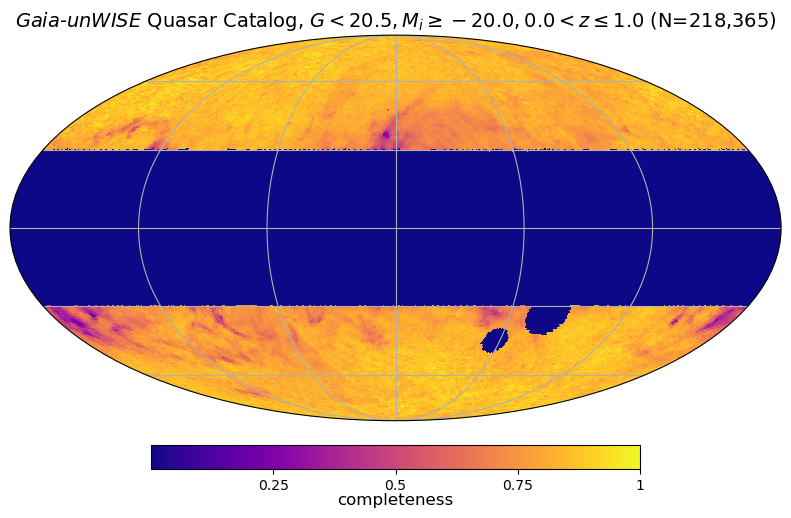

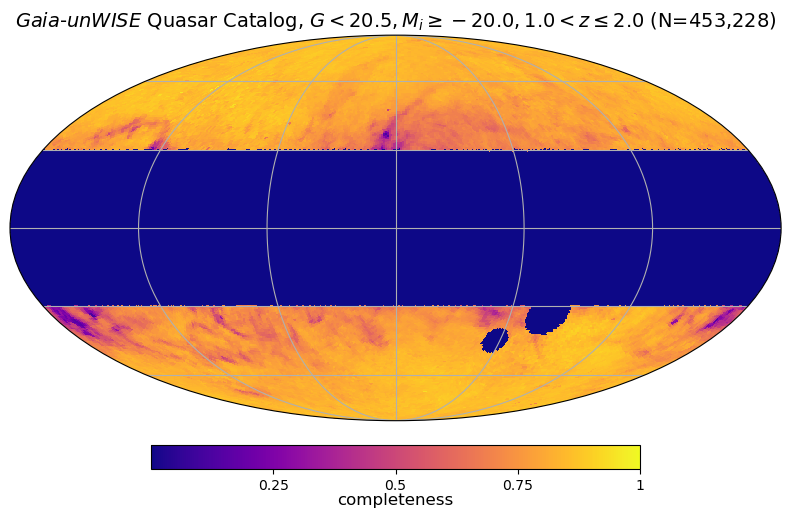

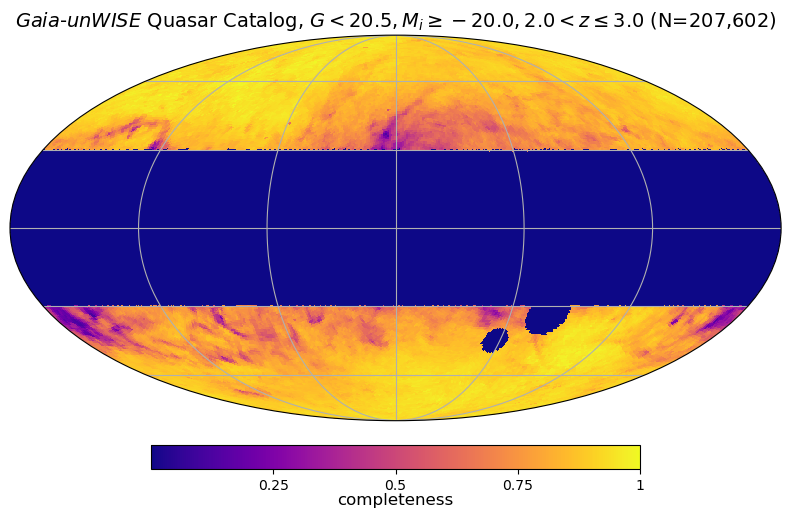

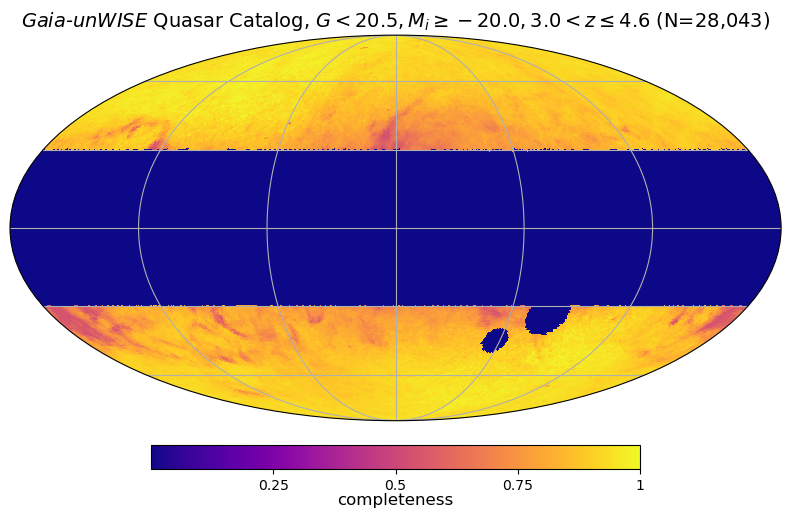

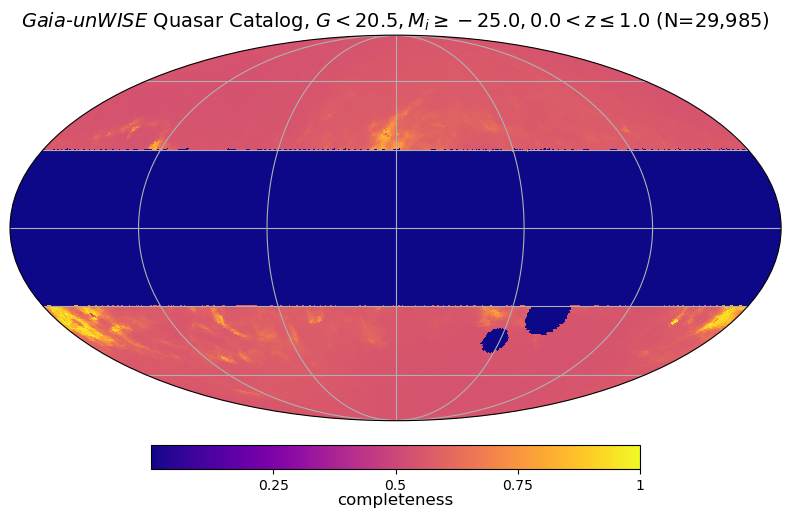

...

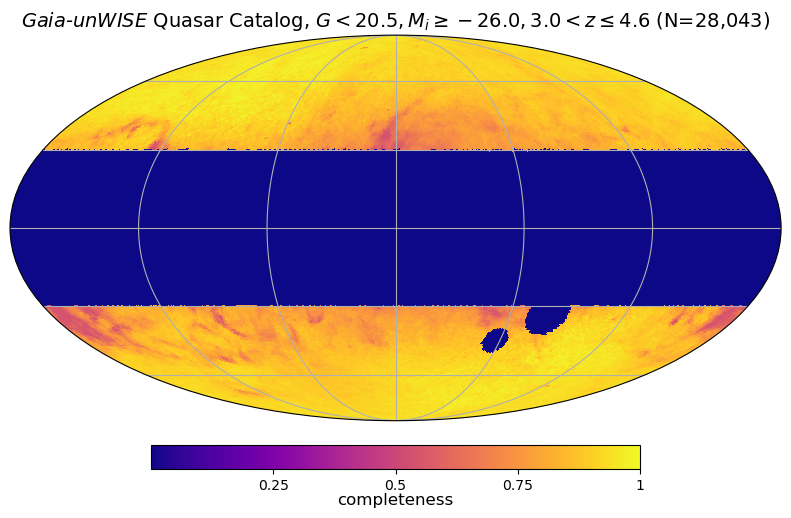

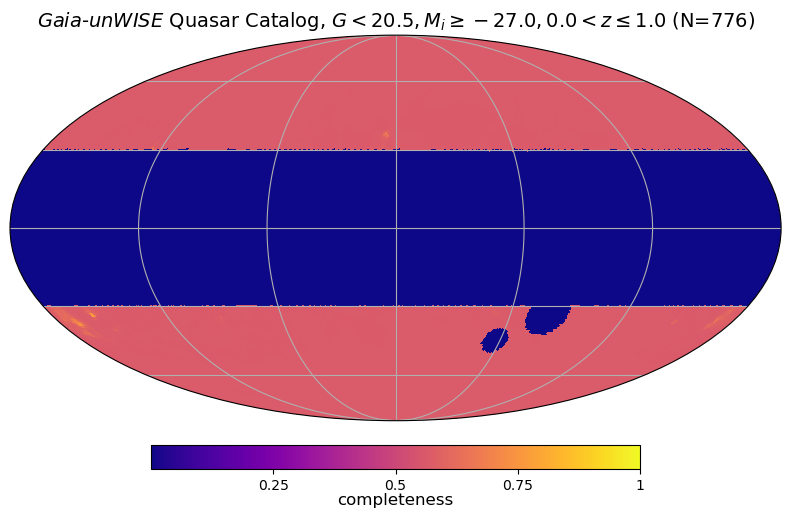

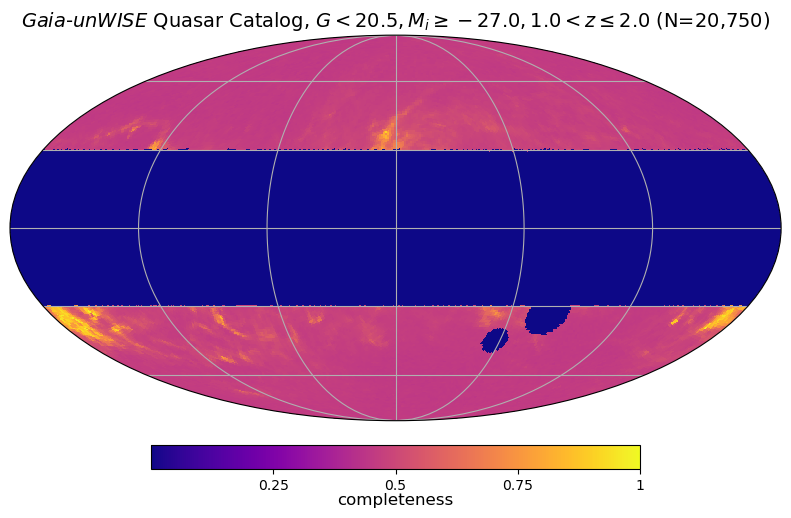

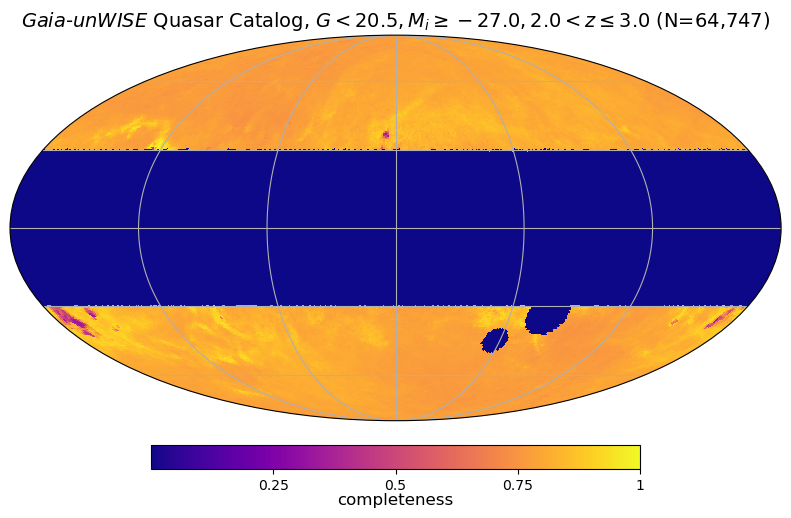

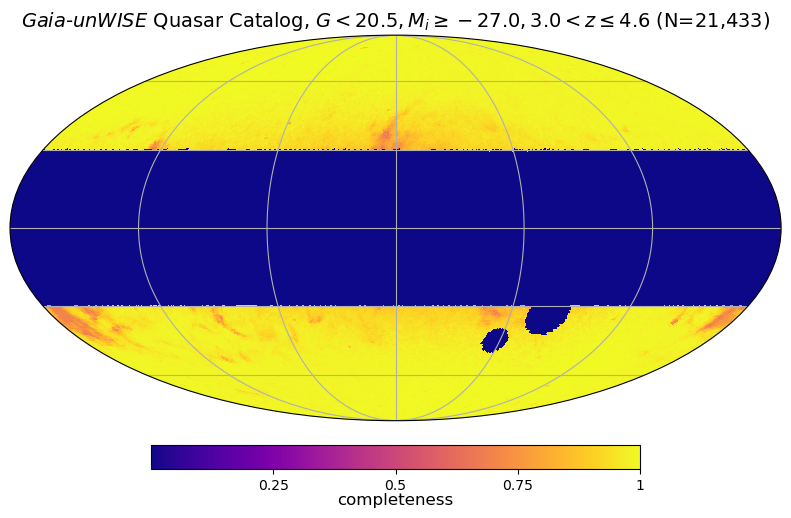

In [83]:
fac_rand = 25
fac_stdev = 0.1
for i in range(len(L_bins)):
            
    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, _, _ = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                         bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                          method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                          mask_type = 'b', b = b, n_bins = [None, None])

        selfunc_hi_bin0[~selfunc_mask | ~MC_mask] = 0
        
        N_gcatlo_mask = len(tab_datahi_mask_zbin0)
        title_gcatlo = rf"{name_catalog}, $G<{G_hi}, M_i\geq{L_bins[i]}, {z_bins[j]:.1f}<z \leq{z_bins[j+1]:.1f}$ (N={N_gcatlo_mask:,})"
        projview(selfunc_hi_bin0, title=title_gcatlo,
                    unit=r"completeness", cmap=cmap_map, coord=['C','G'],
                    min=0, max = 1, 
                    graticule=True, cbar_ticks=[0.25, 0.5, 0.75, 1.0], graticule_labels=False) #True

Pixels masked by MC but not already by selfunc: 2468
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.33              218365 vs 324336
Pixels masked by MC but not already by selfunc: 4785
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.30              453228 vs 648196
Pixels masked by MC but not already by selfunc: 2764
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.28              207602 vs 286508
Pixels masked by MC but not already by selfunc: 307
G20.5_zmin3.0zmax4.6_Lmax-20.0: 0.23              28043 vs 36458


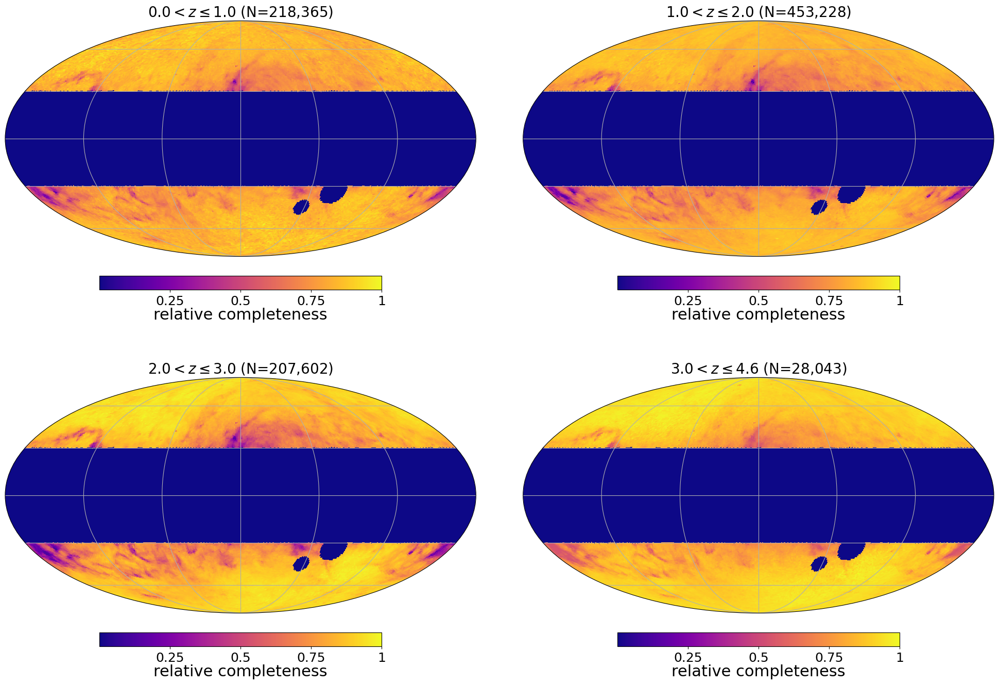

In [98]:
fig = plt.figure(figsize = (20, 16))
i = 0

for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, _, _ = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                         bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                          method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                          mask_type = 'b', b = b, n_bins = [None, None])

    selfunc_hi_bin0[~selfunc_mask | ~MC_mask] = 0

    N_gcatlo_mask = len(tab_datahi_mask_zbin0)
    title_gcatlo = rf"${z_bins[j]:.1f}<z \leq{z_bins[j+1]:.1f}$ (N={N_gcatlo_mask:,})"
    projview(selfunc_hi_bin0, title=title_gcatlo,
                unit=r"relative completeness", cmap=cmap_map, coord=['C','G'],
                min=0, max = 1, 
                graticule=True, cbar_ticks=[0.25, 0.5, 0.75, 1.0], graticule_labels=False, fig = fig, sub = (2,2,j+1), fontsize={"title": 20,
                   "cbar_label": 22,
                   "cbar_tick_label": 18}) #True
    
# fig.suptitle(rf"Selection function model, $G<{G_hi}$", fontsize=20, y = 0.95) #, M_i\geq{L_bins[i]}
fig.subplots_adjust(wspace=0.1, hspace=-0.075)
plt.savefig('../figures/quaia_z_selfunc_MC_b.pdf', bbox_inches = 'tight')

In [ ]:
fig = plt.figure(figsize = (20, 16))
i = 0

for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0,_, _ = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                         bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                          method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                          mask_type = 'b', n_bins = [None, None])

    selfunc_hi_bin0[~MC_mask] = 0

    N_gcatlo_mask = len(tab_datahi_mask_zbin0)
    title_gcatlo = rf"${z_bins[j]:.1f}<z \leq{z_bins[j+1]:.1f}$ (N={N_gcatlo_mask:,})"
    projview(selfunc_hi_bin0, title=title_gcatlo,
                unit=r"relative completeness", cmap=cmap_map, coord=['C','G'],
                min=0, max = 1, 
                graticule=True, cbar_ticks=[0.25, 0.5, 0.75, 1.0], graticule_labels=False, fig = fig, sub = (2,2,j+1), fontsize={"title": 20,
                   "cbar_label": 22,
                   "cbar_tick_label": 18}) #True
    
fig.suptitle(rf"Selection function model, $G<{G_hi}$", fontsize=20, y = 0.95) #, M_i\geq{L_bins[i]}
fig.subplots_adjust(wspace=0.1, hspace=-0.075)
plt.savefig('../figures/quaia_z_selfunc_MC.pdf', bbox_inches = 'tight')

Pixels masked by MC but not already by selfunc: 3194
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.01              321142 vs 324336
Pixels masked by MC but not already by selfunc: 6208
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.01              641988 vs 648196
Pixels masked by MC but not already by selfunc: 3576
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.01              282932 vs 286508
Pixels masked by MC but not already by selfunc: 386
G20.5_zmin3.0zmax4.6_Lmax-20.0: 0.01              36072 vs 36458


Pixels masked by MC but not already by selfunc: 0
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.00              324336 vs 324336
Pixels masked by MC but not already by selfunc: 0
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.00              648196 vs 648196
Pixels masked by MC but not already by selfunc: 0
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.00              286508 vs 286508
Pixels masked by MC but not already by selfunc: 0
G20.5_zmin3.0zmax4.6_Lmax-20.0: 0.00              36458 vs 36458


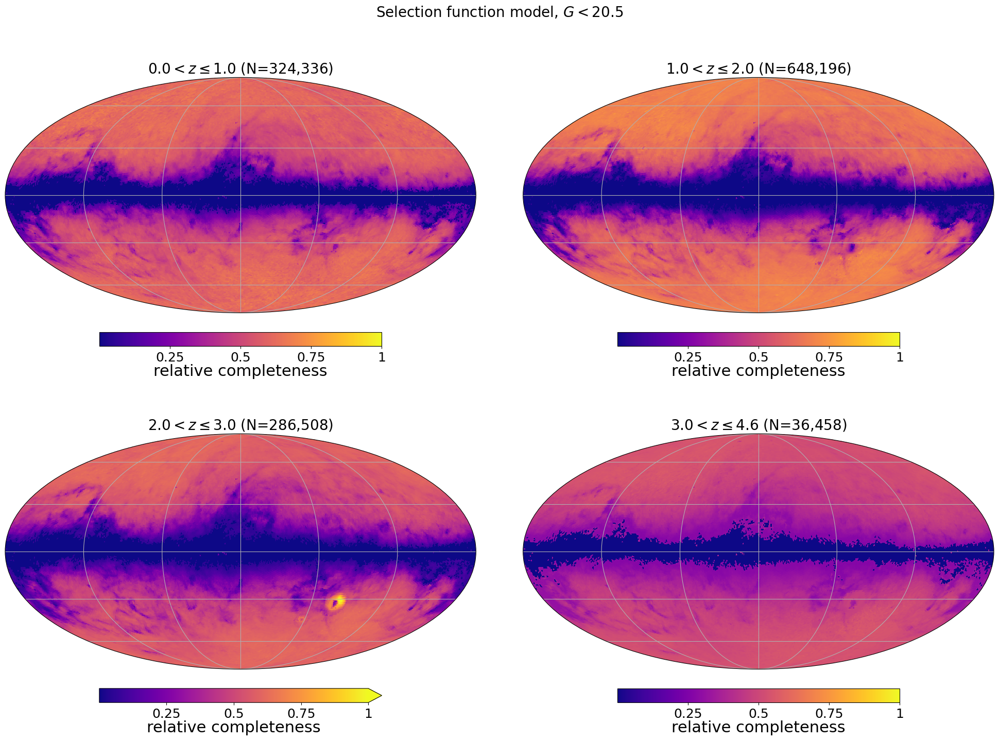

In [100]:
fig = plt.figure(figsize = (20, 16))
i = 0

for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0,_, _ = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                         bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                          method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                          mask_type = 'b', n_bins = [None, None], MC = '_')

    # selfunc_hi_bin0[~selfunc_mask | ~MC_mask] = 0

    N_gcatlo_mask = len(tab_datahi_mask_zbin0)
    title_gcatlo = rf"${z_bins[j]:.1f}<z \leq{z_bins[j+1]:.1f}$ (N={N_gcatlo_mask:,})"
    projview(selfunc_hi_bin0, title=title_gcatlo,
                unit=r"relative completeness", cmap=cmap_map, coord=['C','G'],
                min=0, max = 1, 
                graticule=True, cbar_ticks=[0.25, 0.5, 0.75, 1.0], graticule_labels=False, fig = fig, sub = (2,2,j+1), fontsize={"title": 20,
                   "cbar_label": 22,
                   "cbar_tick_label": 18}) #, extend='neither') #True
    
fig.suptitle(rf"Selection function model, $G<{G_hi}$", fontsize=20, y = 0.95) #, M_i\geq{L_bins[i]}
fig.subplots_adjust(wspace=0.1, hspace=-0.075)
plt.savefig('../figures/quaia_z_selfunc.pdf', bbox_inches = 'tight')

Pixels masked by MC but not already by selfunc: 3194
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.01              321142 vs 324336
Pixels masked by MC but not already by selfunc: 6208
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.01              641988 vs 648196
Pixels masked by MC but not already by selfunc: 3576
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.01              282932 vs 286508
Pixels masked by MC but not already by selfunc: 386
G20.5_zmin3.0zmax4.6_Lmax-20.0: 0.01              36072 vs 36458
Pixels masked by MC but not already by selfunc: 633
G20.5_zmin0.0zmax1.0_Lmax-25.0: 0.01              54628 vs 55261
Pixels masked by MC but not already by selfunc: 5036
G20.5_zmin1.0zmax2.0_Lmax-25.0: 0.01              497206 vs 502242
Pixels masked by MC but not already by selfunc: 3576
G20.5_zmin2.0zmax3.0_Lmax-25.0: 0.01              282932 vs 286508
Pixels masked by MC but not already by selfunc: 386
G20.5_zmin3.0zmax4.6_Lmax-25.0: 0.01              36072 vs 36458
Pixels masked by MC but not already by selfunc: 1

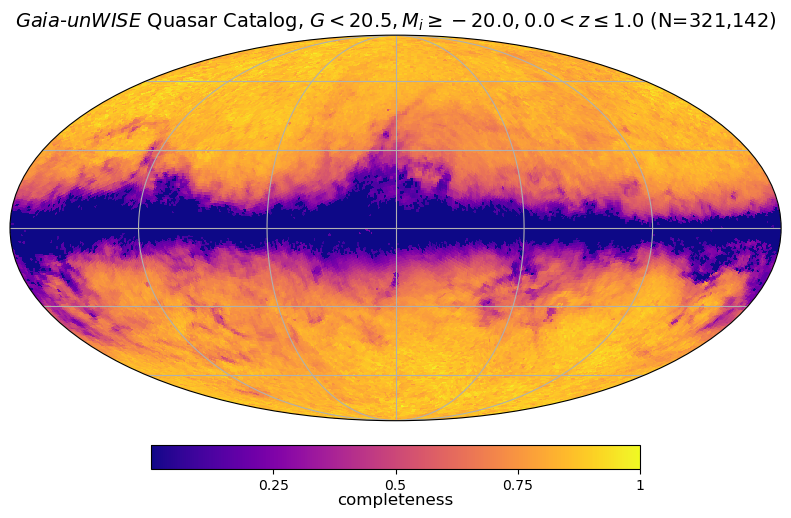

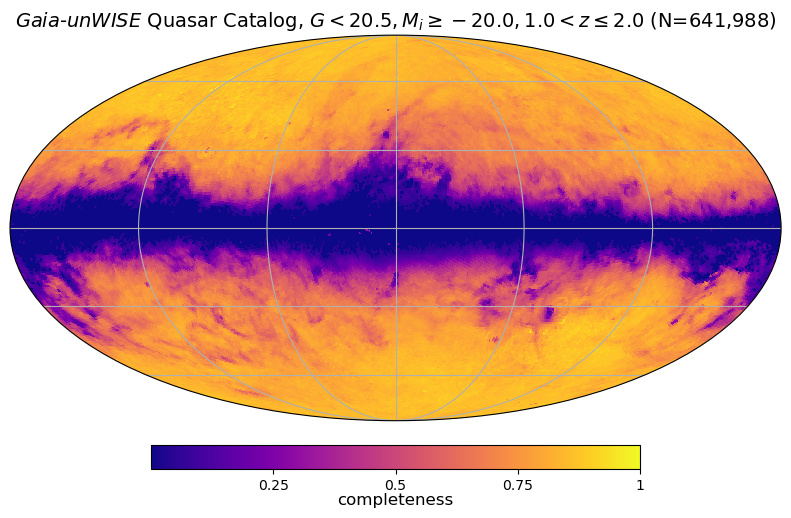

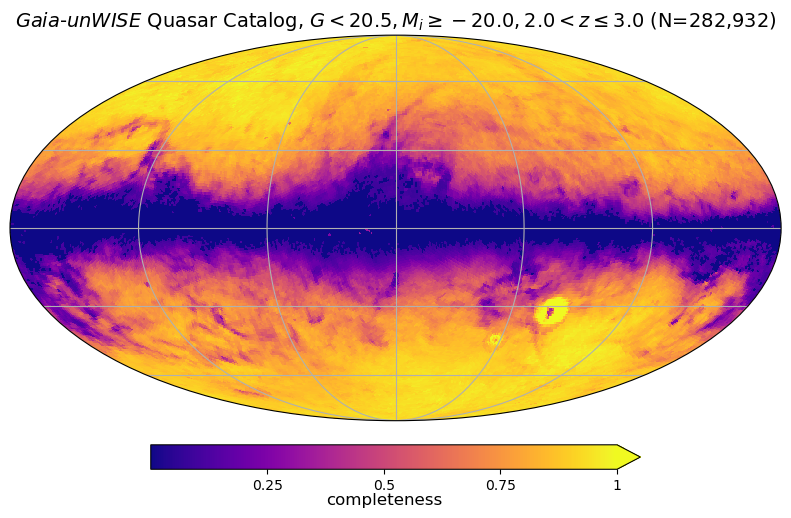

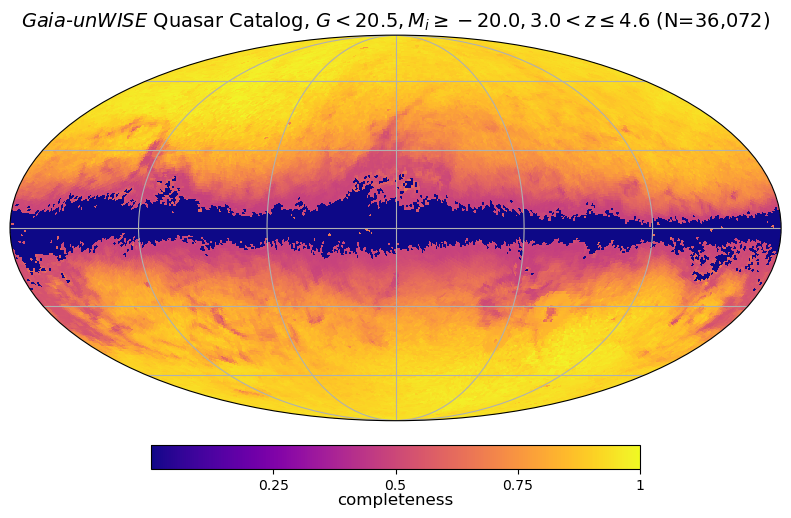

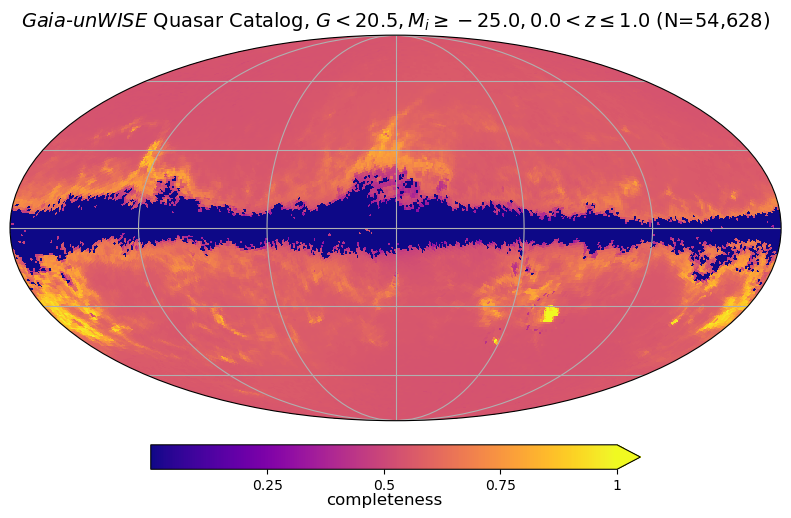

...

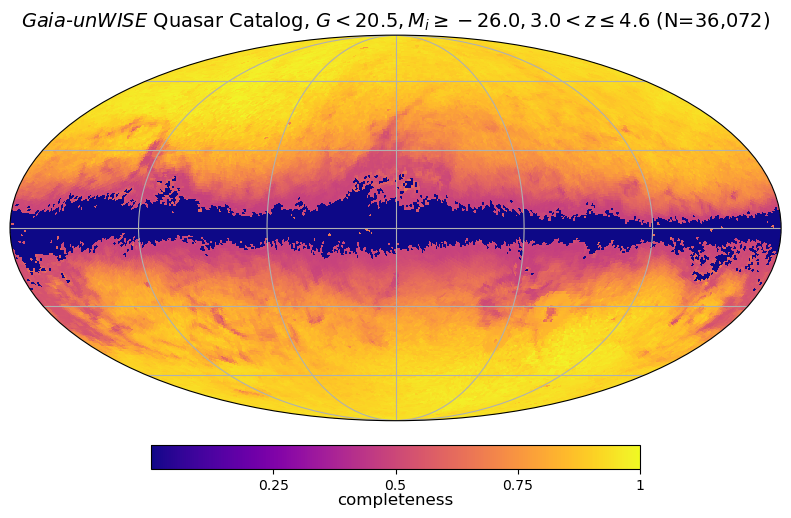

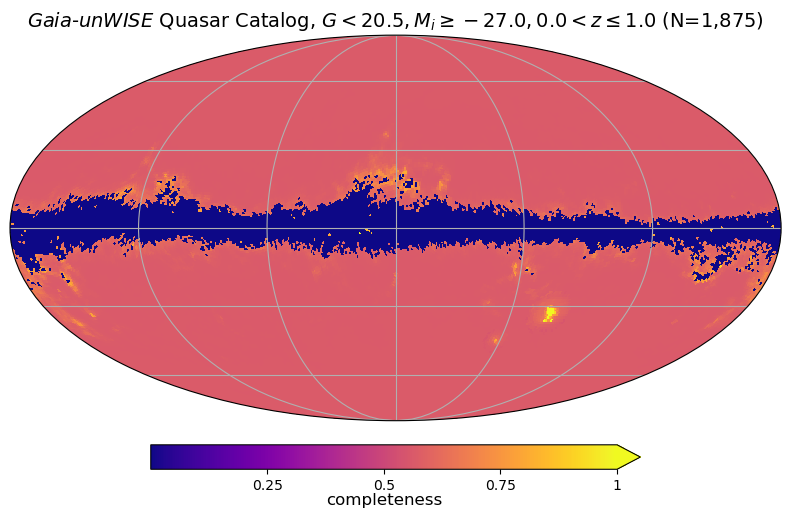

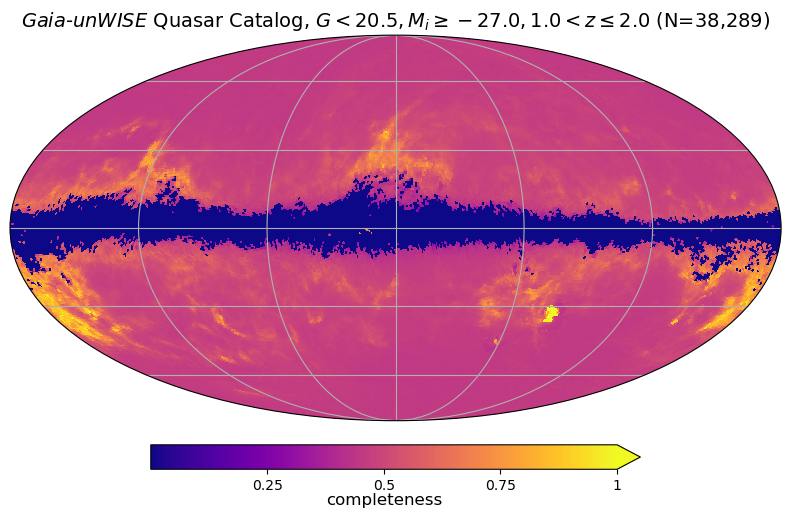

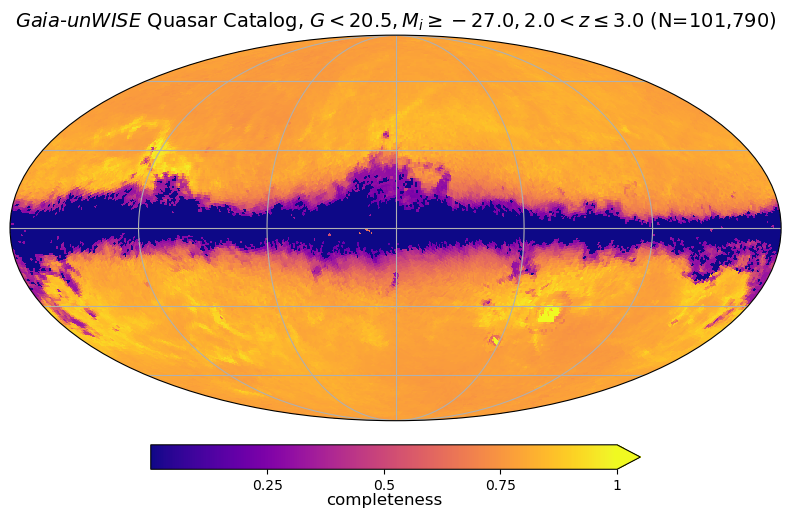

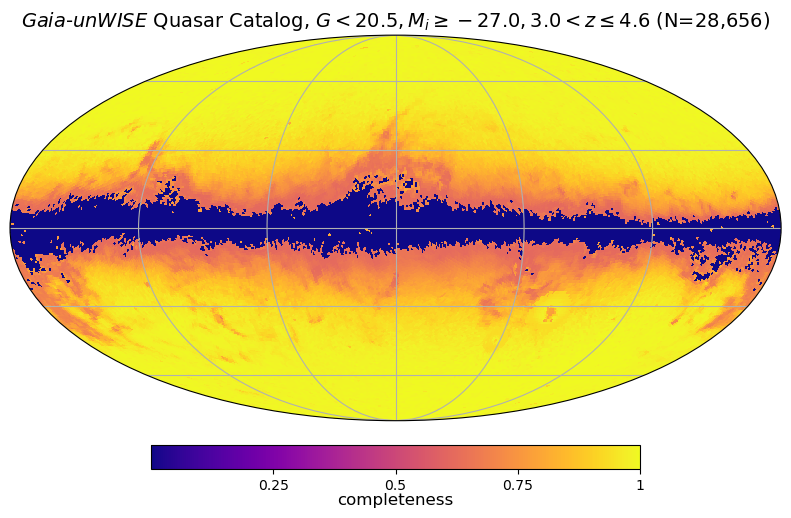

In [85]:
fac_rand = 25
fac_stdev = 0.15
for i in range(len(L_bins)):
            
    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0,_, _ = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                         bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                          method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                          mask_type = 'b', n_bins = [None, None])
        
        N_gcatlo_mask = len(tab_datahi_mask_zbin0)
        title_gcatlo = rf"{name_catalog}, $G<{G_hi}, M_i\geq{L_bins[i]}, {z_bins[j]:.1f}<z \leq{z_bins[j+1]:.1f}$ (N={N_gcatlo_mask:,})"
        projview(selfunc_hi_bin0, title=title_gcatlo,
                    unit=r"completeness", cmap=cmap_map, coord=['C','G'],
                    min=0, max = 1, 
                    graticule=True, cbar_ticks=[0.25, 0.5, 0.75, 1.0], graticule_labels=False) #True

In [51]:
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
b_wp_chi2 = {L: [] for L in L_bins}
a_zbin, b_wp_q = {L: [] for L in L_bins}, {L: [] for L in L_bins}
rpmask = {L: [] for L in L_bins}
H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc
    
for i in range(len(L_bins)):
            
    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, selfunc_hi_bin0, = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                         bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                          method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                          mask = mask*100, percentile = True, n_bins = [None, None])
    
        # quasar correlation function
        wp_zbin_i, rpavg_zbin_i = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, nthreads = nthreads, 
                                                                      rbins = rbins_chi2, nbins = nbins, pimax = pimax, Om0 = Planck18.Om0, h = Planck18.h)
        wp_chi2[L_bins[i]].append(wp_zbin_i)
        rpavg_chi2[L_bins[i]].append(rpavg_zbin_i)
    
        # scale factor
        a = a_median(tab_datahi_mask_zbin0)
        a_zbin[L_bins[i]].append(a)
    
        # matter correlation function   
        s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
        s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))
            
        xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a_median(tab_datahi_mask_zbin0))
        wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
        wp_matter_chi2[L_bins[i]].append(wp_matter_zbin_i)        
    
        # effective bias 
        b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)
        b_wp_chi2[L_bins[i]].append(b)
    
        # qso bias
        # b_wp_q[L_bins[i]].append(b_qso(wp_zbin_i, wp_matter_zbin_i, ccl.growth_rate(cosmo_planck18, a)))
        
        rpmask[L_bins[i]].append((np.array(rpavg_zbin_i) >= 30) & (np.array(rpavg_zbin_i) <= mask_max))

0.736999644779366
Pixels masked by MC but not already by selfunc: 1747
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.31              224111 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_5497/4113858660.py:35: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)


0.6993414145457213
Pixels masked by MC but not already by selfunc: 3641
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.28              464457 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_5497/4113858660.py:35: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)


0.6939067591495925
Pixels masked by MC but not already by selfunc: 3103
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.25              214485 vs 286508


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_5497/4113858660.py:35: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)


... (22 outputs left out)

0.7825058128181759
Pixels masked by MC but not already by selfunc: 1036
G20.5_zmin2.0zmax3.0_Lmax-27.0: 0.35              66760 vs 103123


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_5497/4113858660.py:35: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)


0.926017011721924
Pixels masked by MC but not already by selfunc: 278
G20.5_zmin3.0zmax4.6_Lmax-27.0: 0.26              21578 vs 28981


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_5497/4113858660.py:35: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)


In [67]:
cf_chi2, cf_matter_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}
yerr_cf_chi2, b_cf_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}
# b_cf_q_chi2 = {L: [] for L in L_bins}
a_zbin = {L: [] for L in L_bins}
H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc
    
for i in range(len(L_bins)):
            
    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, _, _ = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                         bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                          method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                          mask = mask*100, percentile = True, n_bins = [None, None])

        # quasar correlation function
        cf, qq, qr = quaia.xi_s(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, nthreads = nthreads, 
                   rbins = rbins_chi2, Om0 = Planck18.Om0, h = Planck18.h, error = True)
        cf_chi2[L_bins[i]].append(cf)
    
        # scale factor
        a = a_median(tab_datahi_mask_zbin0)
        a_zbin[L_bins[i]].append(a)
    
        # matter correlation function
        rbins_Mpc = (quaia.recenter(rbins_chi2)*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))
        cf_matter = ccl.correlations.correlation_3d(cosmo_planck18, r=rbins_Mpc, a=a)
        cf_matter_chi2[L_bins[i]].append(cf_matter)
    
        # effective bias 
        b = np.sqrt(cf/cf_matter)
        b_cf_chi2[L_bins[i]].append(b)
    
        # yerr
        yerr=(1+cf)/np.sqrt(qq)
        yerr[cf<0]=np.sqrt((1+b**2*cf_matter)/qr)[cf<0] #https://arxiv.org/abs/1603.04849
        yerr_cf_chi2[L_bins[i]].append(yerr)
    
        # qso bias
        # b_cf_q_chi2[L_bins[i]].append(b_qso(cf, cf_matter, ccl.growth_rate(cosmo_planck18, a)))

0.736999644779366
Pixels masked by MC but not already by selfunc: 1747
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.31              224111 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_5497/2632953064.py:31: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(cf/cf_matter)


0.6993414145457213
Pixels masked by MC but not already by selfunc: 3641
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.28              464457 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_5497/2632953064.py:31: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(cf/cf_matter)


0.6939067591495925
Pixels masked by MC but not already by selfunc: 3103
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.25              214485 vs 286508


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_5497/2632953064.py:31: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(cf/cf_matter)


... (22 outputs left out)

0.7825058128181759
Pixels masked by MC but not already by selfunc: 1036
G20.5_zmin2.0zmax3.0_Lmax-27.0: 0.35              66760 vs 103123


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_5497/2632953064.py:31: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(cf/cf_matter)


0.926017011721924
Pixels masked by MC but not already by selfunc: 278
G20.5_zmin3.0zmax4.6_Lmax-27.0: 0.26              21578 vs 28981


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_5497/2632953064.py:31: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(cf/cf_matter)


# Plot clustering on linear scale

In [41]:
cmap_rocket = sns.color_palette("flare_r", n_colors = len(L_bins))
cmap_rocket

[(0.47936222, 0.18006056, 0.43733022),
 (0.66635279, 0.22717328, 0.43008427),
 (0.83765537, 0.30784814, 0.3723105),
 (0.90732341, 0.4939774, 0.38990532)]

<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_5497/1839688357.py:19: SyntaxWarning: invalid escape sequence '\l'
  ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, #capsize = 2.5,
/tmp/ipykernel_5497/1839688357.py:27: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[j]))


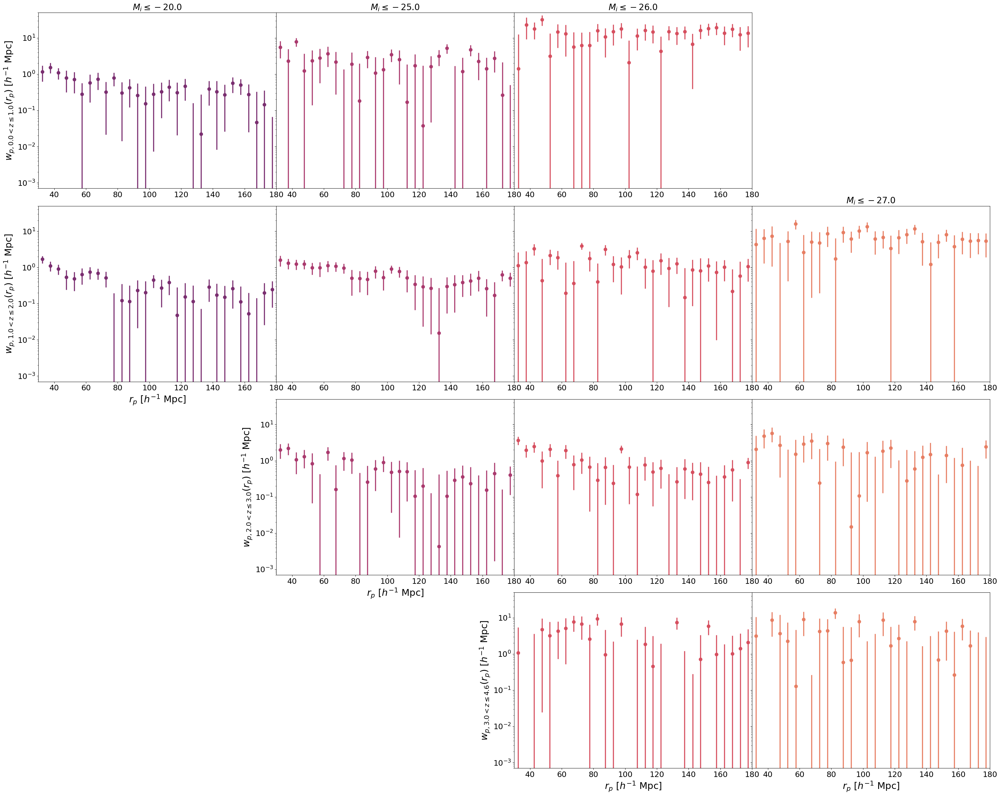

In [63]:
# plot!
r = quaia.recenter(rbins_chi2) #_chi2)
ylim = 7e-4, 5e1 #4e2

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
mask = 0.5
for i in range(len(z_array)):
    
    for j in range(len(L_bins)):
    
        if (((j<3) and (N_q[L_bins[j]][i]>N_q[L_bins[j+1]][i])) or (j==3)) and (np.round(N_q[L_bins[j]][i]/1000)>1):

            ax1 = fig.add_subplot(gs[i*4+j])

            wp_zbin_i = np.load('../results/wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_bins[j], cosmo, mask))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_bins[j], cosmo, mask))
            sigma = np.sqrt(np.diag(np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_bins[j], N, cosmo, mask))))
            ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, #capsize = 2.5,
                     linewidth = 2.5, yerr = sigma, linestyle = 'None', color = cmap_rocket[j]) # color = cmap_blue[::-1][j]
            # ax1.errorbar(rpavg_chi2[L_bins[j]][i], wp_chi2[L_bins[j]][i], marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, #capsize = 2.5,
            #          linewidth = 2.5, yerr = sigma, linestyle = 'None', color = cmap_rocket[j]) # color = cmap_blue[::-1][j]
            # ax1.errorbar(r, cf_chi2[L_bins[j]][i], marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, capsize = 2.5,
            #          linewidth = 2.5, yerr = sigma, linestyle = 'None', color = cmap_rocket[j]) # color = cmap_blue[::-1][j]

            if (i ==0) or ((j == 3) and (i == 1)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[j]))
            if scale == 'log':
                ax1.set_xscale('log')
            ax1.set_yscale('log')
            ax1.set_xlim(r[0]-2.5, r[-1]+2.5)
            ax1.set_ylim(ylim)
            if i > 2 or ((i>0) and (j <2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
            if j==0 or ((i>1) and (j <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[i], z_bins[i+1]))
            else:
                ax1.set_yticklabels([])

# plt.savefig('../figures/threshold_wp.pdf', bbox_inches = 'tight')
plt.show()

<>:20: SyntaxWarning: invalid escape sequence '\l'
<>:23: SyntaxWarning: invalid escape sequence '\l'
<>:20: SyntaxWarning: invalid escape sequence '\l'
<>:23: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15470/156006337.py:20: SyntaxWarning: invalid escape sequence '\l'
  ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, #capsize = 2.5,
/tmp/ipykernel_15470/156006337.py:23: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[j]))


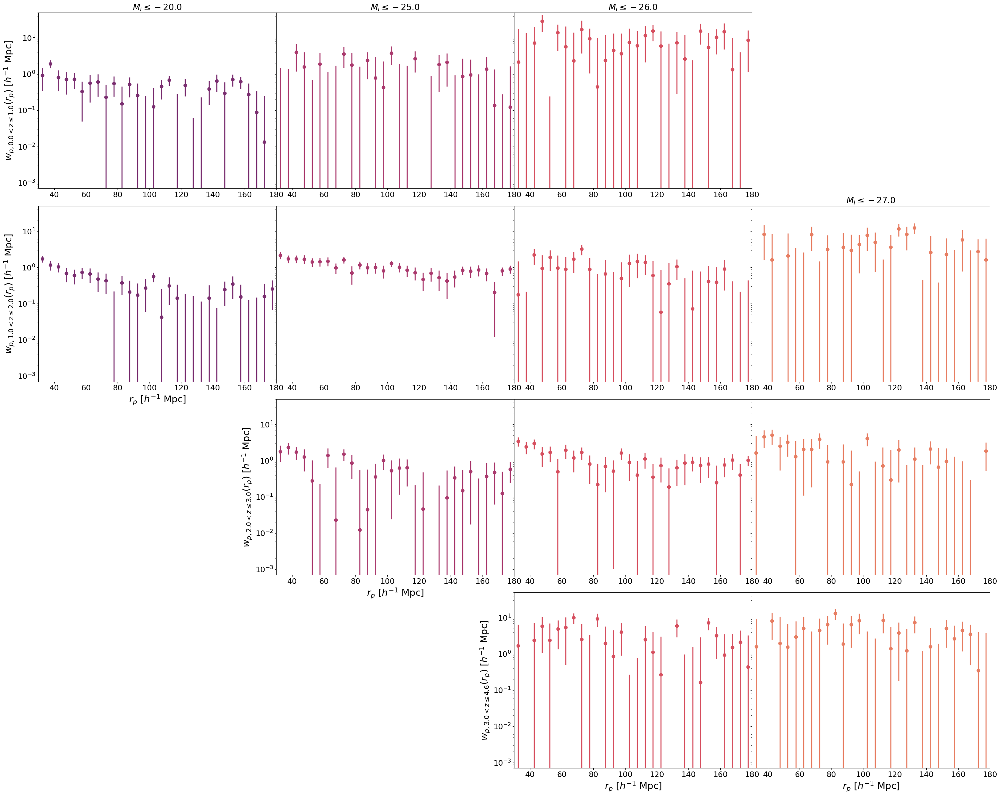

In [36]:
# plot!
r = quaia.recenter(rbins_chi2) #_chi2)
ylim = 7e-4, 5e1 #4e2

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
b = 30
for i in range(len(z_array)):
    
    for j in range(len(L_bins)):
    
        if (((j<3) and (N_q_b[L_bins[j]][i]>N_q_b[L_bins[j+1]][i])) or (j==3)) and (np.round(N_q_b[L_bins[j]][i]/1000)>1):

            ax1 = fig.add_subplot(gs[i*4+j])

            wp_zbin_i = np.load('../results/wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_bins[j], cosmo, b))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_bins[j], cosmo, b))

            sigma = np.sqrt(np.diag(np.load('../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_bins[j], N, cosmo, b))))
            ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, #capsize = 2.5,
                     linewidth = 2.5, yerr = sigma, linestyle = 'None', color = cmap_rocket[j]) # color = cmap_blue[::-1][j]
            if (i ==0) or ((j == 3) and (i == 1)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[j]))
            if scale == 'log':
                ax1.set_xscale('log')
            ax1.set_yscale('log')
            ax1.set_xlim(r[0]-2.5, r[-1]+2.5)
            ax1.set_ylim(ylim)
            if i > 2 or ((i>0) and (j <2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
            if j==0 or ((i>1) and (j <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[i], z_bins[i+1]))
            else:
                ax1.set_yticklabels([])

# plt.savefig('../figures/threshold_wp.pdf', bbox_inches = 'tight')
plt.show()

In [71]:
# cmap_wp = sns.color_palette("rocket", n_colors = len(L_bins))
cmap_xi = sns.color_palette("crest_r", n_colors = len(L_bins))

<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:23: SyntaxWarning: invalid escape sequence '\l'
<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:23: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15299/1365353386.py:19: SyntaxWarning: invalid escape sequence '\l'
  ax1.errorbar(r, cf_chi2[L_bins[j]][i], marker = '^', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, #capsize = 2.5,
/tmp/ipykernel_15299/1365353386.py:23: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[j]))


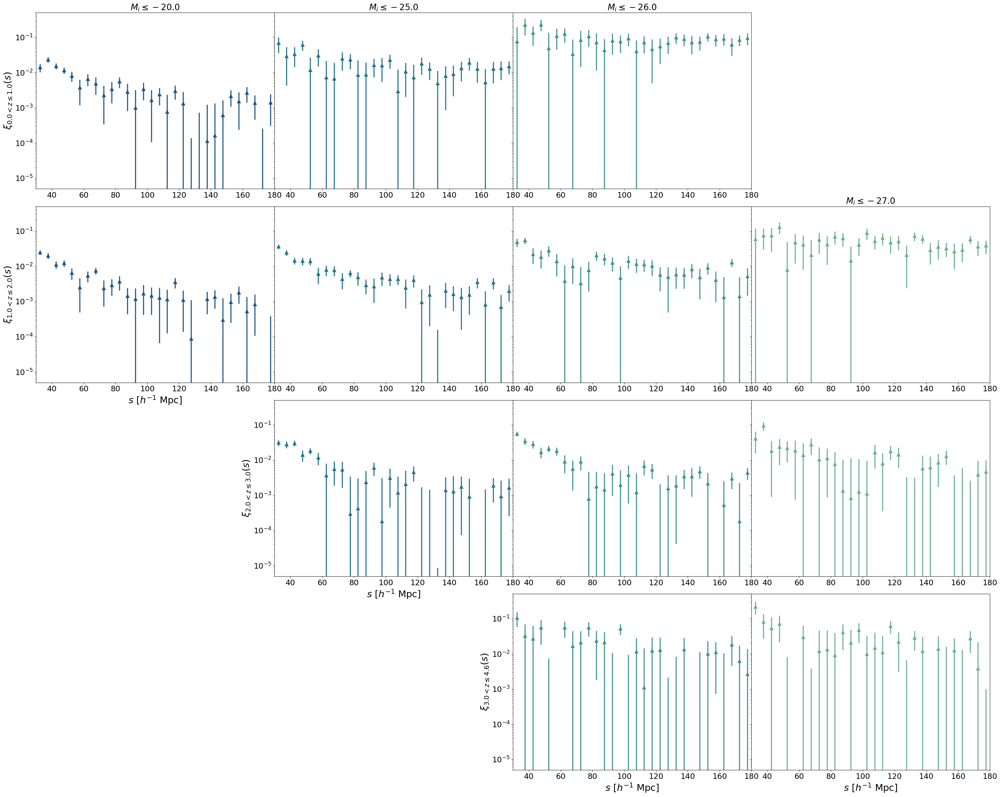

In [38]:
# plot!
r = quaia.recenter(rbins_chi2) #_chi2)
# ylim = 7e-4, 5e1 #4e2

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

for i in range(len(z_array)):
    
    for j in range(len(L_bins)):
    
        if (((j<3) and (N_q[L_bins[j]][i]>N_q[L_bins[j+1]][i])) or (j==3)) and (np.round(N_q[L_bins[j]][i]/1000)>1):

            ax1 = fig.add_subplot(gs[i*4+j])

            sigma = np.sqrt(np.diag(np.load('../results/cov_xi_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask.npy'.format(G_hi, rmin, rmax, nbins, z_bins[i], z_bins[i+1], L_bins[j], N, cosmo))))
            # ax1.errorbar(rpavg_chi2[L_bins[j]][i], wp_chi2[L_bins[j]][i], marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, capsize = 2.5,
            #          linewidth = 2.5, yerr = sigma, linestyle = 'None', color = cmap_rocket[j]) # color = cmap_blue[::-1][j]
            ax1.errorbar(r, cf_chi2[L_bins[j]][i], marker = '^', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, #capsize = 2.5,
                     linewidth = 2.5, yerr = sigma, linestyle = 'None', color = cmap_xi[j]) # color = cmap_blue[::-1][j]

            if (i ==0) or ((j == 3) and (i == 1)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[j]))
            if scale == 'log':
                ax1.set_xscale('log')
            ax1.set_yscale('log')
            ax1.set_xlim(r[0]-2.5, r[-1]+2.5)
            ax1.set_ylim(5e-6,5e-1)
            if i > 2 or ((i>0) and (j <2) and (i!=j)):
                ax1.set_xlabel(r'$s$ $[h^{-1}$ Mpc]') # projected
            if j==0 or ((i>1) and (j <3) and (i!=j)):
                ax1.set_ylabel(r"$\xi_{{{:.1f}<z \leq{:.1f}}}(s)$".format(z_bins[i], z_bins[i+1]))
            else:
                ax1.set_yticklabels([])

plt.savefig('../figures/threshold_xi.pdf', bbox_inches = 'tight')
plt.show()

In [39]:
offset = 1.25

<>:26: SyntaxWarning: invalid escape sequence '\l'
<>:26: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_5497/1208882404.py:26: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[j]))


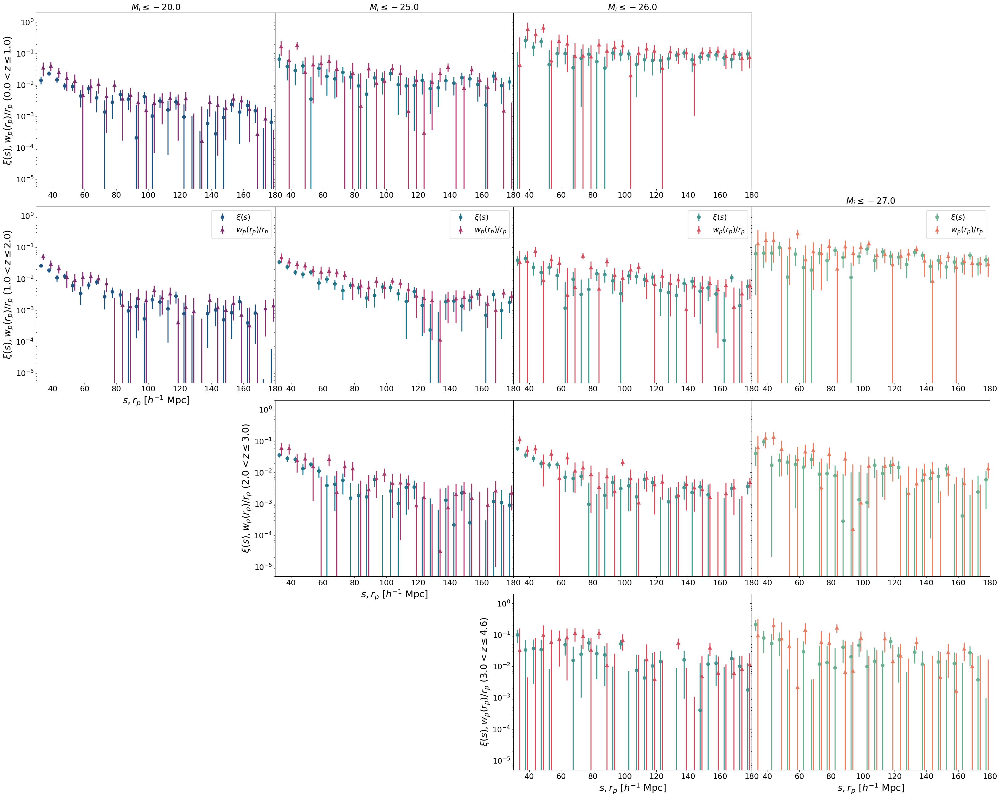

In [74]:
# plot!
r = quaia.recenter(rbins_chi2) #_chi2)
# ylim = 7e-4, 5e1 #4e2

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

for i in range(len(z_array)):
    
    for j in range(len(L_bins)):
    
        if (((j<3) and (N_q[L_bins[j]][i]>N_q[L_bins[j+1]][i])) or (j==3)) and (np.round(N_q[L_bins[j]][i]/1000)>1):

            ax1 = fig.add_subplot(gs[i*4+j])

            sigma = np.sqrt(np.diag(np.load('../results/cov_xi_G{}_rmin{:.0f}_rmax{:.0f}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask.npy'.format(G_hi, rmin, rmax, nbins, z_bins[i], z_bins[i+1], L_bins[j], N, cosmo))))
            ax1.errorbar(r, cf_chi2[L_bins[j]][i], marker = 'o', label = r'$\xi(s)$', markeredgewidth = 2.5, #capsize = 2.5,
                     linewidth = 2.5, yerr = sigma, linestyle = 'None', color = cmap_xi[j]) # color = cmap_blue[::-1][j]
            
            sigma = np.sqrt(np.diag(np.load('../results/cov_wp_G{}_rmin{:.0f}_rmax{:.0f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_bins[j], N, cosmo))))
            ax1.errorbar(np.array(rpavg_chi2[L_bins[j]][i])+offset, wp_chi2[L_bins[j]][i]/rpavg_chi2[L_bins[j]][i], marker = '^', label = '$w_p(r_p)/r_p$', markeredgewidth = 2.5, #capsize = 2.5,
                     linewidth = 2.5, yerr = sigma/rpavg_chi2[L_bins[j]][i], linestyle = 'None', color = cmap_rocket[j])#wp[0]) # color = cmap_blue[::-1][j]
        

            if (i ==0) or ((j == 3) and (i == 1)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[j]))
            if scale == 'log':
                ax1.set_xscale('log')
            ax1.set_yscale('log')
            ax1.set_xlim(r[0]-2.5, r[-1]+2.5)
            ax1.set_ylim(5e-6, 2)
            if i > 2 or ((i>0) and (j <2) and (i!=j)):
                ax1.set_xlabel(r'$s,r_p$ $[h^{-1}$ Mpc]') # projected
            if j==0 or ((i>1) and (j <3) and (i!=j)):
                ax1.set_ylabel(r"$\xi(s),w_p(r_p)/r_p$ $({:.1f}<z \leq{:.1f})$".format(z_bins[i], z_bins[i+1]))
            else:
                ax1.set_yticklabels([])
            if i == 1:
                ax1.legend()#title = r"${:.1f}<z \leq{:.1f}$".format(z_bins[i], z_bins[i+1]), title_fontsize = 18)
            # ax1.set_xscale('log')

# ax1.legend()#title = r"${:.1f}<z \leq{:.1f}$".format(z_bins[i], z_bins[i+1]), title_fontsize = 18)

# plt.savefig('../figures/threshold_clustering.pdf', bbox_inches = 'tight')
plt.show()

In [56]:
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_array[::-1][:-1]}, {L: [] for L in L_array[::-1][:-1]}, {L: [] for L in L_array[::-1][:-1]}
b_wp_chi2 = {L: [] for L in L_array[::-1][:-1]}
a_zbin, b_wp_q = {L: [] for L in L_array[::-1][:-1]}, {L: [] for L in L_array[::-1][:-1]}
rpmask = {L: [] for L in L_array[::-1][:-1]}
H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc
    
for i in range(len(L_array[::-1][:-1])):
            
    for j in z_array:

        try:
            
            tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _ = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                                 bins = [z_bins, L_array[::-1]], tab_gcat_type = 'data', 
                                                                                                  method = ['minmax', 'minmax'], fac_rand = fac_rand, 
                                                                                                  mask = mask*100, percentile = True, n_bins = [None, None])
        
            # quasar correlation function
            wp_zbin_i, rpavg_zbin_i = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, nthreads = nthreads, 
                                                                          rbins = rbins_chi2, nbins = nbins, pimax = pimax, Om0 = Planck18.Om0, h = Planck18.h)
            wp_chi2[L_array[::-1][i]].append(wp_zbin_i)
            rpavg_chi2[L_array[::-1][i]].append(rpavg_zbin_i)
        
            # scale factor
            a = a_median(tab_datahi_mask_zbin0)
            a_zbin[L_array[::-1][i]].append(a)
        
            # matter correlation function   
            s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
            s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))
                
            xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
            wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
            wp_matter_chi2[L_array[::-1][i]].append(wp_matter_zbin_i)        
        
            # effective bias 
            b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)
            b_wp_chi2[L_array[::-1][i]].append(b)
        
            # # qso bias
            # b_wp_q[L_bins[i]].append(b_qso(wp_zbin_i, wp_matter_zbin_i, ccl.growth_rate(cosmo_planck18, a)))
            
            rpmask[L_array[::-1][i]].append((np.array(rpavg_zbin_i) >= 30) & (np.array(rpavg_zbin_i) <= mask_max))

        except:

            print('G{}_zmin{}zmax{}_Lmin{}Lmax{}:                   no selection function'.format(G_hi, z_bins[j], z_bins[j+1], L_array[::-1][i], 
                                                                                                      L_array[::-1][i+1]))

0.6709454064119132
Pixels masked by MC but not already by selfunc: 40
G20.5_zmin0.0zmax1.0_Lmin-32.0Lmax-27.0: 0.34              1226 vs 1860


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_15299/4052433454.py:37: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)


0.4024413828706144
Pixels masked by MC but not already by selfunc: 353
G20.5_zmin1.0zmax2.0_Lmin-32.0Lmax-27.0: 0.36              24196 vs 38015


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_15299/4052433454.py:37: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)


0.7780317247297315
Pixels masked by MC but not already by selfunc: 994
G20.5_zmin2.0zmax3.0_Lmin-32.0Lmax-27.0: 0.35              66160 vs 102196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_15299/4052433454.py:37: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)


... (18 outputs left out)

0.5015072332698005
Pixels masked by MC but not already by selfunc: 879
G20.5_zmin1.0zmax2.0_Lmin-25.0Lmax-20.0: 0.14              127856 vs 149321


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin2.0zmax3.0_Lmin-25.0Lmax-20.0:                   no selection function
G20.5_zmin3.0zmax4.6_Lmin-25.0Lmax-20.0:                   no selection function


/tmp/ipykernel_15299/4052433454.py:37: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)


<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:44: SyntaxWarning: invalid escape sequence '\g'
<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:44: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_31565/2968779727.py:35: SyntaxWarning: invalid escape sequence '\l'
  ax1.errorbar(rpavg_chi2, wp_chi2, marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5,# capsize = 2.5,
/tmp/ipykernel_31565/2968779727.py:44: SyntaxWarning: invalid escape sequence '\g'
  ax1.set_title('${}\geq M_i>{}$'.format(L_array[j], L_array[j+1]))


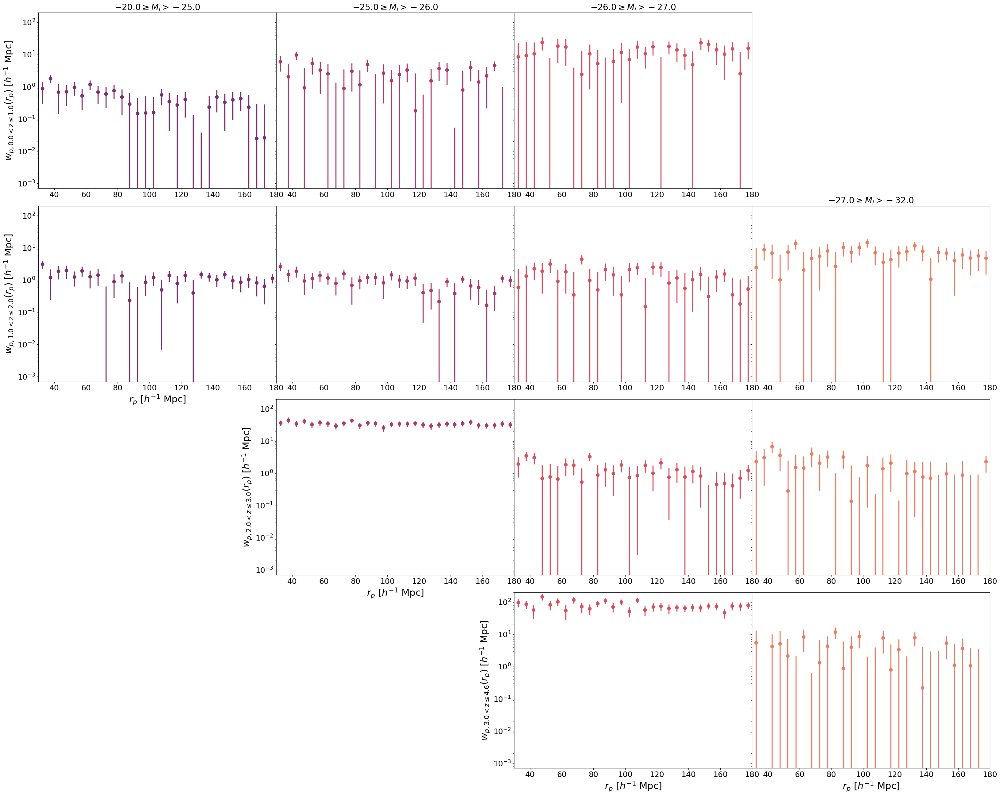

In [40]:
# plot!
r = quaia.recenter(rbins_chi2) #_chi2)
ylim = 7e-4, 2e2 #4e2

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

for i in range(len(z_array)):
    
    for j in range(len(L_array[::-1])-1):
    
        # if (((j<3) and (N_cut[j][i]>N_cut[j][i])) or (j==3)) and (np.round(N_cut[j][i]/1000)>1):
        try: 
            
            if np.round(N_cut_b[::-1][j][i]/1000)>1:
    
                ax1 = fig.add_subplot(gs[i*4+j])
    
                wp_chi2 = np.load('../results/wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmin{}Lmax{}_{}_MC_mask{}.npy'.format(
                    G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_array[j+1], L_array[j], cosmo, mask))
                rpavg_chi2 = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmin{}Lmax{}_{}_MC_mask{}.npy'.format(
                    G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_array[j+1], L_array[j], cosmo, mask))
                try:
                    sigma = np.sqrt(np.diag(np.load(
                        '../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmin{}Lmax{}_N{}_{}_MC_mask{}.npy'.format(
                            G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_array[j+1], L_array[j], N, cosmo, mask))))
                    # print('../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_zmin{}zmax{}_Lmin{}Lmax{}_N{}_{}_MC_mask{}.npy'.format(
                    #         G_hi, rmin, rmax, nbins, z_bins[i], z_bins[i+1], L_array[j+1], L_array[j], N, cosmo, mask))
                    # print(sigma)
                except Exception as e:

                    print(e)
                    sigma = 0
                    print(sigma)
                ax1.errorbar(rpavg_chi2, wp_chi2, marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5,# capsize = 2.5,
                         linewidth = 2.5, yerr = sigma, linestyle = 'None', color = cmap_rocket[j]) # color = cmap_blue[::-1][j]
                # ax1.errorbar(rpavg_chi2[L_array[::-1][j]][i], wp_chi2[L_array[::-1][j]][i], marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, capsize = 2.5,
                #          linewidth = 2.5, yerr = sigma, linestyle = 'None', color = cmap_rocket[j]) # color = cmap_blue[::-1][j]
                # ax1.errorbar(r, cf_chi2[L_bins[j]][i], marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, capsize = 2.5,
                #          linewidth = 2.5, yerr = sigma, linestyle = 'None', color = cmap_rocket[j]) # color = cmap_blue[::-1][j]
    
                if (i ==0) or ((j == 3) and (i == 1)):
                    # ax1.set_title('${}<M_i\leq{}$'.format(L_array[::-1][j], L_array[::-1][j+1]))
                    ax1.set_title('${}\geq M_i>{}$'.format(L_array[j], L_array[j+1]))
                if scale == 'log':
                    ax1.set_xscale('log')
                ax1.set_yscale('log')
                ax1.set_xlim(r[0]-2.5, r[-1]+2.5)
                ax1.set_ylim(ylim)
                if i > 2 or ((i==1) and (j == 0)) or ((i==2) and (j==1)):
                    ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
                if j==0 or ((i==2) and (j == 1)) or ((i==3) and (j == 2)):
                    ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[i], z_bins[i+1]))
                else:
                    ax1.set_yticklabels([])
                    
        except Exception as e:

            # print('G{}_zmin{}zmax{}_Lmin{}Lmax{}:                   no selection function'.format(G_hi, z_bins[i], z_bins[i+1], L_array[j+1], 
            #                                                                                           L_array[j]))

            # print(e)
            pass

# plt.savefig('../figures/threshold_clustering.pdf', bbox_inches = 'tight')
plt.show()

<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:38: SyntaxWarning: invalid escape sequence '\g'
<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:38: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_31565/1840303481.py:35: SyntaxWarning: invalid escape sequence '\l'
  ax1.errorbar(rpavg_chi2, wp_chi2, marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, #capsize = 2.5,
/tmp/ipykernel_31565/1840303481.py:38: SyntaxWarning: invalid escape sequence '\g'
  ax1.set_title('${}\geq M_i>{}$'.format(L_array[j], L_array[j+1]))


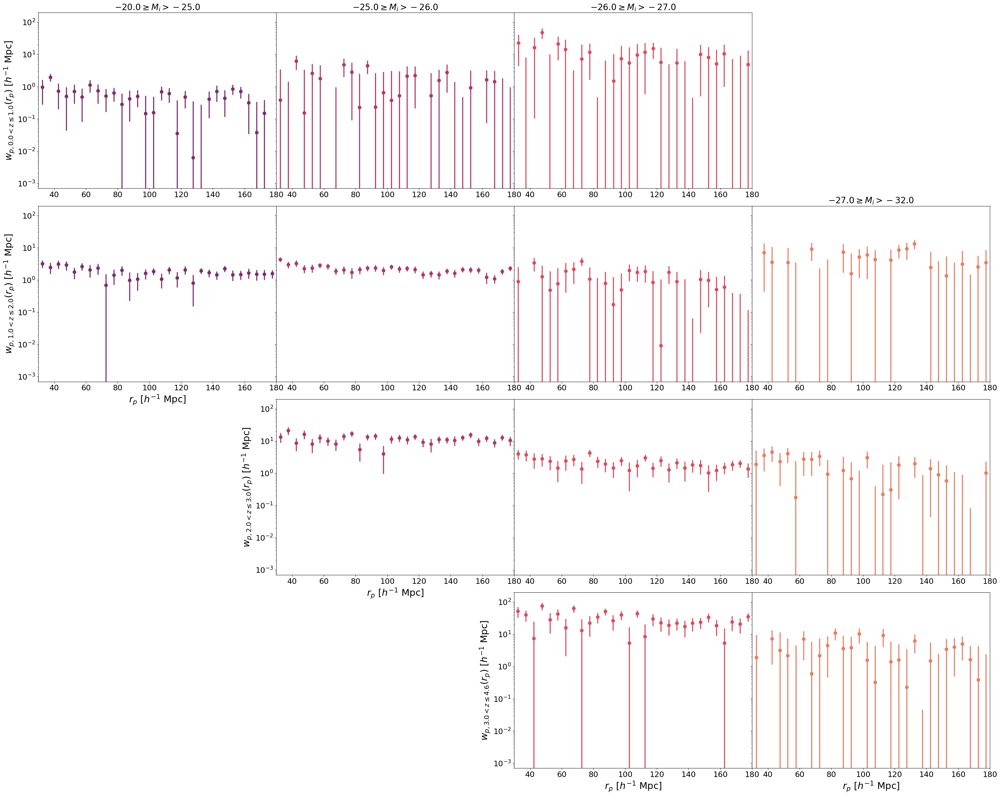

In [41]:
# plot!
r = quaia.recenter(rbins_chi2) #_chi2)
ylim = 7e-4, 2e2 #4e2

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

for i in range(len(z_array)):
    
    for j in range(len(L_array[::-1])-1):
    
        # if (((j<3) and (N_cut[j][i]>N_cut[j][i])) or (j==3)) and (np.round(N_cut[j][i]/1000)>1):
        try: 
            
            if np.round(N_cut_b[::-1][j][i]/1000)>1:
    
                ax1 = fig.add_subplot(gs[i*4+j])
    
                wp_chi2 = np.load('../results/wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmin{}Lmax{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_array[j+1], L_array[j], cosmo, b))
                rpavg_chi2 = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmin{}Lmax{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_array[j+1], L_array[j], cosmo, b))
                try:
                    sigma = np.sqrt(np.diag(np.load(
                        '../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmin{}Lmax{}_N{}_{}_MC_b{}.npy'.format(
                            G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_array[j+1], L_array[j], N, cosmo, b))))
                    # print('../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmin{}Lmax{}_N{}_{}_MC_b{}.npy'.format(
                    #         G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_array[j+1], L_array[j], N, cosmo, b))
                    # print(sigma)
                except Exception as e:

                    print(e)
                    sigma = 0
                # print(sigma)
                ax1.errorbar(rpavg_chi2, wp_chi2, marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, #capsize = 2.5,
                         linewidth = 2.5, yerr = sigma, linestyle = 'None', color = cmap_rocket[j]) # color = cmap_blue[::-1][j]
                if (i ==0) or ((j == 3) and (i == 1)):
                    ax1.set_title('${}\geq M_i>{}$'.format(L_array[j], L_array[j+1]))
                if scale == 'log':
                    ax1.set_xscale('log')
                ax1.set_yscale('log')
                ax1.set_xlim(r[0]-2.5, r[-1]+2.5)
                ax1.set_ylim(ylim)
                if i > 2 or ((i==1) and (j == 0)) or ((i==2) and (j==1)):
                    ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
                if j==0 or ((i==2) and (j == 1)) or ((i==3) and (j == 2)):
                    ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[i], z_bins[i+1]))
                else:
                    ax1.set_yticklabels([])
                    
        except Exception as e:                                                                       

            print(e)

plt.savefig('../figures/bins_wp_b.pdf', bbox_inches = 'tight')

plt.show()

## Plot correlation matrix

<>:23: SyntaxWarning: invalid escape sequence '\l'
<>:26: SyntaxWarning: invalid escape sequence '\l'
<>:23: SyntaxWarning: invalid escape sequence '\l'
<>:26: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_5497/710210031.py:23: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$r_{{p,{:.1f}<z \leq{:.1f}}} (h^{{-1}}$ Mpc)'.format(z_bins[i], z_bins[i+1]))
/tmp/ipykernel_5497/710210031.py:26: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[j]))


(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)


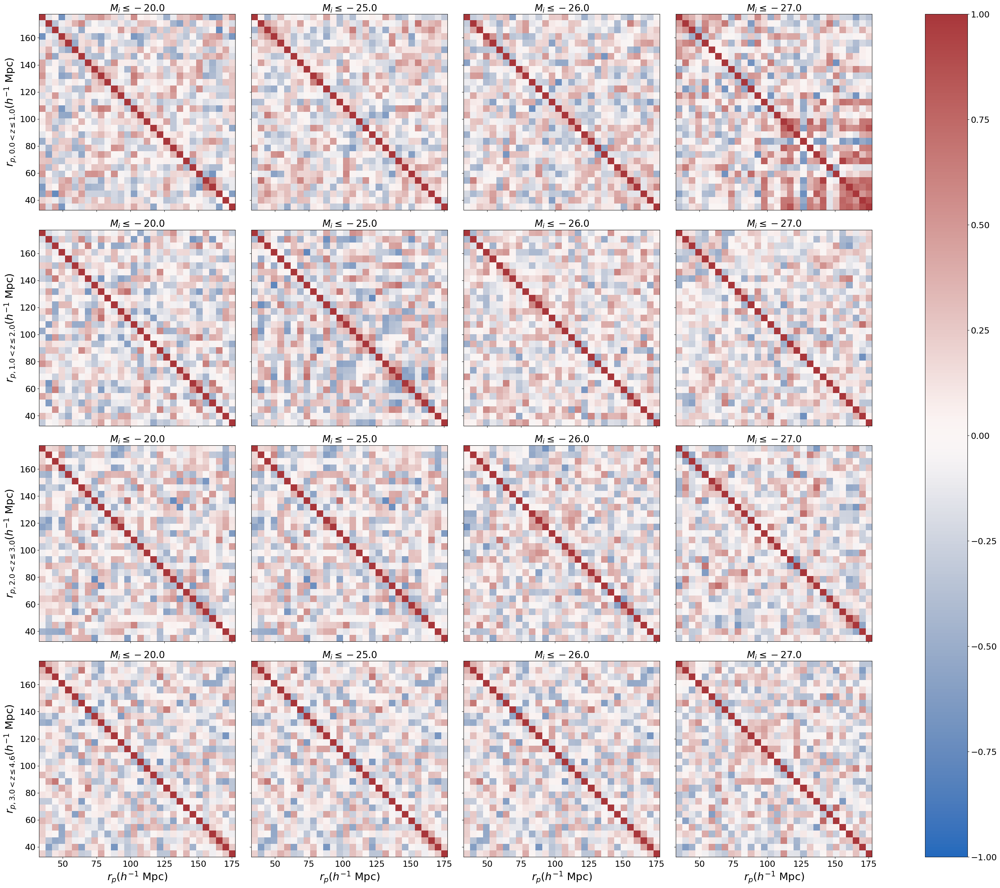

In [75]:
cmap = sns.color_palette("vlag", as_cmap=True)
r = quaia.recenter(rbins_chi2) #_chi2)

# plot!
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
axes = []
for i in range(len(z_bins)-1):
    
    for j in range(len(L_bins)):
    
        ax1 = fig.add_subplot(gs[i*4+j])

        C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_bins[j], N, cosmo, mask))
        matrix = np.corrcoef(C)
        image = ax1.imshow(matrix, cmap = cmap, extent = [r[0], r[-1], r[0], r[-1]], vmin = -1, vmax = 1)
        print(image.get_clim())
        if i > 2:
            ax1.set_xlabel('$r_p (h^{-1}$ Mpc)')
        else:
            ax1.set_xticklabels([])
        if j == 0:
            ax1.set_ylabel('$r_{{p,{:.1f}<z \leq{:.1f}}} (h^{{-1}}$ Mpc)'.format(z_bins[i], z_bins[i+1]))
        else:
            ax1.set_yticklabels([])
        ax1.set_title('$M_i\leq{}$'.format(L_bins[j]))
        axes.append(ax1)
    
fig.colorbar(image, ax = axes)
plt.show()

<>:23: SyntaxWarning: invalid escape sequence '\l'
<>:26: SyntaxWarning: invalid escape sequence '\l'
<>:23: SyntaxWarning: invalid escape sequence '\l'
<>:26: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15470/1752901502.py:23: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$r_{{p,{:.1f}<z \leq{:.1f}}} (h^{{-1}}$ Mpc)'.format(z_bins[i], z_bins[i+1]))
/tmp/ipykernel_15470/1752901502.py:26: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[j]))


(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)


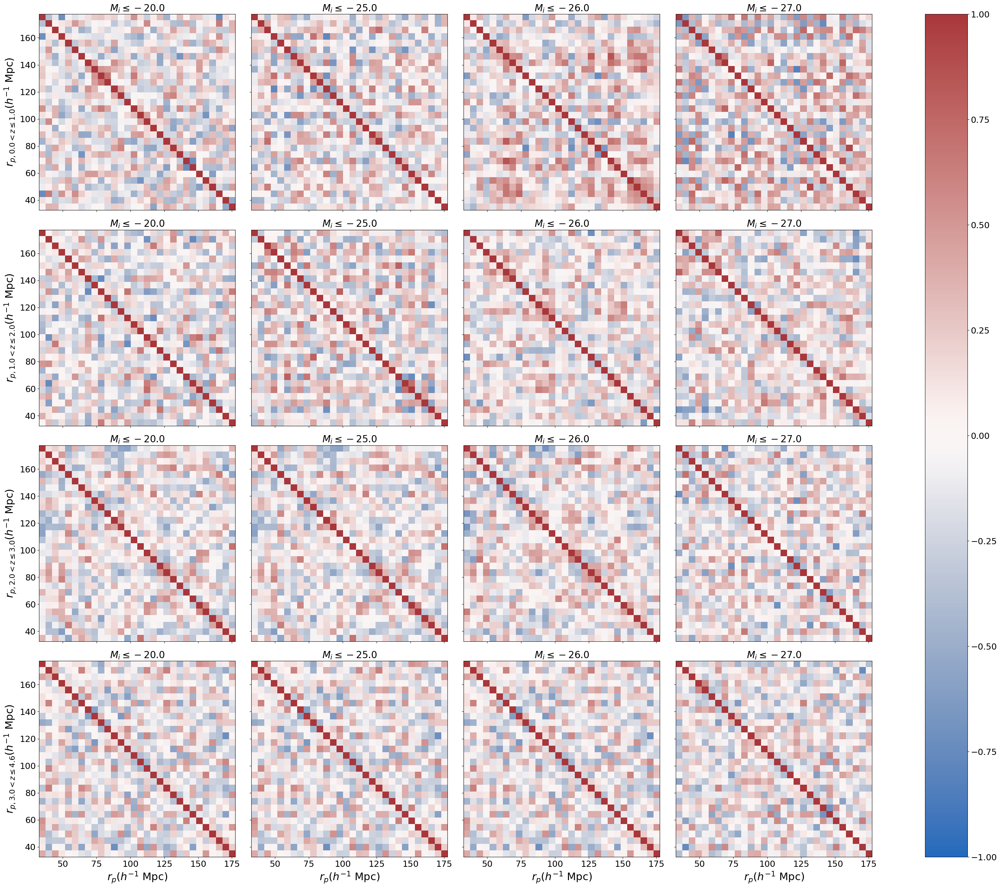

In [37]:
cmap = sns.color_palette("vlag", as_cmap=True)
r = quaia.recenter(rbins_chi2) #_chi2)

# plot!
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
axes = []
for i in range(len(z_bins)-1):
    
    for j in range(len(L_bins)):
    
        ax1 = fig.add_subplot(gs[i*4+j])

        C = np.load('../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_bins[j], N, cosmo, b))
        matrix = np.corrcoef(C)
        image = ax1.imshow(matrix, cmap = cmap, extent = [r[0], r[-1], r[0], r[-1]], vmin = -1, vmax = 1)
        print(image.get_clim())
        if i > 2:
            ax1.set_xlabel('$r_p (h^{-1}$ Mpc)')
        else:
            ax1.set_xticklabels([])
        if j == 0:
            ax1.set_ylabel('$r_{{p,{:.1f}<z \leq{:.1f}}} (h^{{-1}}$ Mpc)'.format(z_bins[i], z_bins[i+1]))
        else:
            ax1.set_yticklabels([])
        ax1.set_title('$M_i\leq{}$'.format(L_bins[j]))
        axes.append(ax1)
    
fig.colorbar(image, ax = axes)
plt.show()

### Test the mask

In [81]:
masks = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
cmap_masks = sns.color_palette("coolwarm", n_colors = len(masks))
cmap_masks

[(0.383662065772549, 0.5101834172862746, 0.9178306732313726),
 (0.5543118699137254, 0.6900970112156862, 0.9955155482352941),
 (0.724041371882353, 0.8149103926470588, 0.9756509706470589),
 (0.8674276350862745, 0.864376599772549, 0.8626024620196079),
 (0.9595176584705882, 0.7669728545098039, 0.6741447150392157),
 (0.9566532109764706, 0.598033822717647, 0.4773022923529412),
 (0.8653913329372549, 0.3711276720470588, 0.2957689564156863)]

<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:85: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:85: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_15470/111611037.py:21: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_15470/111611037.py:85: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5, capsize = 2.5,


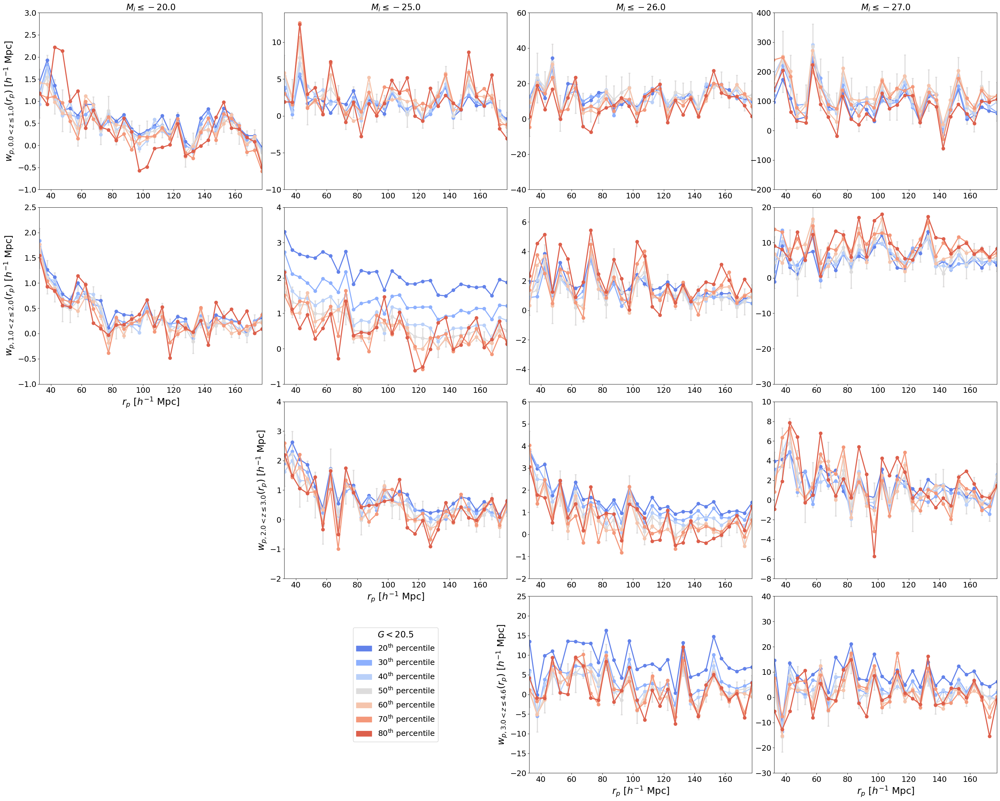

In [43]:
r = quaia.recenter(rbins_chi2) #_chi2)
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
a_zbin = {L: [] for L in L_bins}
ylims = [[[-1, 3], [-10, 14], [-40, 60], [-200, 400]], [[-1, 2.5], [-1, 4], [-5, 7], [-30, 20]], [[np.nan, np.nan], [-2, 4], [-2, 6], [-8, 10]], 
         [[np.nan, np.nan], [np.nan, np.nan], [-20, 25], [-30, 40]]]

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.1, hspace = 0.1)

H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc

for j in z_array:
    
    for i in range(len(L_bins)):

        if ((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            if j ==0:
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if scale == 'log':
                ax1.set_xscale('log')
            ax1.set_xlim(r[0], r[-1])
            ax1.set_ylim(ylims[j][i])
            
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
        else:

            ax2 = fig.add_subplot(gs[j*4+i])
            ax2.set_axis_off()
                
        for k in range(len(masks)):
                    
            # try:
                
            wp_zbin_i = np.load('../results/wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k]))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k]))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k])))

            # except:

            #     tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, selfunc_hi_bin0, = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
            #                                                                                  bins = [z_bins, L_bins], tab_gcat_type = 'data', 
            #                                                                                   method = ['minmax', 'max'], fac_rand = fac_rand, 
            #                                                                                   mask = masks[k]*100, percentile = True, n_bins = [None, None])
                
            #     # quasar correlation function
            #     wp_zbin_i, rpavg_zbin_i = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, nthreads = nthreads, 
            #                                                                   rbins = rbins_chi2, nbins = nbins, pimax = pimax, Om0 = Planck18.Om0, h = Planck18.h)

            #     # scale factor
            #     a = a_median(tab_datahi_mask_zbin0)
                
            #     np.save('../results/wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k]), wp_zbin_i)
            #     np.save('../results/rpavg_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k]), rpavg_zbin_i)
            #     np.save('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k]), a)
            
            if masks[k] == 0.5:
                
                sigma = np.sqrt(np.diag(np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, masks[k]))))

                wp_chi2[L_bins[i]].append(wp_zbin_i)
                rpavg_chi2[L_bins[i]].append(rpavg_zbin_i)
                a_zbin[L_bins[i]].append(a)

                # matter correlation function   
                s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
                s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))

                xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
                wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
                wp_matter_chi2[L_bins[i]].append(wp_matter_zbin_i)   
            
            else: 
                sigma = 0

            # plot!

            if ((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3):
                    
                ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5, capsize = 2.5,
                         linewidth = 2.5, color = cmap_masks[k], yerr = sigma, linestyle = '-')

                
custom_lines = [mpatches.Patch(color=cmap_masks[i]) for i in range(len(masks))]
first_legend = ax2.legend(custom_lines, [r'${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100) for mask in masks], loc = 'center', title = r'$G<{}$'.format(G_hi), title_fontsize = 20)
fig.add_artist(first_legend)

plt.show()

In [40]:
b_array = [0, 10, 20, 30, 40, 50, 60]

<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:69: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:69: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_15470/2784877844.py:21: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_15470/2784877844.py:69: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5, capsize = 2.5,


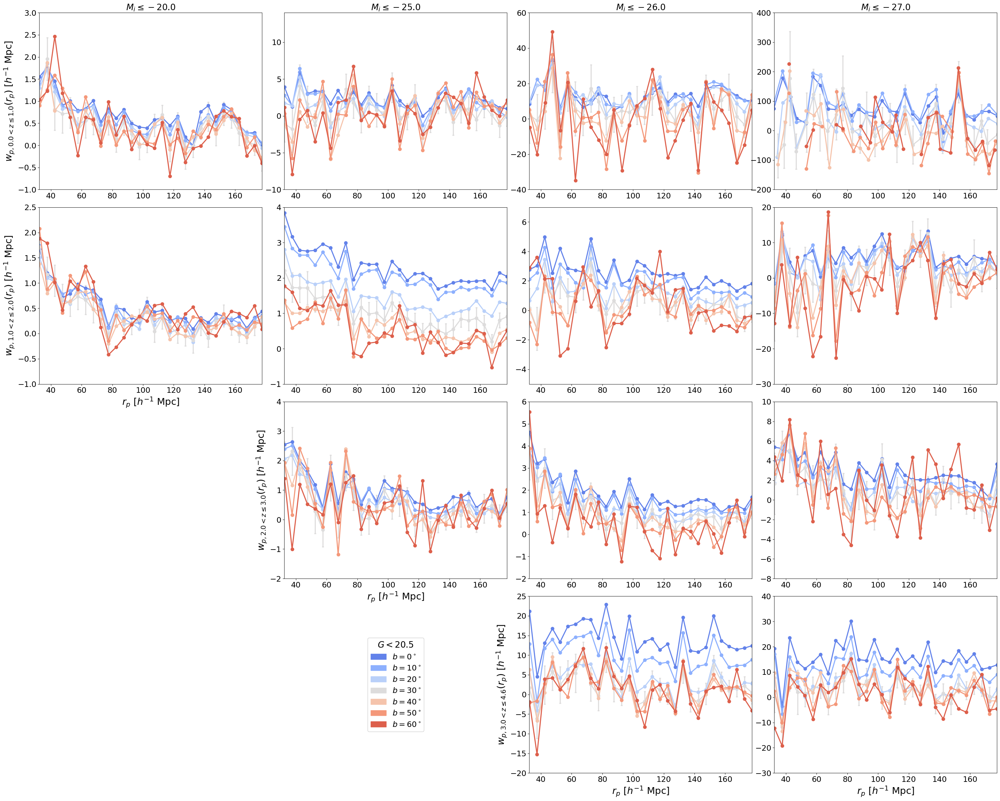

In [42]:
r = quaia.recenter(rbins_chi2) #_chi2)
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
a_zbin = {L: [] for L in L_bins}
ylims = [[[-1, 3], [-10, 14], [-40, 60], [-200, 400]], [[-1, 2.5], [-1, 4], [-5, 7], [-30, 20]], [[np.nan, np.nan], [-2, 4], [-2, 6], [-8, 10]], 
         [[np.nan, np.nan], [np.nan, np.nan], [-20, 25], [-30, 40]]]

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.1, hspace = 0.1)

H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc

for j in z_array:
    
    for i in range(len(L_bins)):

        if ((i<3) and (N_q_b[L_bins[i]][j]>N_q_b[L_bins[i+1]][j])) or (i==3):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            if j ==0:
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if scale == 'log':
                ax1.set_xscale('log')
            ax1.set_xlim(r[0], r[-1])
            ax1.set_ylim(ylims[j][i])
 
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
        else:

            ax2 = fig.add_subplot(gs[j*4+i])
            ax2.set_axis_off()
                
        for k in range(len(masks)):
                                    
            wp_zbin_i = np.load('../results/wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b_array[k]))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b_array[k]))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b_array[k])))

            if b_array[k] == 30:
                
                sigma = np.sqrt(np.diag(np.load('../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b_array[k]))))

                wp_chi2[L_bins[i]].append(wp_zbin_i)
                rpavg_chi2[L_bins[i]].append(rpavg_zbin_i)
                a_zbin[L_bins[i]].append(a)

                # matter correlation function   
                s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
                s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))

                xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
                wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
                wp_matter_chi2[L_bins[i]].append(wp_matter_zbin_i)   
            
            else: 
                sigma = 0

            # plot!

            if ((i<3) and (N_q_b[L_bins[i]][j]>N_q_b[L_bins[i+1]][j])) or (i==3):
                    
                ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5, capsize = 2.5,
                         linewidth = 2.5, color = cmap_masks[k], yerr = sigma, linestyle = '-')

                
custom_lines = [mpatches.Patch(color=cmap_masks[i]) for i in range(len(masks))]
first_legend = ax2.legend(custom_lines, [r'$b={}^\circ$'.format(b) for b in b_array], loc = 'center', title = r'$G<{}$'.format(G_hi), title_fontsize = 20)
fig.add_artist(first_legend)

plt.show()

<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:30: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_5497/636640007.py:13: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_5497/636640007.py:30: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5, capsize = 2.5,


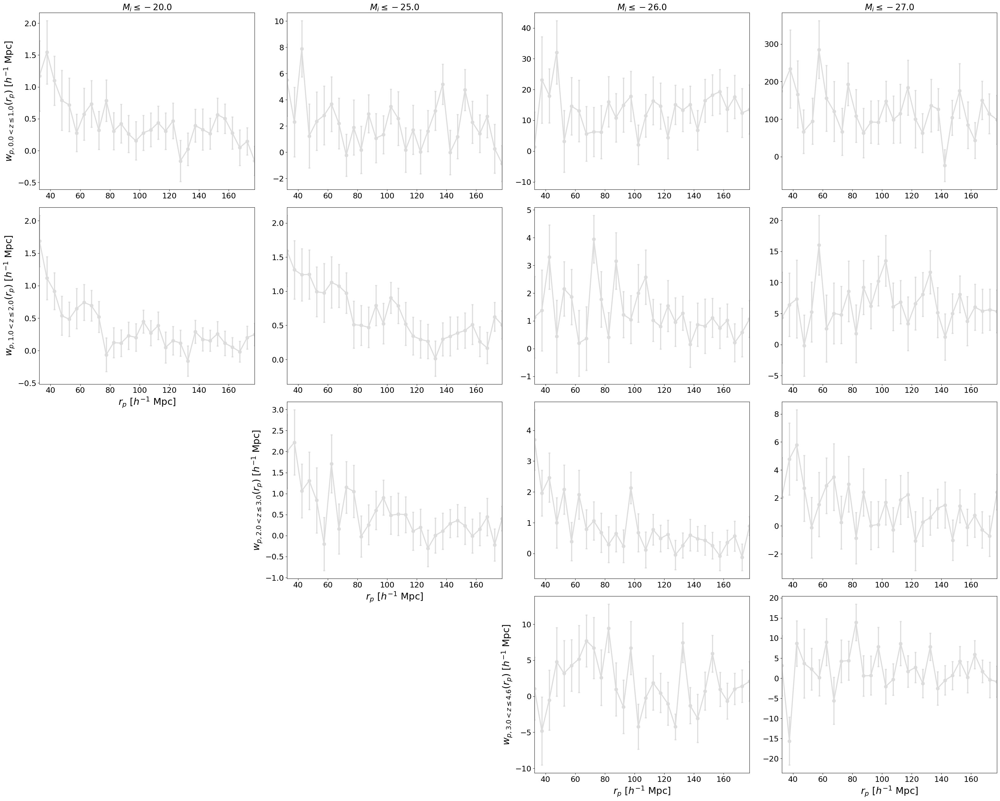

In [79]:
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)
k = 3
for j in z_array:
    
    for i in range(len(L_bins)):

        if ((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            if j ==0:
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if scale == 'log':
                ax1.set_xscale('log')
            ax1.set_xlim(r[0], r[-1])
            
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
                            
            wp_zbin_i = np.load('../results/wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k]))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k]))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k])))            
            sigma = np.sqrt(np.diag(np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, mask))))
                
            # plot!
                        
            ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5, capsize = 2.5,
                     linewidth = 2.5, color = cmap_masks[k], yerr = sigma, linestyle = '-')

plt.show()

## Test $\pi_\mathrm{max}$

In [41]:
pi_max = [100, 200, 300, 400, 500, 600, 700, 800, 900]

In [42]:
cmap_pimax = sns.color_palette("magma", n_colors = len(pi_max))
cmap_pimax

[(0.078815, 0.054184, 0.211667),
 (0.232077, 0.059889, 0.437695),
 (0.390384, 0.100379, 0.501864),
 (0.550287, 0.161158, 0.505719),
 (0.716387, 0.214982, 0.47529),
 (0.868793, 0.287728, 0.409303),
 (0.967671, 0.439703, 0.35981),
 (0.994738, 0.62435, 0.427397),
 (0.99568, 0.812706, 0.572645)]

<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:74: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:74: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_10905/2262562854.py:21: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_10905/2262562854.py:74: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,


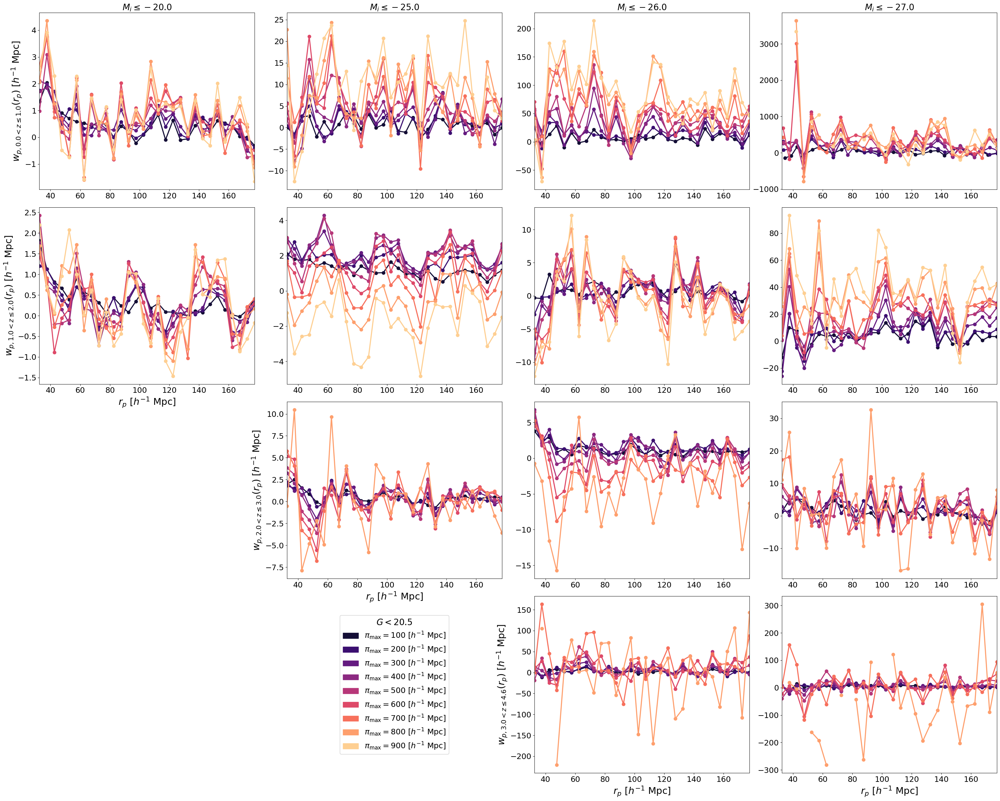

In [57]:
r = quaia.recenter(rbins_chi2) #_chi2)
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
a_zbin = {L: [] for L in L_bins}
ylims = [[[-1, 3], [-10, 14], [-40, 60], [-200, 400]], [[-1, 2.5], [-1, 4], [-5, 7], [-30, 20]], [[np.nan, np.nan], [-2, 4], [-2, 6], [-8, 10]], 
         [[np.nan, np.nan], [np.nan, np.nan], [-20, 25], [-30, 40]]]

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)

H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc

for j in z_array:
    
    for i in range(len(L_bins)):

        if ((i<3) and (N_q_b[L_bins[i]][j]>N_q_b[L_bins[i+1]][j])) or (i==3):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            if j ==0:
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if scale == 'log':
                ax1.set_xscale('log')
            ax1.set_xlim(r[0], r[-1])
            # ax1.set_ylim(ylims[j][i])
 
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
        else:

            ax2 = fig.add_subplot(gs[j*4+i])
            ax2.set_axis_off()
                
        for k in range(len(pi_max)):
                                    
            wp_zbin_i = np.load('../results/wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, pi_max[k], z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, pi_max[k], z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))

            # if pi_max[k] == 30:

            try:
                sigma = np.sqrt(np.diag(np.load('../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, pi_max[k], z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))))

            except Exception as e:
                # print(e)
                sigma=0

            wp_chi2[L_bins[i]].append(wp_zbin_i)
            rpavg_chi2[L_bins[i]].append(rpavg_zbin_i)
            a_zbin[L_bins[i]].append(a)

            # matter correlation function   
            s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
            s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))

            xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
            wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
            wp_matter_chi2[L_bins[i]].append(wp_matter_zbin_i)   
            
            # else: 
            #     sigma = 0

            # plot!

            if ((i<3) and (N_q_b[L_bins[i]][j]>N_q_b[L_bins[i+1]][j])) or (i==3):
                    
                ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,
                         linewidth = 2.5, color = cmap_pimax[k], yerr = sigma, linestyle = '-')

                
custom_lines = [mpatches.Patch(color=cmap_pimax[i]) for i in range(len(pi_max))]
first_legend = ax2.legend(custom_lines, [r'$\pi_\mathrm{{max}}={}$ $[h^{{-1}}$ Mpc]'.format(pi) for pi in pi_max], loc = 'center', title = r'$G<{}$'.format(G_hi), title_fontsize = 20)
fig.add_artist(first_legend)

plt.show()

### Test $M_{min}$

In [29]:
def wp_2h(bins, n_m, a, cosmo, wp_matter_zbin_i, rpbins = rbins_chi2, pibins = pibins, recenter = True, rpmask = True):

    if not isinstance(wp_matter_zbin_i, np.ndarray):
        
        print('computing wp_matter')
        
        # matter correlation function    
        if isinstance(rpmask, bool):
            rpmask = [rpmask]*len(quaia.recenter(rpbins))
            
        s = np.sqrt(np.sum(np.meshgrid(quaia.recenter(rpbins)[rpmask]**2, quaia.recenter(pibins)**2), axis = 0))
        s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(cosmo['h']* 100 * u.km/u.s/u.Mpc))

        xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo, r=np.ravel(s_Mpc), a=a)
        wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)

    return cf_2h(bins, n_m, a, cosmo, wp_matter_zbin_i, recenter = recenter)

In [45]:
Mmins = [11,12,13,14,15,16]

In [46]:
cmap_green = plt.get_cmap('Greens')(np.linspace(0.333, 0.999, len(Mmins)))

<>:49: SyntaxWarning: invalid escape sequence '\l'
<>:49: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15470/2411568602.py:49: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


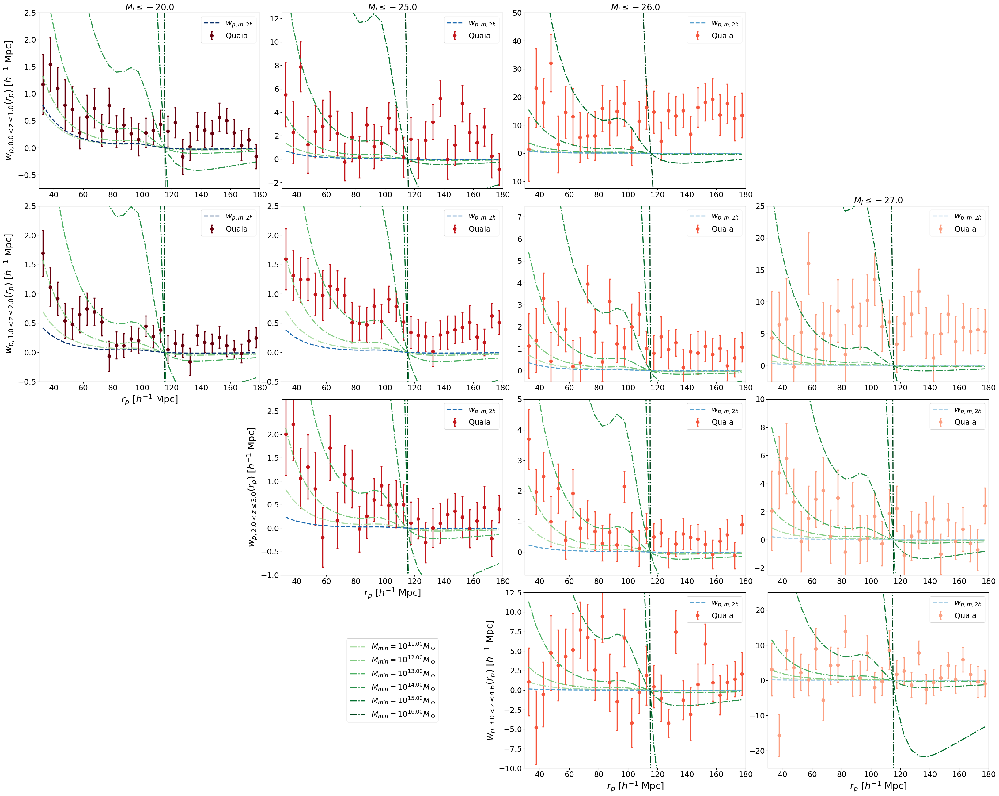

In [52]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.1, hspace = 0.1)
ylims = [[-0.75, 2.5], [-2.5, 12.5], [-12.5, 50], [-75, 375]], [[-0.5, 2.5], [-0.5, 2.5], [-0.5, 7.5], [-2.5, 25]], [[np.nan, np.nan], [-1, 2.75], [-0.75, 5], [-2.5, 10]], [[np.nan, np.nan], [np.nan, np.nan], [-10, 12.5], [-25, 25]]
m = 0
for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, mask))

            wp_zbin_i = np.load('../results/wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))            
            
            ax1.errorbar(rpavg_zbin_i, wp_zbin_i, linewidth = 2.5, marker = 'o', label = r'Quaia', color = cmap_red[::-1][i],
                        yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, capsize = 2.5, linestyle = 'none')
            if quaia.recenter(rbins_chi2)[0] < 30:
                ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                                  alpha = 0.5, label = 'scales excluded from fit')
                ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                                  alpha = 0.5)

            # matter correlation function   
            s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
            s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))

            xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
            wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
            # wp_matter_chi2[L_bins[i]].append(wp_matter_zbin_i)   
            
            # test higher Mmin values
            for k in range(len(Mmins)):
                n_m=np.ones(np.shape(bins)) #*10**f_duty[L_bins[i]][j]
                wp_2h_zbin, b_q = wp_2h(np.logspace(Mmins[k],16.8,79), n_m, a, cosmo_planck18, wp_matter_zbin_i, 
                                        recenter = False)
                ax1.plot(quaia.recenter(rbins_chi2), wp_2h_zbin, linewidth = 2.5, linestyle = '-.', color = cmap_green[k]) #,
                    
            # plot matter
            ax1.plot(quaia.recenter(rbins_chi2), wp_matter_zbin_i, linewidth = 2.5, linestyle = '--',
                     label = r'$w_{{p,m,2h}}$', color = cmap_blue[::-1][i])
            
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(quaia.recenter(rbins_chi2)[0]-2.5, quaia.recenter(rbins_chi2)[-1]+2.5)
            ax1.set_ylim(ylims[j][i])
            ax1.legend()
            
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') 
        
        else:
        
            if m == 3:
                ax1 = fig.add_subplot(gs[j*4+i])
                ax1.set_axis_off()
                custom_lines = [Line2D([0], [0], color = cmap_green[i], linestyle = '-.', linewidth = 2.5) for i in range(len(Mmins))]
                second_legend = ax1.legend(custom_lines, [r'$M_{{min}}=10^{{{:.2f}}}M_\odot$'.format(Mmin) for Mmin in Mmins], bbox_to_anchor = (0.5, 0.5), 
                                           loc='center')
                fig.add_artist(second_legend)
            m+=1

plt.show()

<>:51: SyntaxWarning: invalid escape sequence '\l'
<>:51: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15470/2151809713.py:51: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


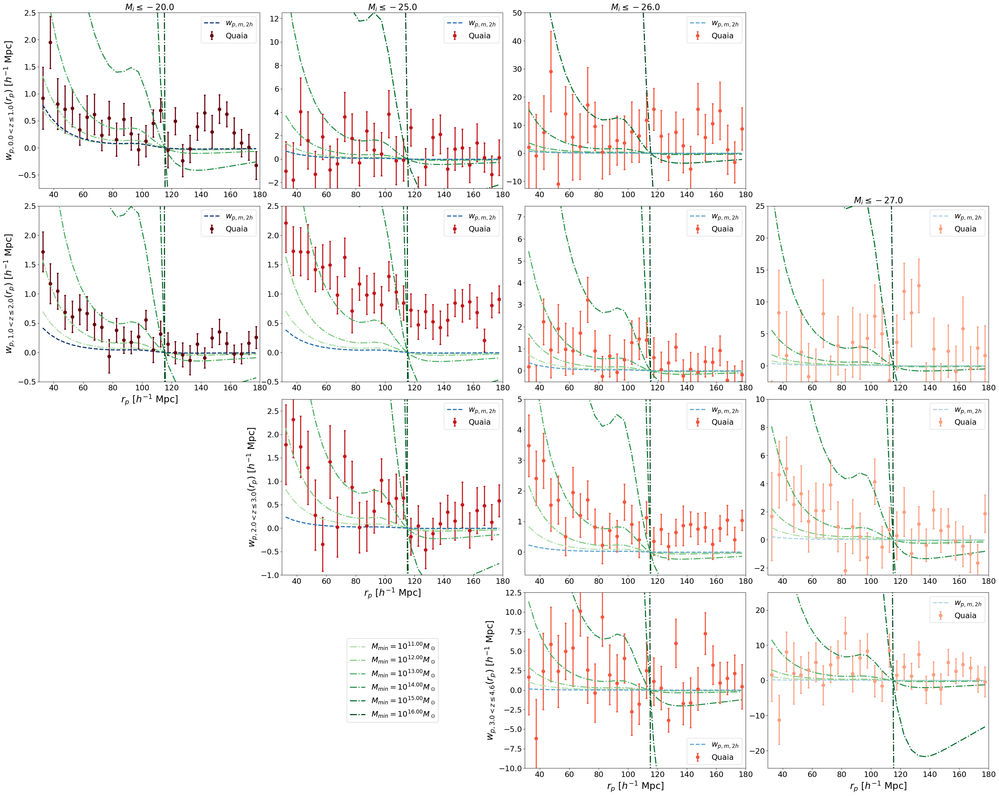

In [47]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.1, hspace = 0.1)
ylims = [[-0.75, 2.5], [-2.5, 12.5], [-12.5, 50], [-75, 375]], [[-0.5, 2.5], [-0.5, 2.5], [-0.5, 7.5], [-2.5, 25]], [[np.nan, np.nan], [-1, 2.75], [-0.75, 5], [-2.5, 10]], [[np.nan, np.nan], [np.nan, np.nan], [-10, 12.5], [-25, 25]]
m = 0
for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q_b[L_bins[i]][j]>N_q_b[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q_b[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            wp_zbin_i = np.load('../results/wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
                
            C = np.load('../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
            ax1.errorbar(rpavg_zbin_i, wp_zbin_i, linewidth = 2.5, marker = 'o', label = r'Quaia', color = cmap_red[::-1][i],
                        yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, capsize = 2.5, linestyle = 'none')
            if quaia.recenter(rbins_chi2)[0] < 30:
                ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                                  alpha = 0.5, label = 'scales excluded from fit')
                ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                                  alpha = 0.5)

            # matter correlation function   
            s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
            s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))

            xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
            wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
            
            # test higher Mmin values
            for k in range(len(Mmins)):
                n_m=np.ones(np.shape(bins)) #*10**f_duty[L_bins[i]][j]
                wp_2h_zbin, b_q = wp_2h(np.logspace(Mmins[k],16.8,79), n_m, a, cosmo_planck18, wp_matter_zbin_i, 
                                        recenter = False)
                ax1.plot(quaia.recenter(rbins_chi2), wp_2h_zbin, linewidth = 2.5, linestyle = '-.', color = cmap_green[k]) #,
                    
            # plot matter
            ax1.plot(quaia.recenter(rbins_chi2), wp_matter_zbin_i, linewidth = 2.5, linestyle = '--',
                     label = r'$w_{{p,m,2h}}$', color = cmap_blue[::-1][i])
            
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(quaia.recenter(rbins_chi2)[0]-2.5, quaia.recenter(rbins_chi2)[-1]+2.5)
            ax1.set_ylim(ylims[j][i])
            ax1.legend()
            
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') 
        
        else:
        
            if m == 3:
                ax1 = fig.add_subplot(gs[j*4+i])
                ax1.set_axis_off()
                custom_lines = [Line2D([0], [0], color = cmap_green[i], linestyle = '-.', linewidth = 2.5) for i in range(len(Mmins))]
                second_legend = ax1.legend(custom_lines, [r'$M_{{min}}=10^{{{:.2f}}}M_\odot$'.format(Mmin) for Mmin in Mmins], bbox_to_anchor = (0.5, 0.5), 
                                           loc='center')
                fig.add_artist(second_legend)
            m+=1

plt.show()

# Plot log scale

In [22]:
# Create the bins array
rmin_log = 1.0 #30 #-delta_min*offset # 0.1 # start higher # 1.4 # 30
rmax_log = 200.0 #180 #80 #+delta_max*offset # 200
nbins_log = 14 #30 #10 20 + int(delta_min+delta_max) #90 #20
rbins_chi2_log = np.logspace(np.log10(rmin_log), np.log10(rmax_log), nbins_log + 1) # Mpc/h https://github.com/manodeep/Corrfunc/issues/202
rbins_chi2_log, quaia.recenter(rbins_chi2_log), np.diff(np.log10(quaia.recenter(rbins_chi2_log)))

(array([  1.        ,   1.46002162,   2.13166312,   3.11227423,
          4.54398764,   6.63432018,   9.68625086,  14.14213562,
         20.64782369,  30.1462689 ,  44.01420421,  64.26168951,
         93.82345571, 136.98427334, 200.        ]),
 array([  1.23001081,   1.79584237,   2.62196867,   3.82813093,
          5.58915391,   8.16028552,  11.91419324,  17.39497966,
         25.3970463 ,  37.08023655,  54.13794686,  79.04257261,
        115.40386452, 168.49213667]),
 array([0.16435929, 0.16435929, 0.16435929, 0.16435929, 0.16435929,
        0.16435929, 0.16435929, 0.16435929, 0.16435929, 0.16435929,
        0.16435929, 0.16435929, 0.16435929]))

In [23]:
N_log = 24

In [24]:
delta_xlim = np.diff(np.log10(rbins_chi2_log))[0]/2
delta_xlim/2, rbins_chi2_log, 10**(np.log10(rbins_chi2_log) - 2*delta_xlim)

(0.04108982135114254,
 array([  1.        ,   1.46002162,   2.13166312,   3.11227423,
          4.54398764,   6.63432018,   9.68625086,  14.14213562,
         20.64782369,  30.1462689 ,  44.01420421,  64.26168951,
         93.82345571, 136.98427334, 200.        ]),
 array([  0.68492137,   1.        ,   1.46002162,   2.13166312,
          3.11227423,   4.54398764,   6.63432018,   9.68625086,
         14.14213562,  20.64782369,  30.1462689 ,  44.01420421,
         64.26168951,  93.82345571, 136.98427334]))

<>:74: SyntaxWarning: invalid escape sequence '\l'
<>:74: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15470/511534400.py:74: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


[            nan             nan             nan  2.32011029e+04
  1.73244066e+04  1.39708662e+04  9.95086769e+03  6.15340723e+03
  3.23186239e+03  1.48429596e+03  5.34832931e+02  2.13286048e+02
 -6.09853000e+00 -4.36173947e+01]


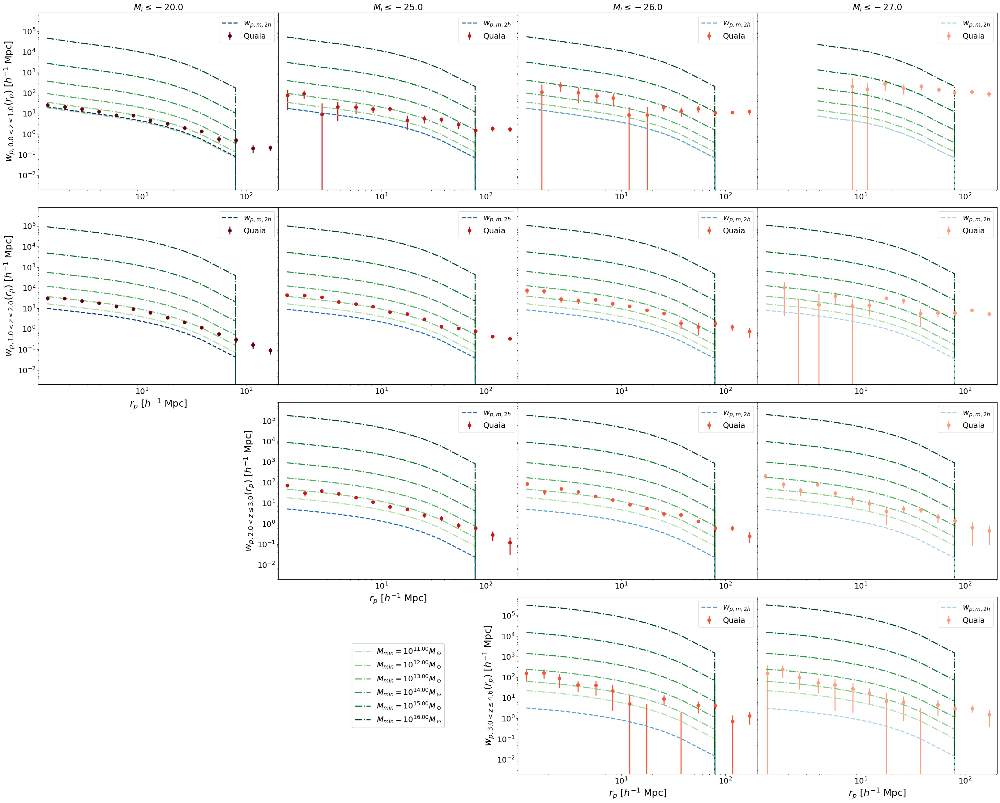

In [58]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
ylims = [[-0.75, 2.5], [-2.5, 12.5], [-12.5, 50], [-75, 375]], [[-0.5, 2.5], [-0.5, 2.5], [-0.5, 7.5], [-2.5, 25]], [[np.nan, np.nan], [-1, 2.75], [-0.75, 5], [-2.5, 10]], [[np.nan, np.nan], [np.nan, np.nan], [-10, 12.5], [-25, 25]]
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
m = 0
H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if ((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3):

            ax1 = fig.add_subplot(gs[j*4+i])

            C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo, mask))

            # try:
                
            wp_zbin_i = np.load('../results/wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))

            # except:

            #     tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, selfunc_hi_bin0, = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
            #                                                                                  bins = [z_bins, L_bins], tab_gcat_type = 'data', 
            #                                                                                   method = ['minmax', 'max'], fac_rand = fac_rand, 
            #                                                                                   mask = mask*100, percentile = True, n_bins = [None, None])
                
            #     # quasar correlation function
            #     wp_zbin_i, rpavg_zbin_i = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, nthreads = nthreads, 
            #                                                                   rbins = rbins_chi2_log, nbins = nbins_log, pimax = pimax, Om0 = Planck18.Om0, h = Planck18.h)

            #     # scale factor
            #     a = a_median(tab_datahi_mask_zbin0)
                
            #     np.save('../results/wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask), wp_zbin_i)
            #     np.save('../results/rpavg_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask), rpavg_zbin_i)
            #     np.save('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask), a)

            wp_chi2[L_bins[i]].append(wp_zbin_i)
            rpavg_chi2[L_bins[i]].append(rpavg_zbin_i)

            # matter correlation function   
            s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
            s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))

            xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
            wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
            wp_matter_chi2[L_bins[i]].append(wp_matter_zbin_i)   
            
            ax1.errorbar(rpavg_chi2[L_bins[i]][j], wp_chi2[L_bins[i]][j], linewidth = 2.5, marker = 'o', label = r'Quaia', color = cmap_red[::-1][i],
                        yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
            
            # test higher Mmin values
            for k in range(len(Mmins)):
                
                n_m=np.ones(np.shape(bins)) #*10**f_duty[L_bins[i]][j]
                wp_2h_zbin, b_q = wp_2h(np.logspace(Mmins[k],16.8,79), n_m, a, cosmo_planck18, wp_matter_chi2[L_bins[i]][j], 
                                        recenter = False)
                ax1.plot(quaia.recenter(rbins_chi2_log), wp_2h_zbin, linewidth = 2.5, linestyle = '-.', color = cmap_green[k]) #,

            if (j == 0) and (i == 3):
                print(wp_2h_zbin)
                    
            # plot matter
            ax1.plot(quaia.recenter(rbins_chi2_log), wp_matter_chi2[L_bins[i]][j], linewidth = 2.5, linestyle = '--',
                     label = r'$w_{{p,m,2h}}$', color = cmap_blue[::-1][i])
        
            if j==0:
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(rbins_chi2_log))[0] - delta_xlim), 10**(np.log10(quaia.recenter(rbins_chi2_log))[-1] + delta_xlim))
            ax1.set_yscale('log')
            ax1.legend()
            ax1.set_xscale('log')
            ax1.set_ylim(2e-3, 8e5)

            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') 
        
        else:
        
            if m == 2:
                ax1 = fig.add_subplot(gs[j*4+i])
                ax1.set_axis_off()
                custom_lines = [Line2D([0], [0], color = cmap_green[i], linestyle = '-.', linewidth = 2.5) for i in range(len(Mmins))]
                second_legend = ax1.legend(custom_lines, [r'$M_{{min}}=10^{{{:.2f}}}M_\odot$'.format(Mmin) for Mmin in Mmins], bbox_to_anchor = (0.5, 0.5), 
                                           loc='center')
                fig.add_artist(second_legend)
            m+=1

plt.show()

<>:57: SyntaxWarning: invalid escape sequence '\l'
<>:57: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15470/820510976.py:57: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


[          nan           nan           nan           nan           nan
           nan 8577.19708051 5939.51900763 3221.75613837 1285.99404993
  503.53792198  215.81066222   -9.06150821  -43.97490079]


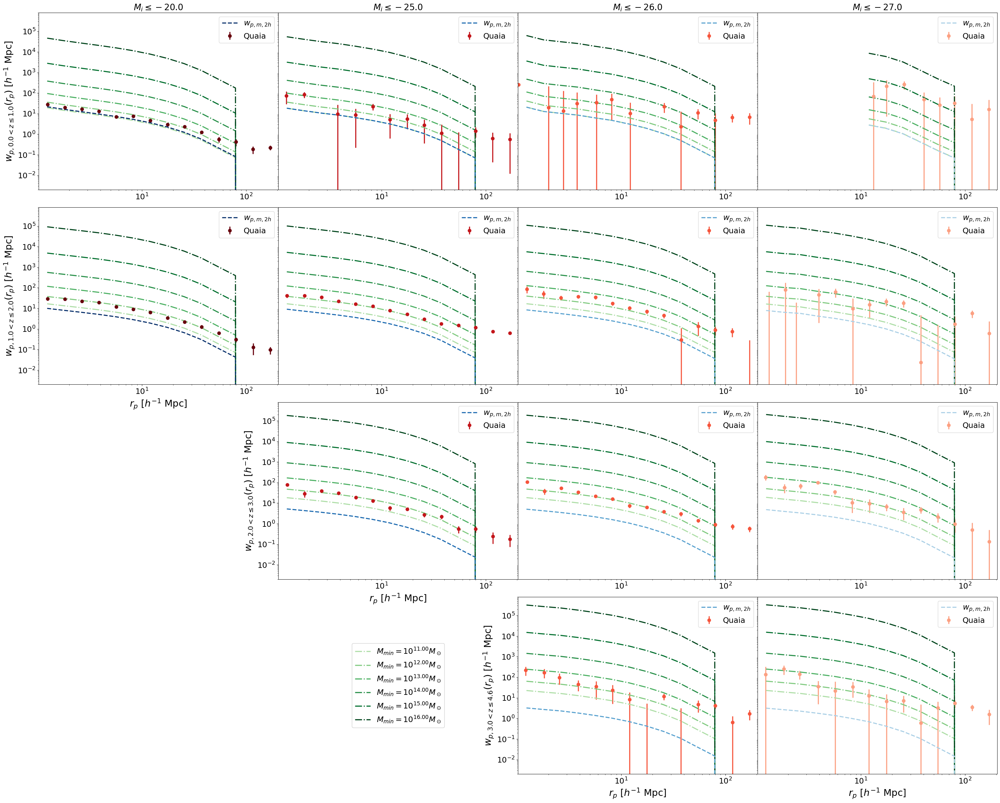

In [59]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1) # 0.1
ylims = [[-0.75, 2.5], [-2.5, 12.5], [-12.5, 50], [-75, 375]], [[-0.5, 2.5], [-0.5, 2.5], [-0.5, 7.5], [-2.5, 25]], [[np.nan, np.nan], [-1, 2.75], [-0.75, 5], [-2.5, 10]], [[np.nan, np.nan], [np.nan, np.nan], [-10, 12.5], [-25, 25]]
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
m = 0
H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if ((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3):

            ax1 = fig.add_subplot(gs[j*4+i])

            C = np.load('../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo, b))
                
            wp_zbin_i = np.load('../results/wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))

            wp_chi2[L_bins[i]].append(wp_zbin_i)
            rpavg_chi2[L_bins[i]].append(rpavg_zbin_i)

            # matter correlation function   
            s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
            s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))

            xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
            wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
            wp_matter_chi2[L_bins[i]].append(wp_matter_zbin_i)   
            
            ax1.errorbar(rpavg_chi2[L_bins[i]][j], wp_chi2[L_bins[i]][j], linewidth = 2.5, marker = 'o', label = r'Quaia', color = cmap_red[::-1][i],
                        yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
            
            # test higher Mmin values
            for k in range(len(Mmins)):
                
                n_m=np.ones(np.shape(bins)) #*10**f_duty[L_bins[i]][j]
                wp_2h_zbin, b_q = wp_2h(np.logspace(Mmins[k],16.8,79), n_m, a, cosmo_planck18, wp_matter_chi2[L_bins[i]][j], 
                                        recenter = False)
                ax1.plot(quaia.recenter(rbins_chi2_log), wp_2h_zbin, linewidth = 2.5, linestyle = '-.', color = cmap_green[k]) #,

            if (j == 0) and (i == 3):
                print(wp_2h_zbin)
                    
            # plot matter
            ax1.plot(quaia.recenter(rbins_chi2_log), wp_matter_chi2[L_bins[i]][j], linewidth = 2.5, linestyle = '--',
                     label = r'$w_{{p,m,2h}}$', color = cmap_blue[::-1][i])
        
            if j==0:
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(rbins_chi2_log))[0] - delta_xlim), 10**(np.log10(quaia.recenter(rbins_chi2_log))[-1] + delta_xlim))
            ax1.set_yscale('log')
            ax1.legend()
            ax1.set_ylim(2e-3, 8e5)
            ax1.set_xscale('log')
            
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') 
        
        else:
        
            if m == 2:
                ax1 = fig.add_subplot(gs[j*4+i])
                ax1.set_axis_off()
                custom_lines = [Line2D([0], [0], color = cmap_green[i], linestyle = '-.', linewidth = 2.5) for i in range(len(Mmins))]
                second_legend = ax1.legend(custom_lines, [r'$M_{{min}}=10^{{{:.2f}}}M_\odot$'.format(Mmin) for Mmin in Mmins], bbox_to_anchor = (0.5, 0.5), 
                                           loc='center')
                fig.add_artist(second_legend)
            m+=1

plt.show()

<>:62: SyntaxWarning: invalid escape sequence '\l'
<>:62: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15299/1446310079.py:62: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


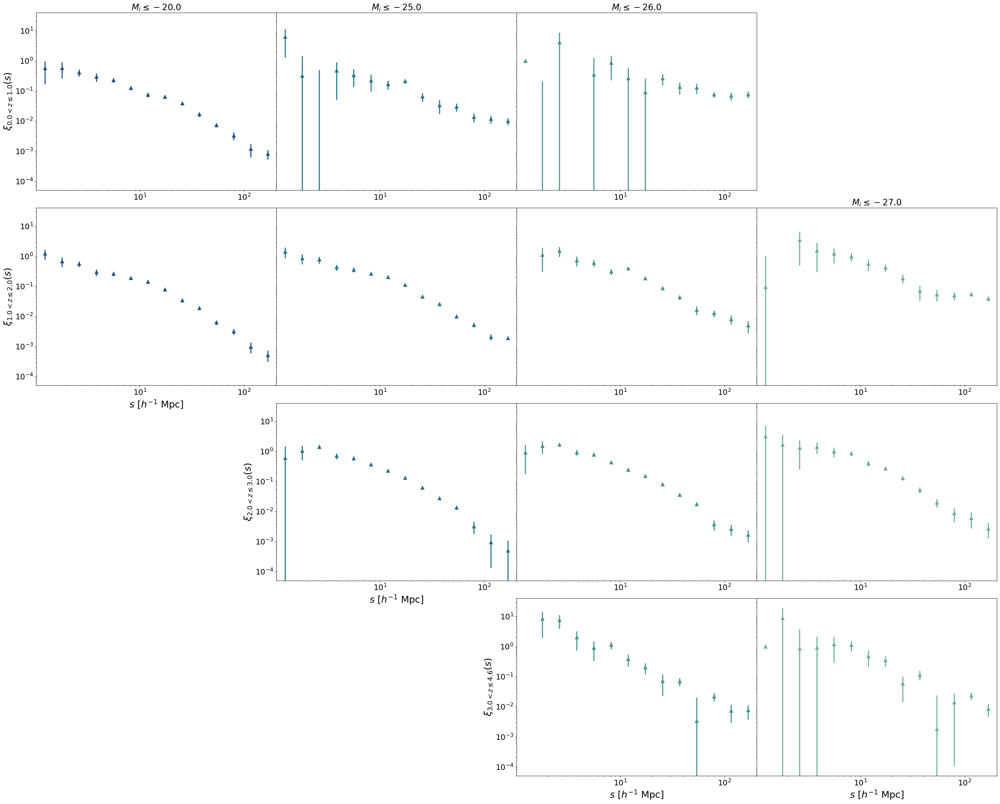

In [46]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
ylims = [[-0.75, 2.5], [-2.5, 12.5], [-12.5, 50], [-75, 375]], [[-0.5, 2.5], [-0.5, 2.5], [-0.5, 7.5], [-2.5, 25]], [[np.nan, np.nan], [-1, 2.75], [-0.75, 5], [-2.5, 10]], [[np.nan, np.nan], [np.nan, np.nan], [-10, 12.5], [-25, 25]]
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
m = 0
for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            C = np.load('../results/cov_xi_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo, mask))

            try:
                
                wp_zbin_i = np.load('../results/xi_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))

            except:

                # tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, selfunc_hi_bin0, = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                #                                                                              bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                #                                                                               method = ['minmax', 'max'], fac_rand = fac_rand, 
                #                                                                               mask = mask*100, percentile = True, n_bins = [None, None])
                
                # # quasar correlation function
                # wp_zbin_i, rpavg_zbin_i = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, nthreads = nthreads, 
                #                                                               rbins = rbins_chi2_log, nbins = nbins_log, pimax = pimax, Om0 = Planck18.Om0, h = Planck18.h)

                # # scale factor
                # a = a_median(tab_datahi_mask_zbin0)
                
                # np.save('../results/xi_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask), wp_zbin_i)
                # np.save('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask), a)
                print('../results/xi_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy not yet loaded'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))

            # wp_chi2[L_bins[i]].append(wp_zbin_i)

            # # matter correlation function   
            # s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
            # s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))

            # xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
            # wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
            # wp_matter_chi2[L_bins[i]].append(wp_matter_zbin_i)   
            
            ax1.errorbar(quaia.recenter(rbins_chi2_log), wp_zbin_i, linewidth = 2.5, marker = '^', label = r'Quaia', color = cmap_xi[i],
                        yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none') #capsize = 2.5, 
            
            # if (j == 0) and (i == 3):
            #     print(wp_2h_zbin)
                    
            # # plot matter
            # ax1.plot(quaia.recenter(rbins_chi2_log), wp_matter_chi2[L_bins[i]][j], linewidth = 2.5, linestyle = '--',
            #          label = r'$w_{{p,m,2h}}$', color = cmap_blue[::-1][i])
        
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(rbins_chi2_log))[0] - delta_xlim), 10**(np.log10(quaia.recenter(rbins_chi2_log))[-1] + delta_xlim))
            ax1.set_yscale('log')
            ax1.set_ylim(5e-5,4e1)
            # ax1.legend()
            ax1.set_xscale('log')
            
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$\xi_{{{:.1f}<z \leq{:.1f}}}(s)$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$s$ $[h^{-1}$ Mpc]') 
        
        else:
        
            if m == 2:
                ax1 = fig.add_subplot(gs[j*4+i])
                ax1.set_axis_off()
                # custom_lines = [Line2D([0], [0], color = cmap_green[i], linestyle = '-.', linewidth = 2.5) for i in range(len(Mmins))]
                # second_legend = ax1.legend(custom_lines, [r'$M_{{min}}=10^{{{:.2f}}}M_\odot$'.format(Mmin) for Mmin in Mmins], bbox_to_anchor = (0.5, 0.5), 
                #                            loc='center')
                # fig.add_artist(second_legend)
            m+=1

plt.show()

<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:21: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15299/2417219857.py:19: SyntaxWarning: invalid escape sequence '\l'
  yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
/tmp/ipykernel_15299/2417219857.py:21: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


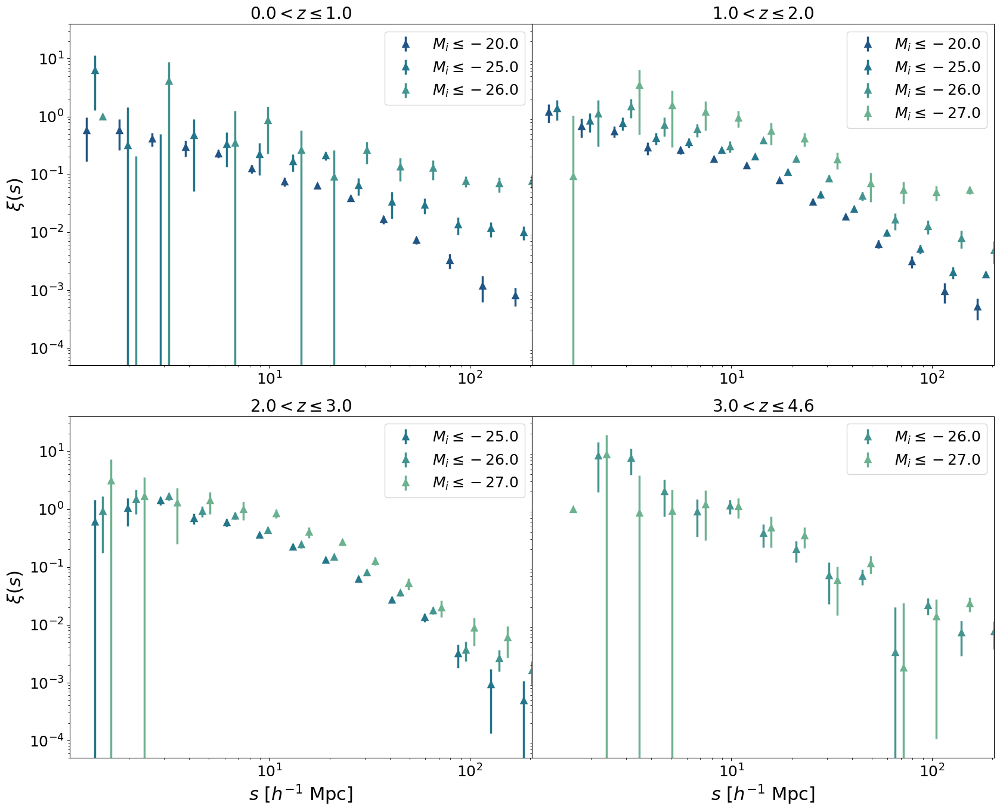

In [53]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])

    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            C = np.load('../results/cov_xi_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo, mask))
            wp_zbin_i = np.load('../results/xi_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))

            ax1.errorbar(10**(np.log10(quaia.recenter(rbins_chi2_log)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = '^', color = cmap_xi[i],
                        yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5

            ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(rbins_chi2_log))[0] - delta_xlim), 10**(np.log10(quaia.recenter(rbins_chi2_log))[-1] + delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(5e-5,4e1)
            
            if j%2==0:
                ax1.set_ylabel(r"$\xi(s)$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
            if j > 1:
                ax1.set_xlabel(r'$s$ $[h^{-1}$ Mpc]') 
            ax1.legend()

plt.savefig('../figures/threshold_xi_log.pdf', bbox_inches = 'tight')

plt.show()

<>:25: SyntaxWarning: invalid escape sequence '\l'
<>:25: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15470/573121230.py:25: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


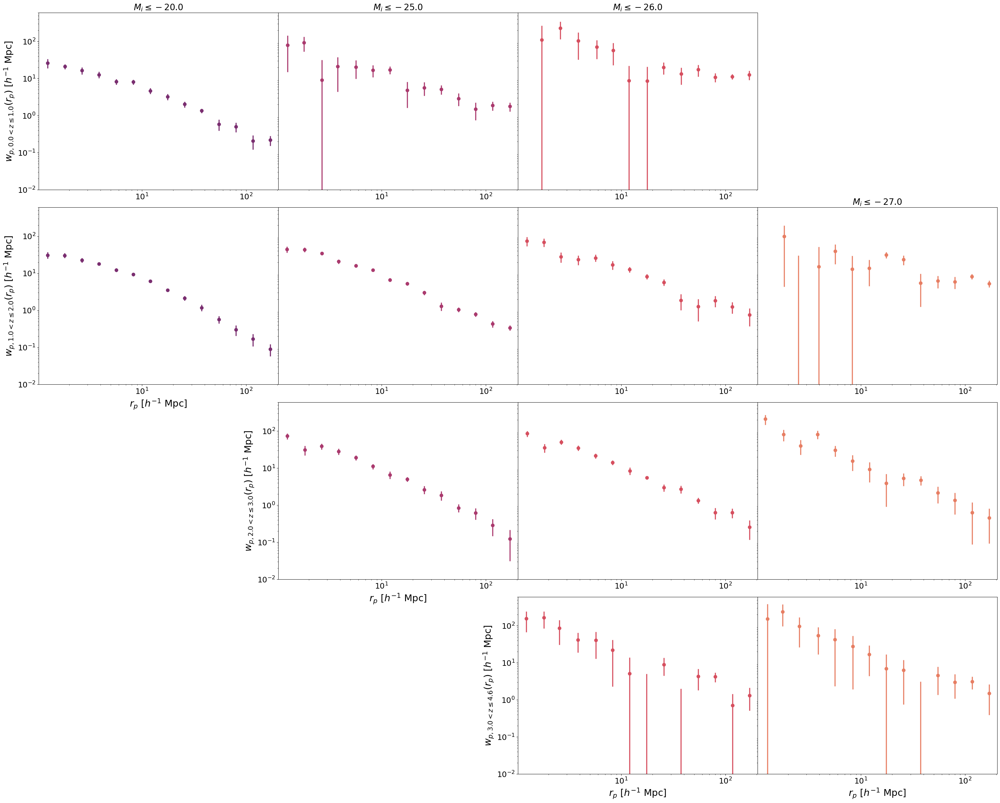

In [60]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
ylims = [[-0.75, 2.5], [-2.5, 12.5], [-12.5, 50], [-75, 375]], [[-0.5, 2.5], [-0.5, 2.5], [-0.5, 7.5], [-2.5, 25]], [[np.nan, np.nan], [-1, 2.75], [-0.75, 5], [-2.5, 10]], [[np.nan, np.nan], [np.nan, np.nan], [-10, 12.5], [-25, 25]]
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
m = 0
for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo, mask))                
            wp_zbin_i = np.load('../results/wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))
            
            ax1.errorbar(rpavg_zbin_i, wp_zbin_i, linewidth = 2.5, marker = 'o', label = r'Quaia', color = cmap_rocket[i],
                        yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none') #capsize = 2.5

            if j==0 or ((j == 1) and  (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(rbins_chi2_log))[0] - delta_xlim), 10**(np.log10(quaia.recenter(rbins_chi2_log))[-1] + delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(1e-2, 6e2)
            
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') 
        
        else:
        
            if m == 2:
                ax1 = fig.add_subplot(gs[j*4+i])
                ax1.set_axis_off()
            m+=1

plt.show()

<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_1881/2664766865.py:29: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


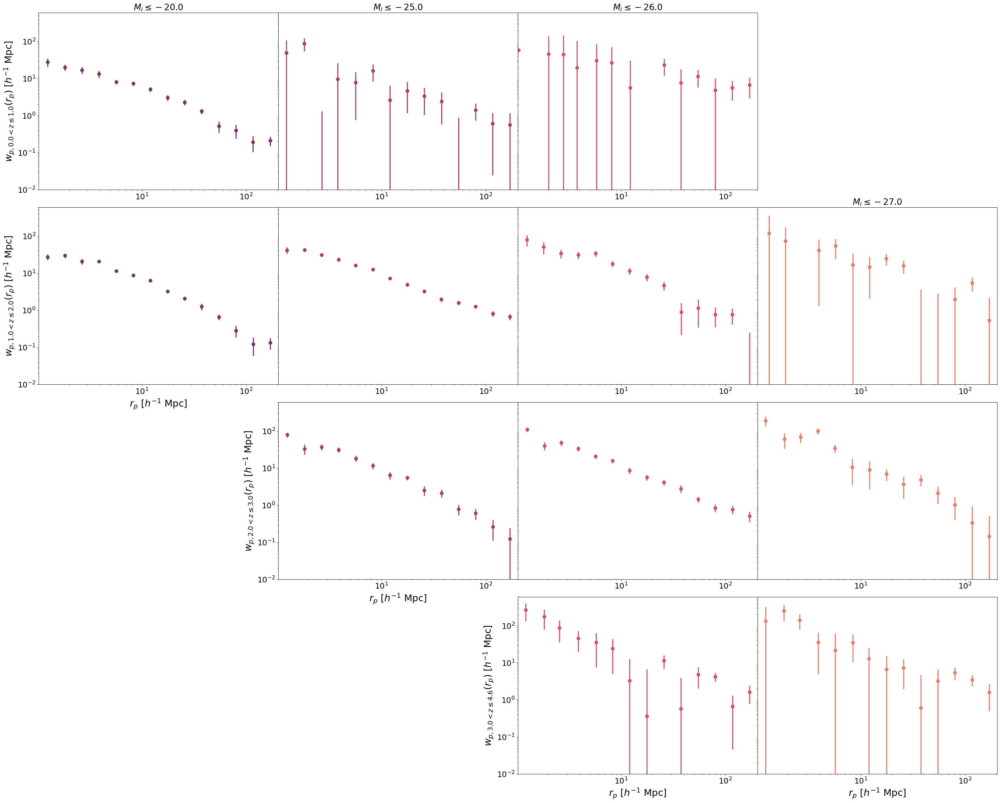

In [57]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
ylims = [[-0.75, 2.5], [-2.5, 12.5], [-12.5, 50], [-75, 375]], [[-0.5, 2.5], [-0.5, 2.5], [-0.5, 7.5], [-2.5, 25]], [[np.nan, np.nan], [-1, 2.75], [-0.75, 5], [-2.5, 10]], [[np.nan, np.nan], [np.nan, np.nan], [-10, 12.5], [-25, 25]]
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
m = 0
for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            C = np.load('../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo, b))
                
            wp_zbin_i = np.load('../results/wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))) 
            
            ax1.errorbar(rpavg_zbin_i, wp_zbin_i, linewidth = 2.5, marker = 'o', label = r'Quaia', color = cmap_rocket[i],
                        yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none') #capsize = 2.5
        
            if j==0 or ((j == 1) and  (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(rbins_chi2_log))[0] - delta_xlim), 10**(np.log10(quaia.recenter(rbins_chi2_log))[-1] + delta_xlim))
            ax1.set_yscale('log')
            # ax1.legend()
            ax1.set_xscale('log')
            ax1.set_ylim(1e-2, 6e2)
            
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') 
        
        else:
        
            if m == 2:
                ax1 = fig.add_subplot(gs[j*4+i])
                ax1.set_axis_off()
            m+=1

plt.show()

<>:20: SyntaxWarning: invalid escape sequence '\l'
<>:22: SyntaxWarning: invalid escape sequence '\l'
<>:20: SyntaxWarning: invalid escape sequence '\l'
<>:22: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15470/1107952477.py:20: SyntaxWarning: invalid escape sequence '\l'
  yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
/tmp/ipykernel_15470/1107952477.py:22: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


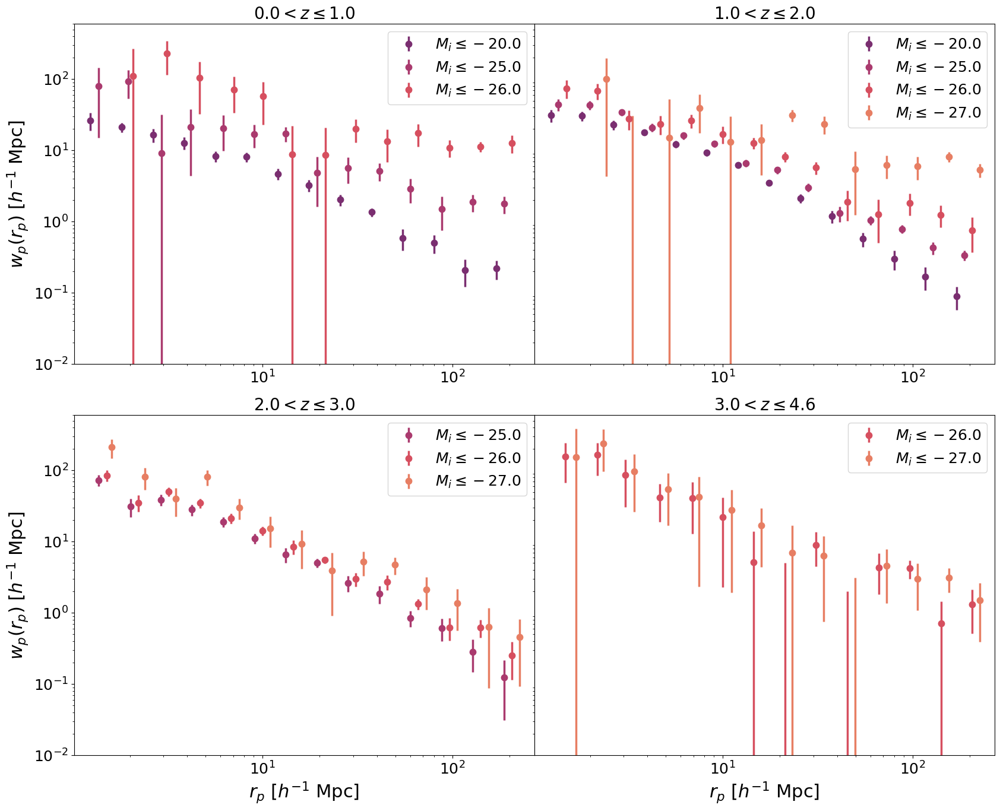

In [61]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])

    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo, mask))                
            wp_zbin_i = np.load('../results/wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))
            
            ax1.errorbar(10**(np.log10(rpavg_zbin_i) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'o', color = cmap_rocket[i],
                        yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5

            ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(rbins_chi2_log))[0] - delta_xlim), 10**(np.log10(quaia.recenter(rbins_chi2_log))[-1] + 5/2*delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(1e-2, 6e2)
            
            if j%2==0:
                ax1.set_ylabel(r"$w_p(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
            if j > 1:
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') 
            ax1.legend()

plt.show()

<>:20: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:20: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15470/1880309074.py:20: SyntaxWarning: invalid escape sequence '\l'
  yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
/tmp/ipykernel_15470/1880309074.py:24: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


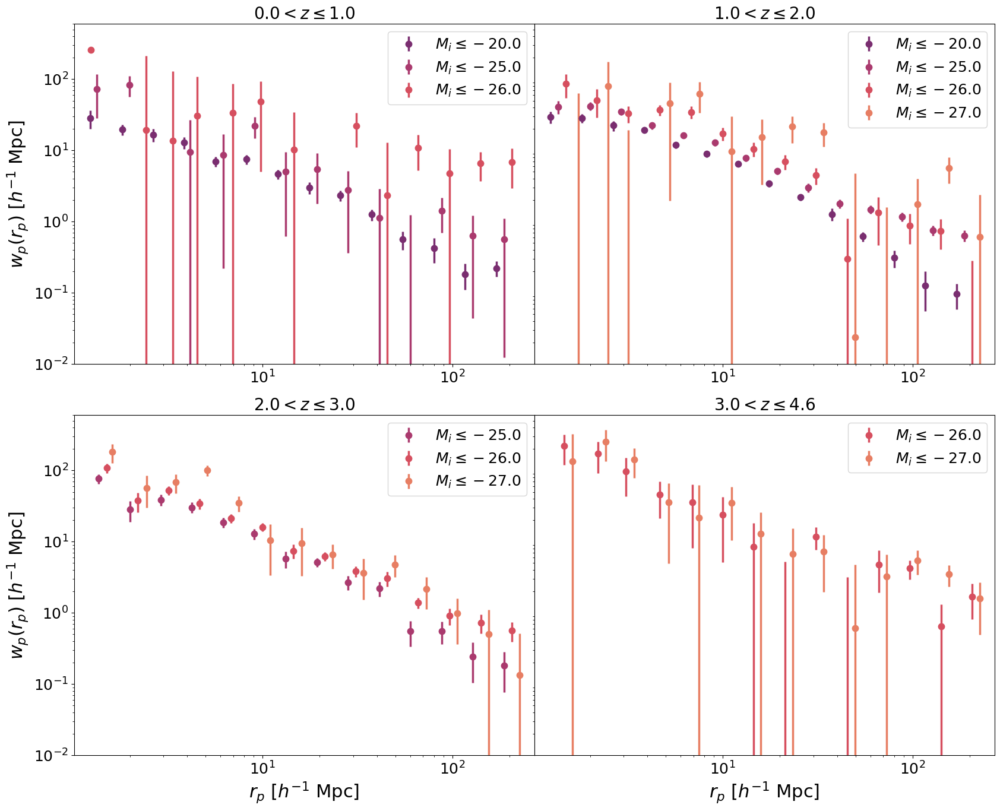

In [62]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])

    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            C = np.load('../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo, b))                
            wp_zbin_i = np.load('../results/wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
            
            ax1.errorbar(10**(np.log10(rpavg_zbin_i) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'o', color = cmap_rocket[i],
                        yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
        
            # if j==0 or ((j == 1) and  (i == 3)):
            #     ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(rbins_chi2_log))[0] - delta_xlim), 10**(np.log10(quaia.recenter(rbins_chi2_log))[-1] + 5/2*delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(1e-2, 6e2)
            
            if j%2==0:
                ax1.set_ylabel(r"$w_p(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
            if j > 1:
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') 
            ax1.legend()

plt.show()

<>:32: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15299/3709451817.py:32: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


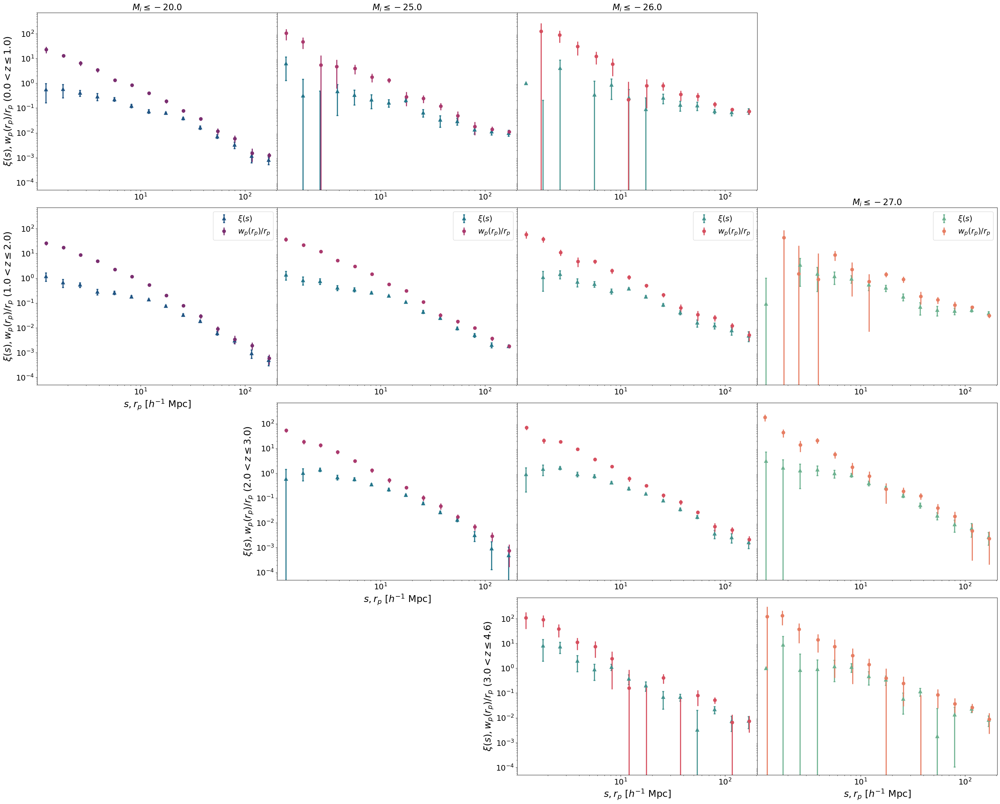

In [50]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
ylims = [[-0.75, 2.5], [-2.5, 12.5], [-12.5, 50], [-75, 375]], [[-0.5, 2.5], [-0.5, 2.5], [-0.5, 7.5], [-2.5, 25]], [[np.nan, np.nan], [-1, 2.75], [-0.75, 5], [-2.5, 10]], [[np.nan, np.nan], [np.nan, np.nan], [-10, 12.5], [-25, 25]]
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
m = 0
for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            C = np.load('../results/cov_xi_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo, mask))
            wp_zbin_i = np.load('../results/xi_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))

            ax1.errorbar(quaia.recenter(rbins_chi2_log), wp_zbin_i, linewidth = 2.5, marker = '^', label = r'$\xi(s)$', color = cmap_xi[i],
                        yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, capsize = 2.5, linestyle = 'none')

            C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo))
                
            wp_zbin_i = np.load('../results/wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            
            ax1.errorbar(rpavg_zbin_i, wp_zbin_i/rpavg_zbin_i, linewidth = 2.5, marker = 'o', label = r'$w_p(r_p)/r_p$', color = cmap_rocket[i],
                        yerr = np.sqrt(np.diag(C))/rpavg_zbin_i, markeredgewidth = 2.5, linestyle = 'none') #capsize = 2.5
            
            if j==0 or ((j == 1) and  (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(rbins_chi2_log))[0] - delta_xlim), 10**(np.log10(quaia.recenter(rbins_chi2_log))[-1] + delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            # ax1.set_ylim(1e-2, 6e2)
            ax1.set_ylim(5e-5,7e2)

            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$\xi(s),w_p(r_p)/r_p$ $({:.1f}<z \leq{:.1f})$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$s,r_p$ $[h^{-1}$ Mpc]') 

            if j == 1:
                ax1.legend()
        
        else:
        
            if m == 2:
                ax1 = fig.add_subplot(gs[j*4+i])
                ax1.set_axis_off()
            m+=1

plt.show()

In [63]:
cmap_grey = plt.get_cmap('Greys')(np.linspace(0.333, 0.999, len(L_bins)))

<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15299/2007062397.py:19: SyntaxWarning: invalid escape sequence '\l'
  yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
/tmp/ipykernel_15299/2007062397.py:27: SyntaxWarning: invalid escape sequence '\l'
  yerr = np.sqrt(np.diag(C))/rpavg_zbin_i, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
/tmp/ipykernel_15299/2007062397.py:29: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


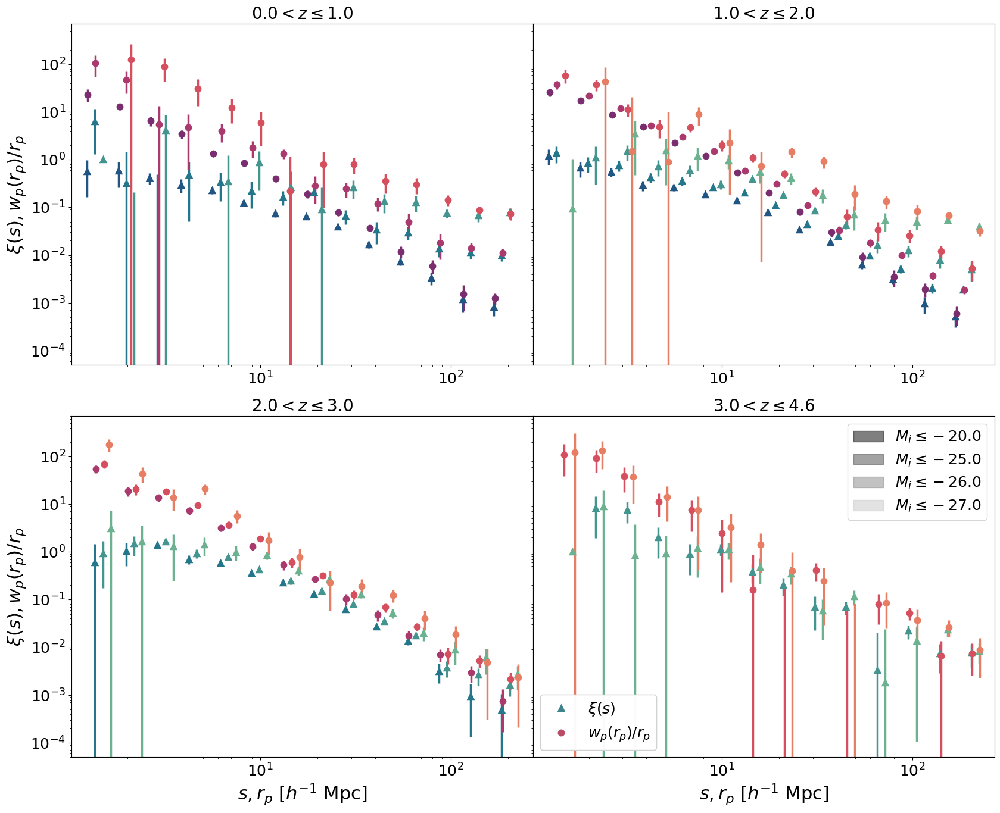

In [52]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])

    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            C = np.load('../results/cov_xi_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo, mask))
            wp_zbin_i = np.load('../results/xi_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))

            ax1.errorbar(10**(np.log10(quaia.recenter(rbins_chi2_log)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = '^', color = cmap_xi[i],
                        yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5

            
            C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo))                
            wp_zbin_i = np.load('../results/wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            
            ax1.errorbar(10**(np.log10(rpavg_zbin_i) + i*delta_xlim/2), wp_zbin_i/rpavg_zbin_i, linewidth = 2.5, marker = 'o', color = cmap_rocket[i],
                        yerr = np.sqrt(np.diag(C))/rpavg_zbin_i, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5

            ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(rbins_chi2_log))[0] - delta_xlim), 10**(np.log10(quaia.recenter(rbins_chi2_log))[-1] + 5/2*delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(5e-5,7e2)
            
            if j%2==0:
                ax1.set_ylabel(r"$\xi(s),w_p(r_p)/r_p$")
            else:
                ax1.set_yticks([])
            if j > 1:
                ax1.set_xlabel(r'$s,r_p$ $[h^{-1}$ Mpc]') 
            # ax1.legend()

custom_lines = [mpatches.Patch(color=cmap_grey[::-1][i], alpha = 0.5) for i in range(len(L_bins))]
first_legend = plt.legend(custom_lines, [r'$M_i\leq{}$'.format(L_bins[i]) for i in range(len(L_bins))])
fig.add_artist(first_legend)

custom_lines = [Line2D([0], [0], color = np.mean(cmap_xi, axis = 0), linestyle = 'none', marker = '^', linewidth = 2.5, markeredgewidth = 2.5),
                Line2D([0], [0], color = np.mean(cmap_rocket, axis = 0), linestyle = 'none', marker = 'o',linewidth = 2.5, markeredgewidth = 2.5)]
second_legend = ax1.legend(custom_lines, [r'$\xi(s)$', r'$w_p(r_p)/r_p$'], loc = 'lower left')
fig.add_artist(second_legend)

plt.savefig('../figures/threshold_clustering_log.pdf', bbox_inches = 'tight')

plt.show()

<>:31: SyntaxWarning: invalid escape sequence '\l'
<>:34: SyntaxWarning: invalid escape sequence '\g'
<>:31: SyntaxWarning: invalid escape sequence '\l'
<>:34: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_13225/1176972650.py:31: SyntaxWarning: invalid escape sequence '\l'
  ax1.errorbar(rpavg_chi2, wp_chi2, marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, #capsize = 2.5,
/tmp/ipykernel_13225/1176972650.py:34: SyntaxWarning: invalid escape sequence '\g'
  ax1.set_title('${}\geq M_i>{}$'.format(L_array[j], L_array[j+1]))


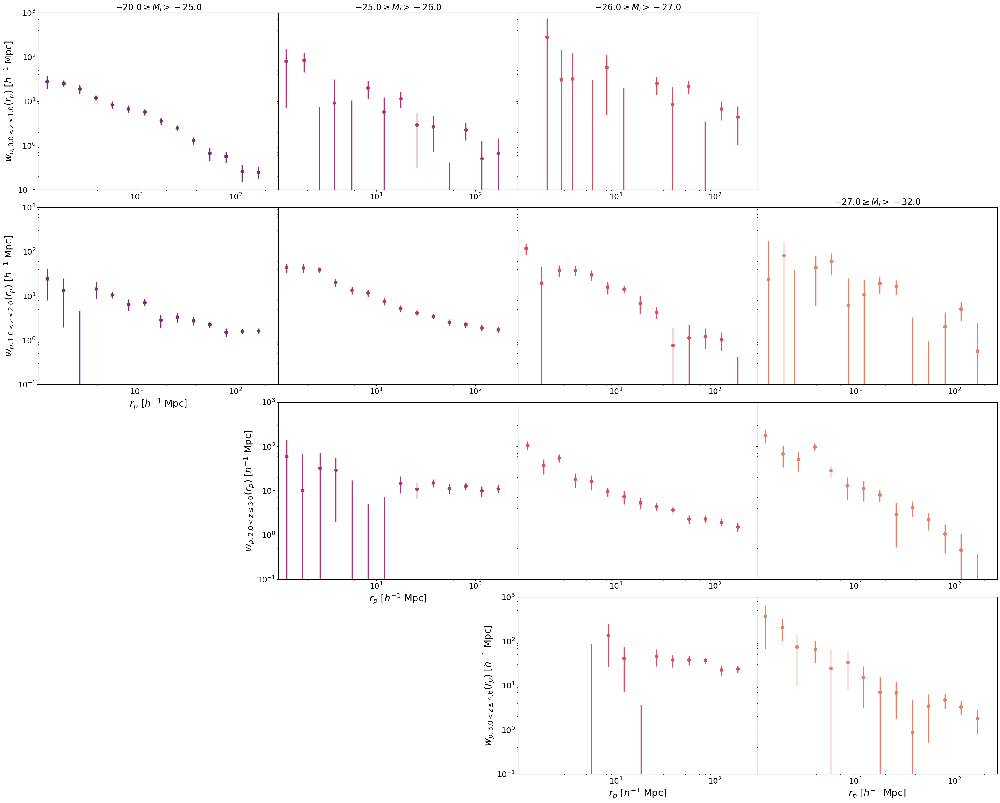

In [60]:
# plot!
r = quaia.recenter(rbins_chi2) #_chi2)
ylim = 7e-4, 2e2 #4e2

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

for i in range(len(z_array)):
    
    for j in range(len(L_array[::-1])-1):
    
        try: 
            
            if np.round(N_cut_b[::-1][j][i]/1000)>1:
    
                ax1 = fig.add_subplot(gs[i*4+j])
    
                wp_chi2 = np.load('../results/wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmin{}Lmax{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[i], z_bins[i+1], L_array[j+1], L_array[j], cosmo, b))
                rpavg_chi2 = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmin{}Lmax{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[i], z_bins[i+1], L_array[j+1], L_array[j], cosmo, b))
                try:
                    sigma = np.sqrt(np.diag(np.load(
                        '../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmin{}Lmax{}_N{}_{}_MC_b{}.npy'.format(
                            G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[i], z_bins[i+1], L_array[j+1], L_array[j], N_log, cosmo, b))))
                except Exception as e:

                    print(e)
                    sigma = 0

                ax1.errorbar(rpavg_chi2, wp_chi2, marker = 'o', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]), markeredgewidth = 2.5, #capsize = 2.5,
                         linewidth = 2.5, yerr = sigma, linestyle = 'None', color = cmap_rocket[j]) # color = cmap_blue[::-1][j]
                if (i ==0) or ((j == 3) and (i == 1)):
                    ax1.set_title('${}\geq M_i>{}$'.format(L_array[j], L_array[j+1]))
                # if scale == 'log':
                ax1.set_xscale('log')
                ax1.set_yscale('log')
                ax1.set_xlim(10**(np.log10(quaia.recenter(rbins_chi2_log))[0] - delta_xlim), 10**(np.log10(quaia.recenter(rbins_chi2_log))[-1] + 5/2*delta_xlim))
                ax1.set_ylim(1e-1, 1e3)
                # ax1.set_ylim(ylim)
                if i > 2 or ((i==1) and (j == 0)) or ((i==2) and (j==1)):
                    ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
                if j==0 or ((i==2) and (j == 1)) or ((i==3) and (j == 2)):
                    ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[i], z_bins[i+1]))
                else:
                    ax1.set_yticklabels([])
                    
        except Exception as e:                                                                       

            print(e)

# plt.savefig('../figures/bins_wp_b.pdf', bbox_inches = 'tight')

plt.show()

### Test the mask

<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:66: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:66: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_15470/1906332940.py:21: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_15470/1906332940.py:66: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5, capsize = 2.5,


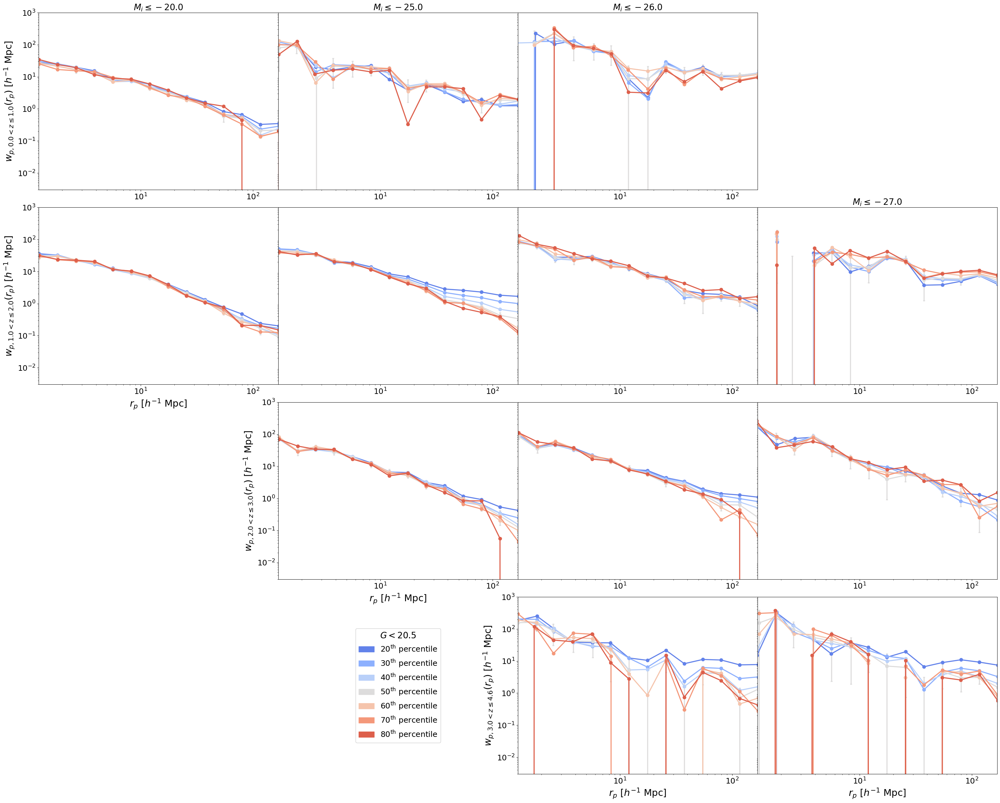

In [64]:
r = quaia.recenter(rbins_chi2_log) #_chi2)
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
a_zbin = {L: [] for L in L_bins}
ylims = [[[-1, 3], [-10, 14], [-40, 60], [-200, 400]], [[-1, 2.5], [-1, 4], [-5, 7], [-30, 20]], [[np.nan, np.nan], [-2, 4], [-2, 6], [-8, 10]], 
         [[np.nan, np.nan], [np.nan, np.nan], [-20, 25], [-30, 40]]]

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc

for j in z_array:
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            if j==0 or ((j == 1) and  (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if scale == 'log':
                ax1.set_xscale('log')
            ax1.set_xlim(r[0], r[-1])
            ax1.set_ylim(3e-3,1e3)
            ax1.set_xscale('log')
            ax1.set_yscale('log')
            
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
                
            for k in range(len(masks)):
                                        
                wp_zbin_i = np.load('../results/wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(
                    G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k]))
                rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(
                    G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k]))
                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k])))
          
                if masks[k] == 0.5:
                    
                    sigma = np.sqrt(np.diag(np.load('../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(
                        G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo, masks[k]))))
    
                    wp_chi2[L_bins[i]].append(wp_zbin_i)
                    rpavg_chi2[L_bins[i]].append(rpavg_zbin_i)
                    a_zbin[L_bins[i]].append(a)
    
                    # matter correlation function   
                    s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
                    s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))
    
                    xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
                    wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
                    wp_matter_chi2[L_bins[i]].append(wp_matter_zbin_i)   
                
                else: 
                    sigma = 0

            # plot!
                    
                ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5, capsize = 2.5,
                         linewidth = 2.5, color = cmap_masks[k], yerr = sigma, linestyle = '-')

        else:

            ax2 = fig.add_subplot(gs[j*4+i])
            ax2.set_axis_off()

                
custom_lines = [mpatches.Patch(color=cmap_masks[i]) for i in range(len(masks))]
first_legend = ax2.legend(custom_lines, [r'${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100) for mask in masks], loc = 'center', title = r'$G<{}$'.format(G_hi), title_fontsize = 20)
fig.add_artist(first_legend)

plt.show()

<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:64: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:64: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_10905/2803190952.py:21: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_10905/2803190952.py:64: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5, capsize = 2.5,


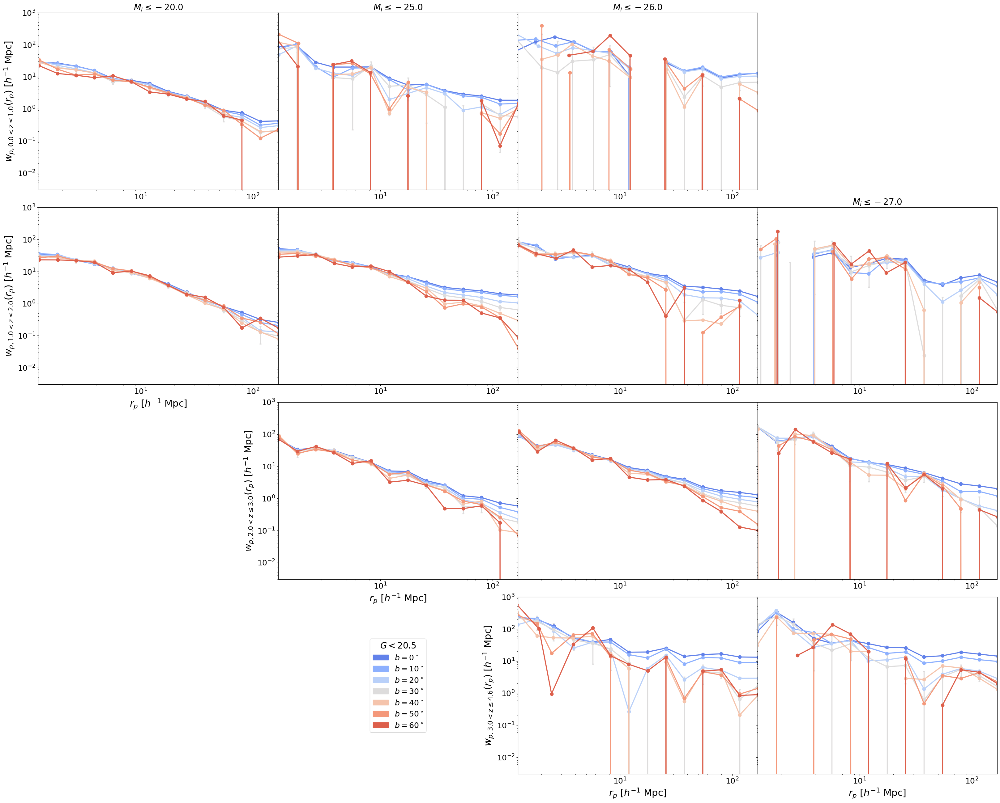

In [42]:
r = quaia.recenter(rbins_chi2_log) #_chi2)
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
a_zbin = {L: [] for L in L_bins}
ylims = [[[-1, 3], [-10, 14], [-40, 60], [-200, 400]], [[-1, 2.5], [-1, 4], [-5, 7], [-30, 20]], [[np.nan, np.nan], [-2, 4], [-2, 6], [-8, 10]], 
         [[np.nan, np.nan], [np.nan, np.nan], [-20, 25], [-30, 40]]]

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc

for j in z_array:
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q_b[L_bins[i]][j]>N_q_b[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q_b[L_bins[i]][j]/1000)>1):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            if j==0 or ((j == 1) and  (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if scale == 'log':
                ax1.set_xscale('log')
            ax1.set_xlim(r[0], r[-1])
            ax1.set_ylim(3e-3,1e3)
            
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
            ax1.set_xscale('log')
            ax1.set_yscale('log')
                
            for k in range(len(masks)):
                                        
                wp_zbin_i = np.load('../results/wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b_array[k]))
                rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b_array[k]))
                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b_array[k])))
          
                if b_array[k] == 30:
                    
                    sigma = np.sqrt(np.diag(np.load('../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                        G_hi, rmin_log, rmax_log, nbins_log, pimax, z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo, b_array[k]))))
    
                    wp_chi2[L_bins[i]].append(wp_zbin_i)
                    rpavg_chi2[L_bins[i]].append(rpavg_zbin_i)
                    a_zbin[L_bins[i]].append(a)
    
                    # matter correlation function   
                    s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
                    s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))
    
                    xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
                    wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
                    wp_matter_chi2[L_bins[i]].append(wp_matter_zbin_i)   
                
                else: 
                    sigma = 0
    
                # plot!
    
                # if ((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3):
                        
                ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5, capsize = 2.5,
                         linewidth = 2.5, color = cmap_masks[k], yerr = sigma, linestyle = '-')

            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticklabels([])
        else:

            ax2 = fig.add_subplot(gs[j*4+i])
            ax2.set_axis_off()

                
custom_lines = [mpatches.Patch(color=cmap_masks[i]) for i in range(len(masks))]
first_legend = ax2.legend(custom_lines, [r'$b={:.0f}^\circ$'.format(b) for b in b_array], loc = 'center', title = r'$G<{}$'.format(G_hi), title_fontsize = 20)
fig.add_artist(first_legend)

plt.show()

### Test $\pi_\mathrm{max}$

<>:22: SyntaxWarning: invalid escape sequence '\l'
<>:64: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\l'
<>:64: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_13225/113886321.py:22: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_13225/113886321.py:64: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,


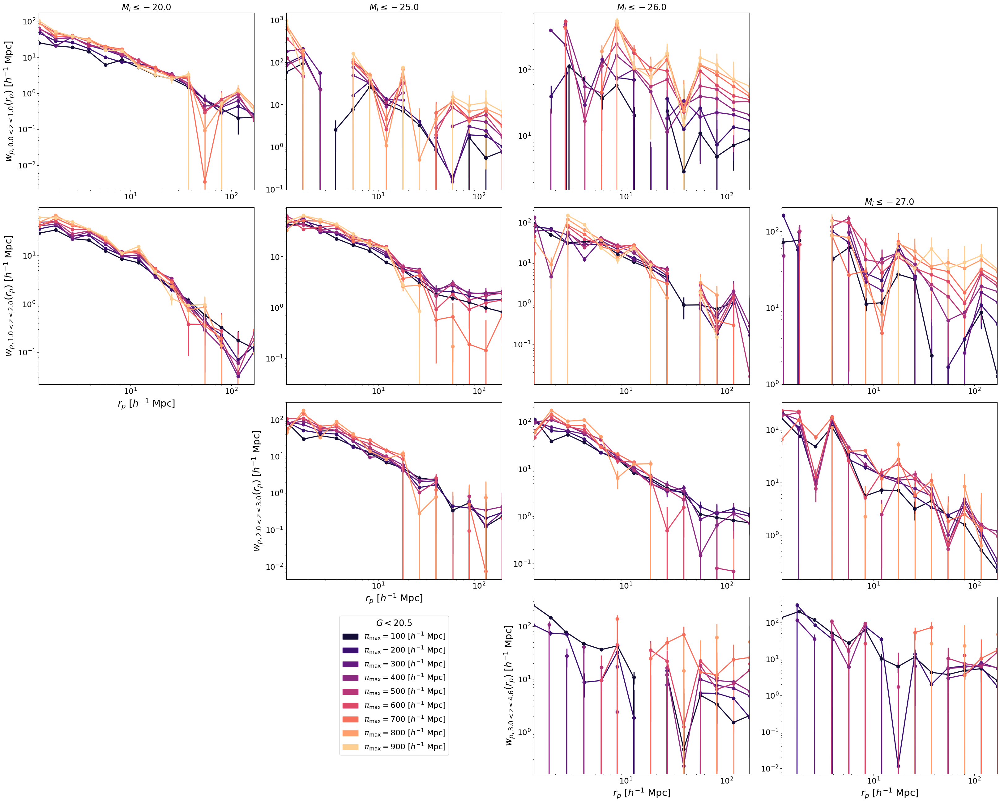

In [68]:
r = quaia.recenter(rbins_chi2_log) #_chi2)
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
a_zbin = {L: [] for L in L_bins}
ylims = [[[-1, 3], [-10, 14], [-40, 60], [-200, 400]], [[-1, 2.5], [-1, 4], [-5, 7], [-30, 20]], [[np.nan, np.nan], [-2, 4], [-2, 6], [-8, 10]], 
         [[np.nan, np.nan], [np.nan, np.nan], [-20, 25], [-30, 40]]]

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)

H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc

for j in z_array:
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q_b[L_bins[i]][j]>N_q_b[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q_b[L_bins[i]][j]/1000)>1):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            # if j ==0:
            if j==0 or ((j == 1) and  (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            # if scale == 'log':
            ax1.set_xscale('log')
            ax1.set_yscale('log')
            ax1.set_xlim(r[0], r[-1])
 
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
                
            for k in range(len(pi_max)):
                                        
                wp_zbin_i = np.load('../results/wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin_log, rmax_log, nbins_log, pi_max[k], z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin_log, rmax_log, nbins_log, pi_max[k], z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                    G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
    
                try:
                    sigma = np.sqrt(np.diag(np.load('../results/cov_wp_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                        G_hi, rmin_log, rmax_log, nbins_log, pi_max[k], z_bins[j], z_bins[j+1], L_bins[i], N_log, cosmo, b))))
    
                except Exception as e:
                    # print(e)
                    sigma=0
    
                wp_chi2[L_bins[i]].append(wp_zbin_i)
                rpavg_chi2[L_bins[i]].append(rpavg_zbin_i)
                a_zbin[L_bins[i]].append(a)
    
                # matter correlation function   
                s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
                s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))
    
                xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
                wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
                wp_matter_chi2[L_bins[i]].append(wp_matter_zbin_i)   
    
                # if ((i<3) and (N_q_b[L_bins[i]][j]>N_q_b[L_bins[i+1]][j])) or (i==3):
                        
                ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,
                         linewidth = 2.5, color = cmap_pimax[k], yerr = sigma, linestyle = '-')

        else:

            ax2 = fig.add_subplot(gs[j*4+i])
            ax2.set_axis_off()
                
custom_lines = [mpatches.Patch(color=cmap_pimax[i]) for i in range(len(pi_max))]
first_legend = ax2.legend(custom_lines, [r'$\pi_\mathrm{{max}}={}$ $[h^{{-1}}$ Mpc]'.format(pi) for pi in pi_max], loc = 'center', title = r'$G<{}$'.format(G_hi), title_fontsize = 20)
fig.add_artist(first_legend)

plt.show()

In [49]:
# Create the bins array
rmin = 0.1
rmax = 25.0
nbins = 10 #14
thetabins = np.logspace(np.log10(rmin), np.log10(rmax), nbins+1) #(np.log10(0.15), np.log10(35), 15)

In [67]:
cmap_theta = sns.color_palette("cubehelix", n_colors = len(L_bins))
cmap_theta

[(0.08605633600581403, 0.23824692404212, 0.30561236308077167),
 (0.32927729263408284, 0.4762845556584382, 0.1837155549758328),
 (0.8146245329198283, 0.49548316572322215, 0.5752525936416857),
 (0.7587183008012618, 0.7922069335474338, 0.9543861221913403)]

<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:33: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2061/3410779528.py:13: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_2061/3410779528.py:33: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, marker = 'd', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,# capsize = 2.5,


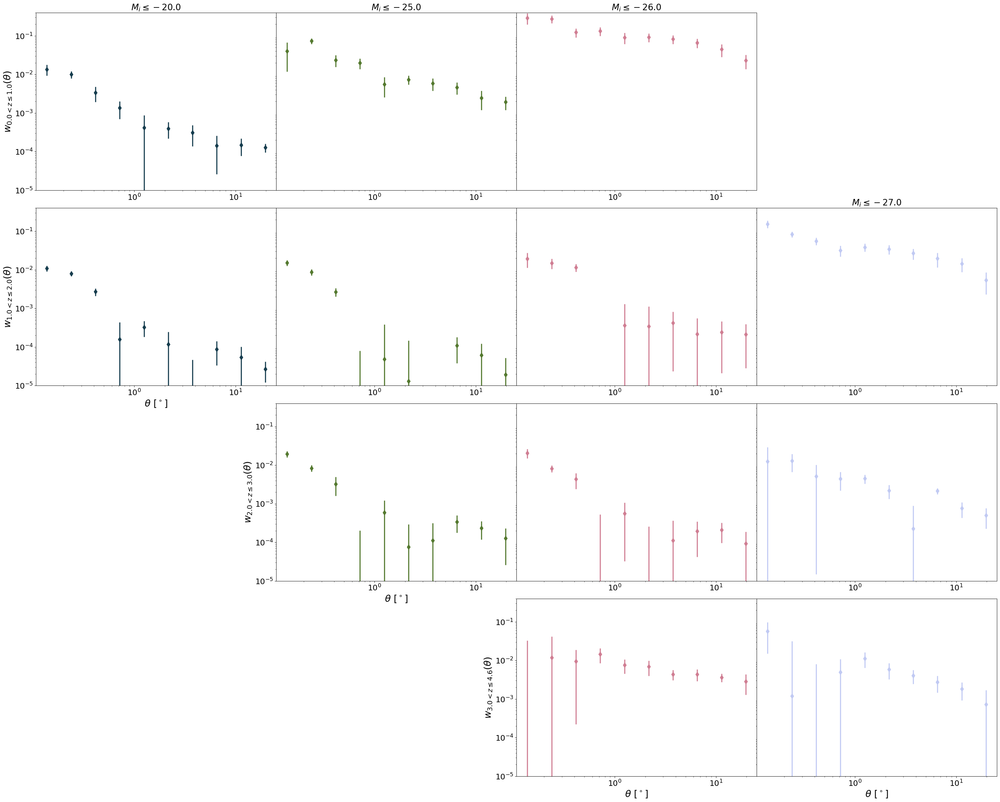

In [263]:
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
k = 3
for j in z_array:
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            if (j ==0) or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xscale('log')
            ax1.set_yscale('log')
            ax1.set_ylim(1e-5, 4e-1)
            
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
                            
            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))            
            # try:
            sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], 14, cosmo, mask))))
            # except:
            #     sigma = 0
            # plot!
                        
            ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, marker = 'd', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,# capsize = 2.5,
                     linewidth = 2.5, color = cmap_theta[i], yerr = sigma, linestyle = 'none')

plt.show()

<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:30: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2061/948737825.py:14: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_2061/948737825.py:30: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, marker = 'd', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,# capsize = 2.5,


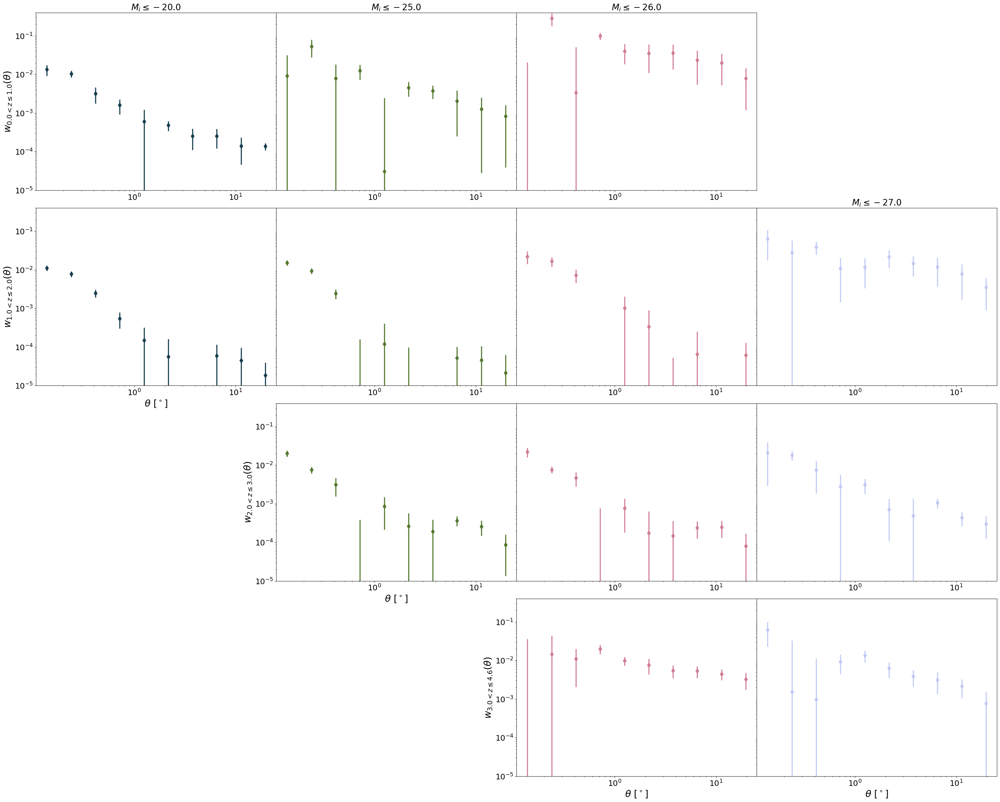

In [264]:
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
k = 3
b=30
for j in z_array:
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            if (j ==0) or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xscale('log')
            ax1.set_yscale('log')
            ax1.set_ylim(1e-5, 4e-1)
            
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
                            
            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))            
            sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], 14, cosmo, b))))
                        
            ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, marker = 'd', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,# capsize = 2.5,
                     linewidth = 2.5, color = cmap_theta[i], yerr = sigma, linestyle = 'none')

plt.show()

In [45]:
delta_xlim = np.diff(np.log10(thetabins))[0]/2
delta_xlim/2, thetabins, 10**(np.log10(thetabins) - 2*delta_xlim)

(0.059948500216800926,
 array([ 0.1       ,  0.17369767,  0.30170882,  0.52406119,  0.9102821 ,
         1.58113883,  2.74640136,  4.77043526,  8.28613504, 14.39282377,
        25.        ]),
 array([ 0.0575713 ,  0.1       ,  0.17369767,  0.30170882,  0.52406119,
         0.9102821 ,  1.58113883,  2.74640136,  4.77043526,  8.28613504,
        14.39282377]))

<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:21: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_2061/2490765707.py:19: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
/tmp/ipykernel_2061/2490765707.py:21: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


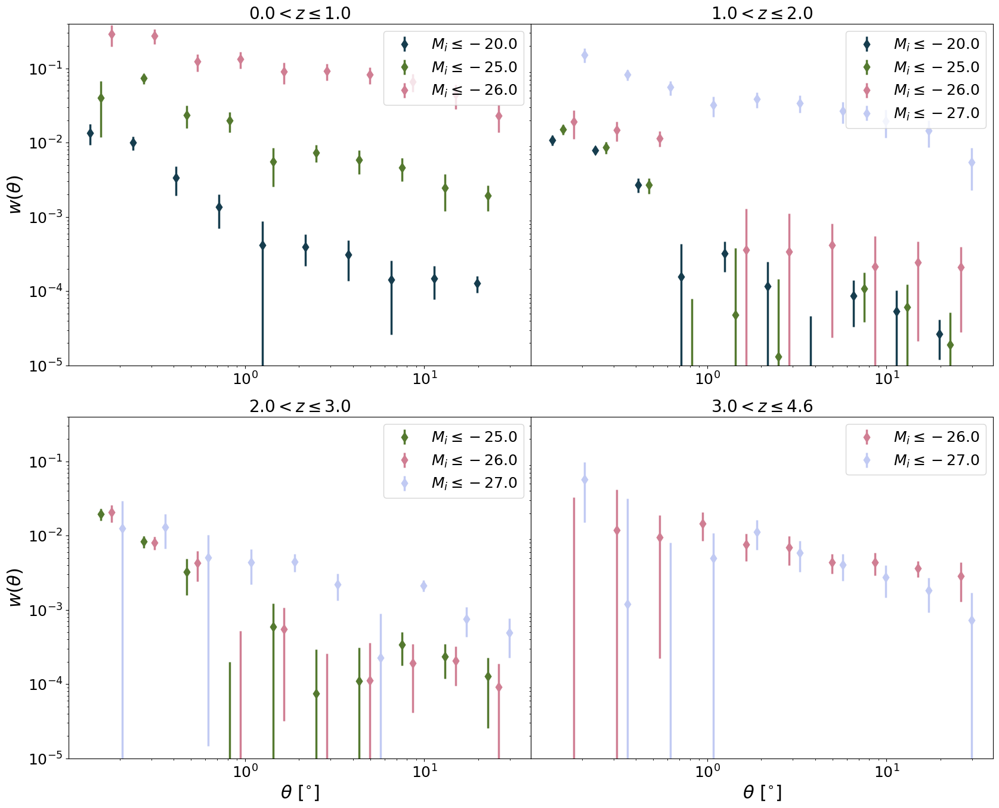

In [268]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])

    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], 14, cosmo, mask))))
            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))            
            
            ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'd', color = cmap_theta[i],
                        yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5

            ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(1e-5, 4e-1)
            
            if j%2==0:
                ax1.set_ylabel(r"$w(\theta)$")
            else:
                ax1.set_yticks([])
            if j > 1:
                ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
            ax1.legend(loc = 'upper right')

# plt.savefig('../figures/threshold_wtheta_log.pdf', bbox_inches = 'tight')

plt.show()

<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:21: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_2061/2751889855.py:19: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
/tmp/ipykernel_2061/2751889855.py:21: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


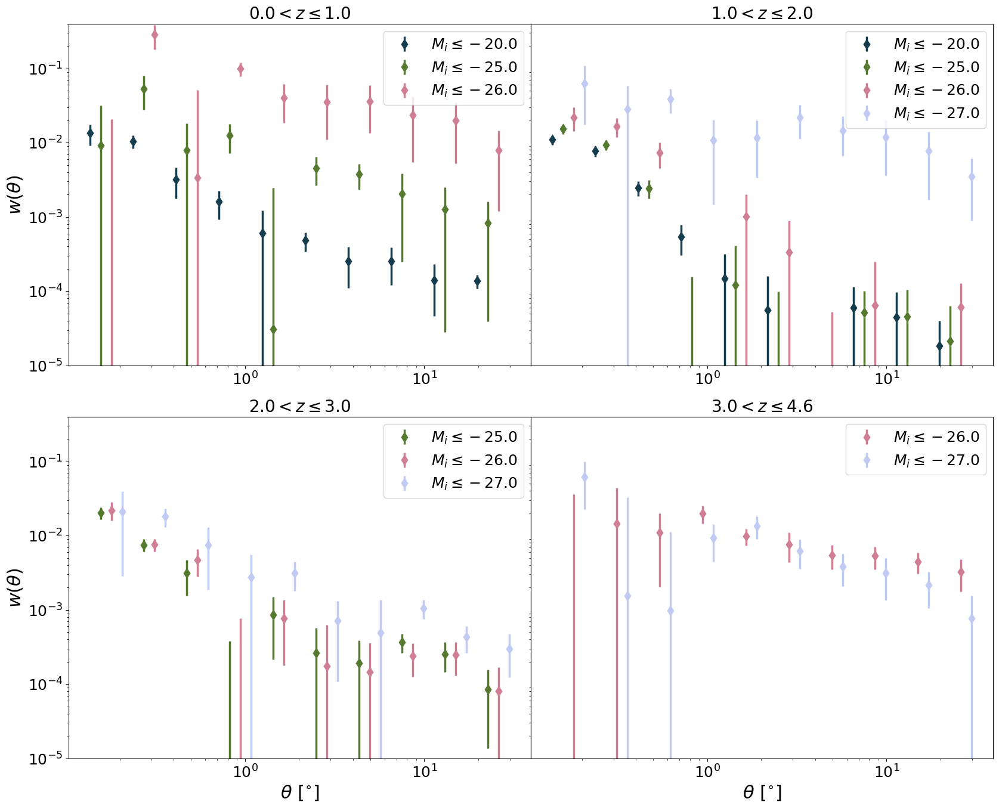

In [267]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])

    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], 14, cosmo, b))))
            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))            
            
            ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'd', color = cmap_theta[i],
                        yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5

            ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(1e-5, 4e-1)
            
            if j%2==0:
                ax1.set_ylabel(r"$w(\theta)$")
            else:
                ax1.set_yticks([])
            if j > 1:
                ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
            ax1.legend()

plt.show()

<>:20: SyntaxWarning: invalid escape sequence '\l'
<>:22: SyntaxWarning: invalid escape sequence '\l'
<>:20: SyntaxWarning: invalid escape sequence '\l'
<>:22: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_118412/626603257.py:20: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
/tmp/ipykernel_118412/626603257.py:22: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


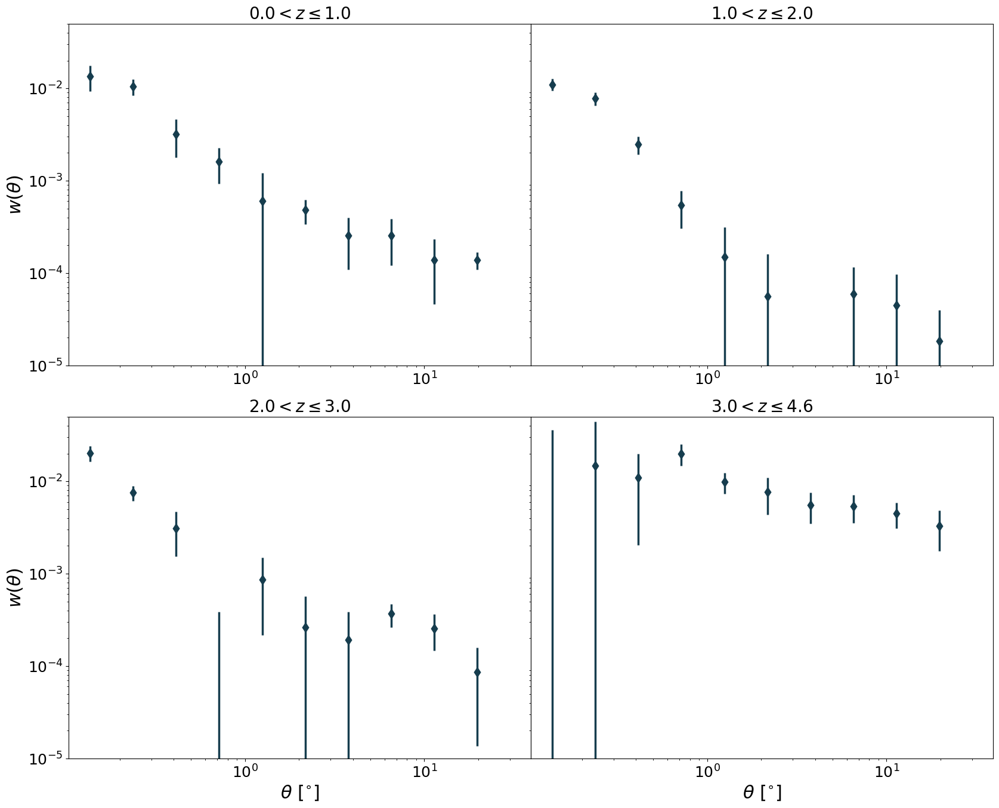

In [36]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
i = 0
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])

    # for i in range(len(L_bins)):

    # if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

    sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax-20.0_N{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], 14, cosmo, b))))
    wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax-20.0_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], cosmo, b))
    a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax-20.0_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], cosmo, b)))            
    
    ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'd', color = cmap_theta[i],
                yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5

    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
    ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
    ax1.set_yscale('log')
    ax1.set_xscale('log')
    ax1.set_ylim(1e-5, 5e-2)
    
    if j%2==0:
        ax1.set_ylabel(r"$w(\theta)$")
    else:
        ax1.set_yticks([])
    if j > 1:
        ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
    # ax1.legend()

plt.show()

<>:15: SyntaxWarning: invalid escape sequence '\l'
<>:15: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_25392/634771811.py:15: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma, markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5


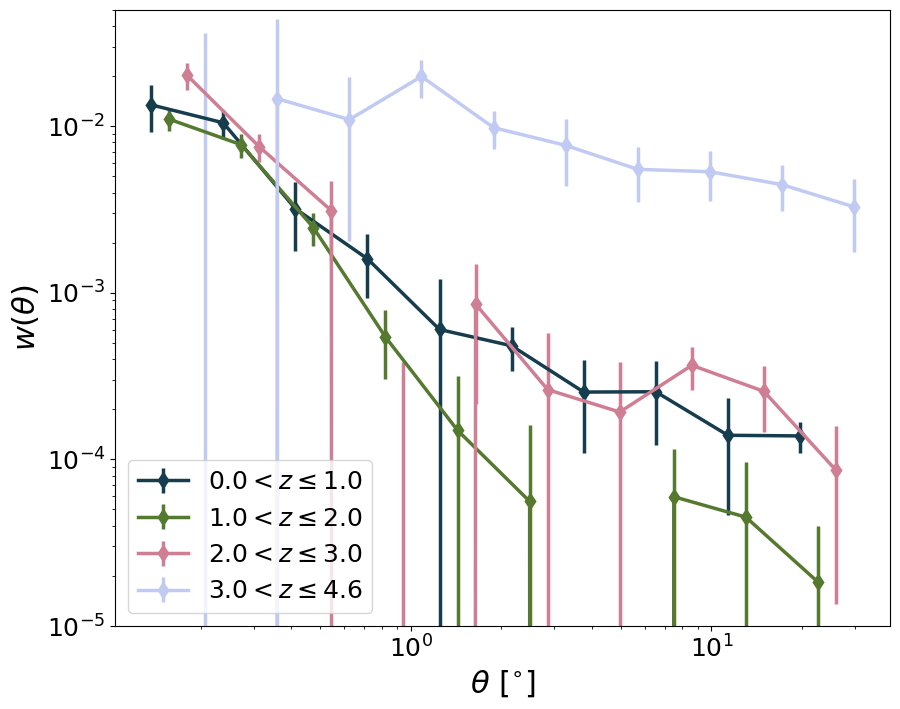

In [80]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1, wspace = 0, hspace = 0)

# remove bottom panel and just print bq somewhere
# plot!
i = 0
ax1 = fig.add_subplot(gs[0])
for j in range(len(z_array)):

    sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax-20.0_N{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], 14, cosmo, b))))
    wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax-20.0_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], cosmo, b))
    a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax-20.0_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], cosmo, b)))            
    
    ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + j*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'd', color = cmap_theta[j],
                yerr = sigma, markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5

# ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_ylim(1e-5, 5e-2)

# if j%2==0:
ax1.set_ylabel(r"$w(\theta)$")
# else:
    # ax1.set_yticks([])
# if j > 1:
ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
ax1.legend()

plt.show()

## Test the mask

<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:66: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:66: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_10905/2045995896.py:21: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_10905/2045995896.py:66: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(10**(np.log10(quaia.recenter(thetabins))), wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,


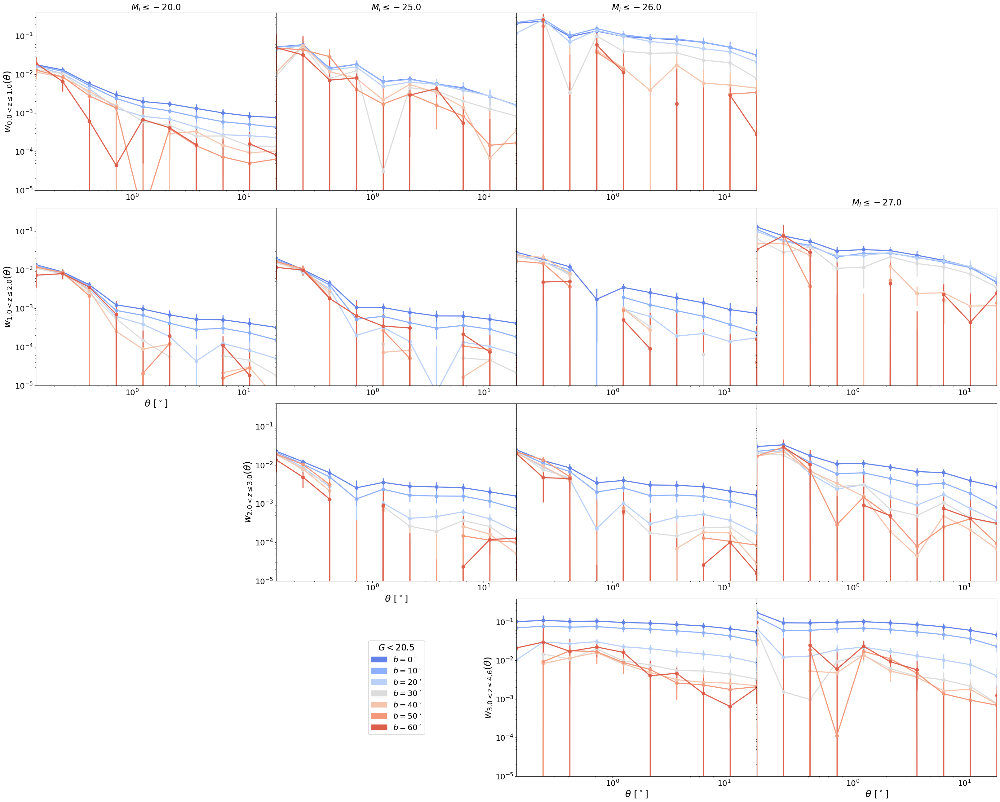

In [48]:
r = quaia.recenter(thetabins) #_chi2)
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
a_zbin = {L: [] for L in L_bins}
ylims = [[[-1, 3], [-10, 14], [-40, 60], [-200, 400]], [[-1, 2.5], [-1, 4], [-5, 7], [-30, 20]], [[np.nan, np.nan], [-2, 4], [-2, 6], [-8, 10]], 
         [[np.nan, np.nan], [np.nan, np.nan], [-20, 25], [-30, 40]]]

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc

for j in z_array:
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q_b[L_bins[i]][j]>N_q_b[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q_b[L_bins[i]][j]/1000)>1):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            if j==0 or ((j == 1) and  (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if scale == 'log':
                ax1.set_xscale('log')
            ax1.set_xlim(r[0], r[-1])
            ax1.set_ylim(1e-5, 4e-1)
            ax1.set_xscale('log')
            ax1.set_yscale('log')
            
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
                
            for k in range(len(b_array)):
                                        
                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b_array[k]))
                # rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                #     G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b_array[k]))
                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b_array[k])))
          
                # if b_array[k] == 30:
                    
                sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{:.1f}_rmax{:.1f}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], 14, cosmo, b_array[k]))))

                wp_chi2[L_bins[i]].append(wp_zbin_i)
                rpavg_chi2[L_bins[i]].append(rpavg_zbin_i)
                a_zbin[L_bins[i]].append(a)

                # matter correlation function   
                s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
                s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))

                xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
                wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
                wp_matter_chi2[L_bins[i]].append(wp_matter_zbin_i)   
                
                # else: 
                #     sigma = 0

            # plot!
                    
                ax1.errorbar(10**(np.log10(quaia.recenter(thetabins))), wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,
                         linewidth = 2.5, color = cmap_masks[k], yerr = sigma, linestyle = '-')

        else:

            ax2 = fig.add_subplot(gs[j*4+i])
            ax2.set_axis_off()

                
custom_lines = [mpatches.Patch(color=cmap_masks[i]) for i in range(len(b_array))]
first_legend = ax2.legend(custom_lines, [r'$b={}^\circ$'.format(b) for b in b_array], loc = 'center', title = r'$G<{}$'.format(G_hi), title_fontsize = 20)
fig.add_artist(first_legend)

plt.show()

In [46]:
# Create the bins array
rmin = 0.001
rmax = 5.0
nbins = 27 #14
thetabins = np.logspace(np.log10(rmin), np.log10(rmax), nbins+1) #(np.log10(0.15), np.log10(35), 15)

In [47]:
cmap_blue = sns.color_palette("Blues_r", n_colors = len(L_bins))
cmap_blue

[(0.09019607843137256, 0.39294117647058824, 0.6705882352941177),
 (0.2909803921568628, 0.5945098039215686, 0.7890196078431373),
 (0.5796078431372549, 0.7701960784313725, 0.8737254901960784),
 (0.8141176470588235, 0.883921568627451, 0.9498039215686275)]

<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:36: SyntaxWarning: invalid escape sequence '\m'
<>:40: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:36: SyntaxWarning: invalid escape sequence '\m'
<>:40: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_112179/2007792647.py:13: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_112179/2007792647.py:36: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, marker = 'd', label = '${:.0f}^\mathrm{{th}}$ percentile, no MCs'.format(mask*100), markeredgewidth = 2.5,# capsize = 2.5,
/tmp/ipykernel_112179/2007792647.py:40: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, marker = 'D', label = '${:.0f}^\mathrm{{th}}$ percentile, with MCs'.format(0*100), markeredgewidth = 2.5,# capsize = 2.5,


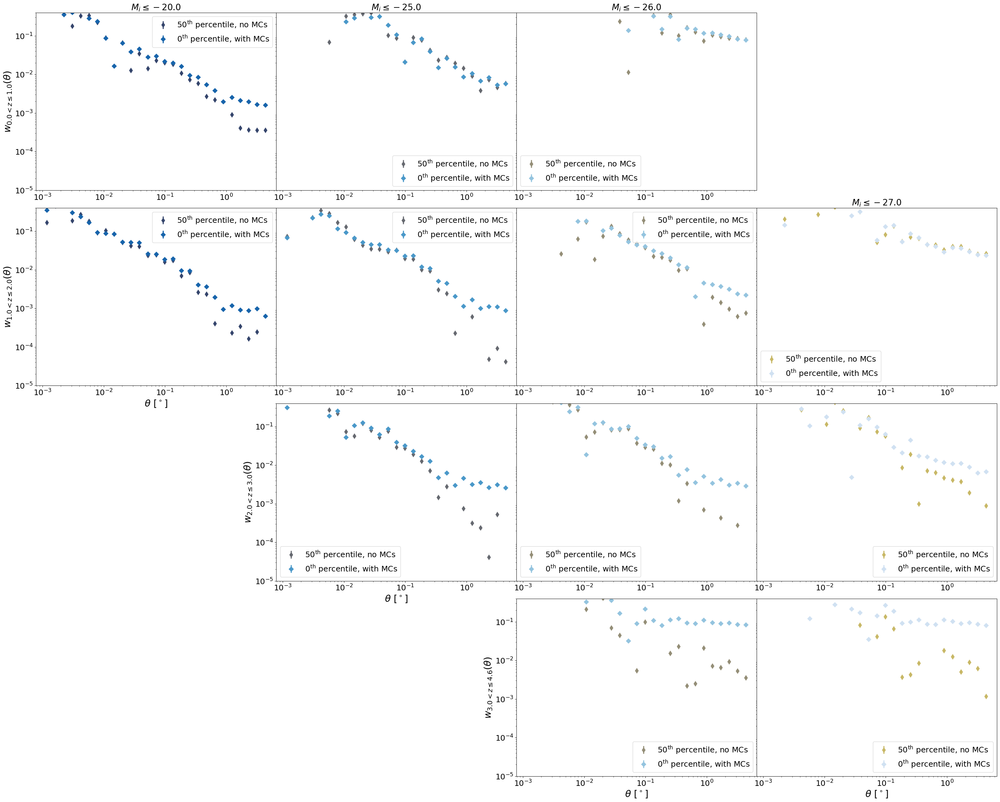

In [59]:
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
k = 3
for j in z_array:
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            if (j ==0) or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            # if scale == 'log':
            ax1.set_xscale('log')
            ax1.set_yscale('log')
            # ax1.set_xlim(r[0], r[-1])
            ax1.set_ylim(1e-5, 4e-1)
            
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
                            
            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            # rpavg_zbin_i = np.load('../results/rpavg_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))            
            try:
                sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], 14, cosmo, mask))))
            except:
                sigma = 0
            # plot!
                        
            ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, marker = 'd', label = '${:.0f}^\mathrm{{th}}$ percentile, no MCs'.format(mask*100), markeredgewidth = 2.5,# capsize = 2.5,
                     linewidth = 2.5, color = cmap_theta[i], yerr = sigma, linestyle = 'none')

            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_mask{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, 0.0))
            ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, marker = 'D', label = '${:.0f}^\mathrm{{th}}$ percentile, with MCs'.format(0*100), markeredgewidth = 2.5,# capsize = 2.5,
                     linewidth = 2.5, color = cmap_blue[i], yerr = sigma, linestyle = 'none')
            ax1.legend()


plt.show()

In [48]:
delta_xlim = np.diff(np.log10(thetabins))[0]/2
delta_xlim/2, thetabins, 10**(np.log10(thetabins) - 2*delta_xlim)

(0.03424972226237055,
 array([1.00000000e-03, 1.37087826e-03, 1.87930720e-03, 2.57630139e-03,
        3.53179556e-03, 4.84166175e-03, 6.63732883e-03, 9.09896980e-03,
        1.24735799e-02, 1.70997595e-02, 2.34416885e-02, 3.21357011e-02,
        4.40541340e-02, 6.03928546e-02, 8.27912513e-02, 1.13496727e-01,
        1.55590195e-01, 2.13295216e-01, 2.92401774e-01, 4.00847235e-01,
        5.49512759e-01, 7.53315095e-01, 1.03270329e+00, 1.41571048e+00,
        1.94076672e+00, 2.66055491e+00, 3.64729688e+00, 5.00000000e+00]),
 array([7.29459376e-04, 1.00000000e-03, 1.37087826e-03, 1.87930720e-03,
        2.57630139e-03, 3.53179556e-03, 4.84166175e-03, 6.63732883e-03,
        9.09896980e-03, 1.24735799e-02, 1.70997595e-02, 2.34416885e-02,
        3.21357011e-02, 4.40541340e-02, 6.03928546e-02, 8.27912513e-02,
        1.13496727e-01, 1.55590195e-01, 2.13295216e-01, 2.92401774e-01,
        4.00847235e-01, 5.49512759e-01, 7.53315095e-01, 1.03270329e+00,
        1.41571048e+00, 1.94076672e+00, 

In [65]:
cmap_grey = sns.color_palette("Greys_r", n_colors = len(L_bins))
cmap_grey

[(0.25098039215686274, 0.25098039215686274, 0.25098039215686274),
 (0.47843137254901963, 0.47843137254901963, 0.47843137254901963),
 (0.7105882352941177, 0.7105882352941177, 0.7105882352941177),
 (0.8870588235294118, 0.8870588235294118, 0.8870588235294118)]

<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:25: SyntaxWarning: invalid escape sequence '\l'
<>:40: SyntaxWarning: invalid escape sequence '\l'
<>:45: SyntaxWarning: invalid escape sequence '\m'
<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:25: SyntaxWarning: invalid escape sequence '\l'
<>:40: SyntaxWarning: invalid escape sequence '\l'
<>:45: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_112179/1803218170.py:19: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
/tmp/ipykernel_112179/1803218170.py:25: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
/tmp/ipykernel_112179/1803218170.py:40: SyntaxWarning: invalid escape sequence '\l'
  second_legend = ax1.legend(custom_lines, ['$M_i\leq{}$'.format(L) for L in L_bins])
/tmp/ipykernel_112179/1803218170.py:45: SyntaxWarning: invalid esca

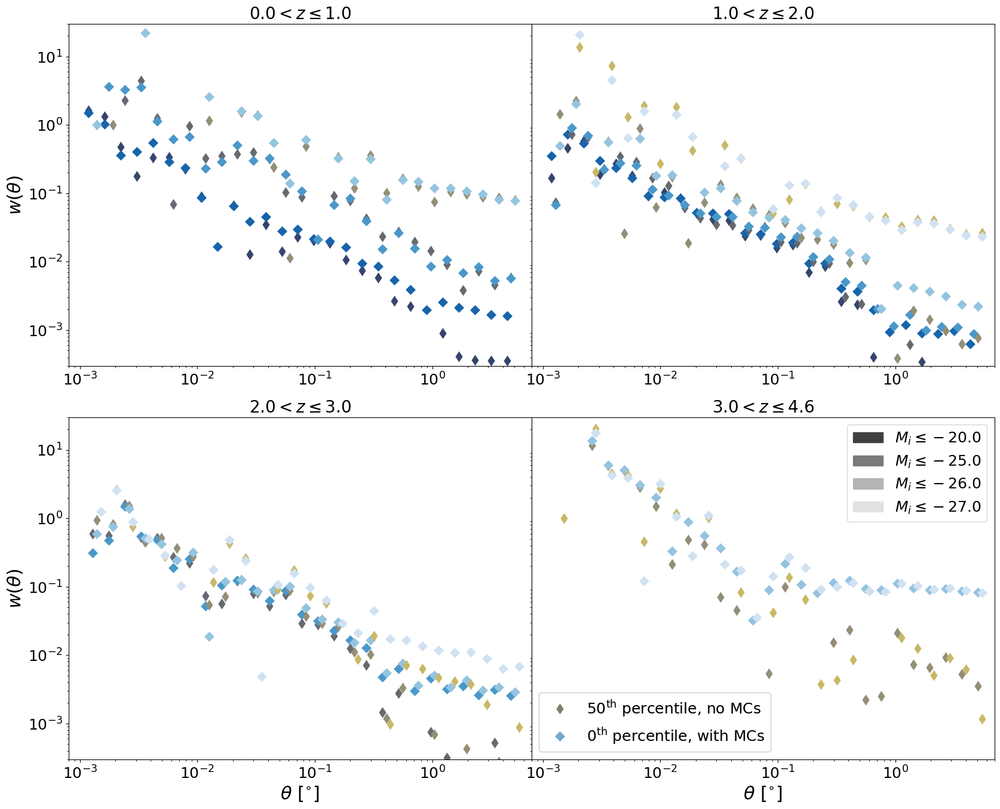

In [69]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])

    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            # sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], 14, cosmo, mask))))
            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))            
            
            ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'd', color = cmap_theta[i],
                        yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
            
            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_mask{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, 0.0))
            ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'D', color = cmap_blue[i],
                        yerr = sigma, markeredgewidth = 2.5, linestyle = 'none')#, label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5

            ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xlim(8e-4, 7)
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(3e-4, 3e1)
            
            if j%2==0:
                ax1.set_ylabel(r"$w(\theta)$")
            else:
                ax1.set_yticks([])
            if j > 1:
                ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
            # ax1.legend()

custom_lines = [mpatches.Patch(color=cmap_grey[i]) for i in range(len(L_bins))]
second_legend = ax1.legend(custom_lines, ['$M_i\leq{}$'.format(L) for L in L_bins])
fig.add_artist(second_legend)

custom_lines = [Line2D([0], [0], color = np.mean(cmap_theta, axis = 0), linestyle = 'none', marker = 'd', linewidth = 2.5, markeredgewidth = 2.5),
                Line2D([0], [0], color = np.mean(cmap_blue, axis = 0), linestyle = 'none', marker = 'D',linewidth = 2.5, markeredgewidth = 2.5)]
second_legend = ax1.legend(custom_lines, [r'${:.0f}^\mathrm{{th}}$ percentile, no MCs'.format(mask*100), '${:.0f}^\mathrm{{th}}$ percentile, with MCs'.format(0*100)], loc = 'lower left')
fig.add_artist(second_legend)

plt.show()

<>:32: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_118412/1930406503.py:32: SyntaxWarning: invalid escape sequence '\l'
  yerr = 0, markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5


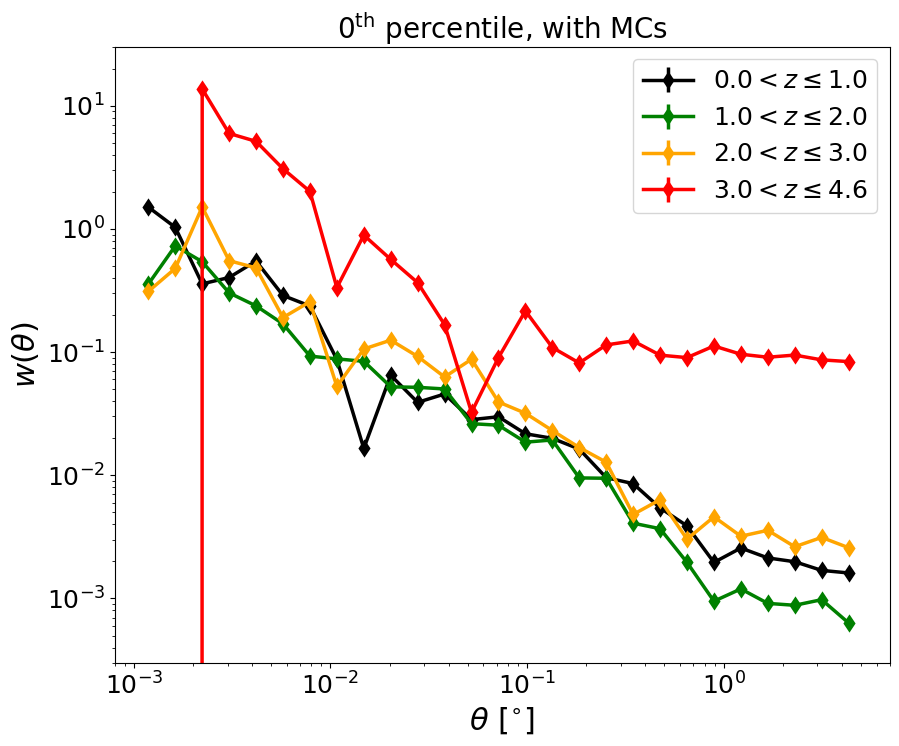

In [47]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1, wspace = 0, hspace = 0)
i = 0
# remove bottom panel and just print bq somewhere
# plot!

ax1 = fig.add_subplot(gs[0])
colors = ['black', 'green', 'orange', 'red']
for j in range(len(z_array)):

    # for i in range(len(L_bins)):

        # if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

    # wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_{}_mask{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], cosmo, 0.0))
    a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))            
    
    # ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'd', color = colors[j],
    #             yerr = sigma, markeredgewidth = 2.5, linestyle = ':', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), alpha = 0.5) #capsize = 2.5

# ax1.set_title(r'${:.0f}^\mathrm{{th}}$ percentile, no MCs'.format(mask*100))
# ax1.set_xlim(8e-4, 7)
# ax1.set_yscale('log')
# ax1.set_xscale('log')
# ax1.set_ylim(3e-4, 3e1)
# ax1 = fig.add_subplot(gs[0])

# for j in range(len(z_array)):

    wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_mask{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, 0.0))
    ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'd', color = colors[j],
                yerr = 0, markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5

ax1.set_title(r'${:.0f}^\mathrm{{th}}$ percentile, with MCs'.format(0.0*100))
ax1.set_xlim(8e-4, 7)
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_ylim(3e-4, 3e1)

# if j%2==0:
ax1.set_ylabel(r"$w(\theta)$")
# else:
#     ax1.set_yticks([])
if j > 1:
    ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
ax1.legend()

# custom_lines = [mpatches.Patch(color=cmap_grey[i]) for i in range(len(L_bins))]
# second_legend = ax1.legend(custom_lines, ['$M_i\leq{}$'.format(L) for L in L_bins])
# fig.add_artist(second_legend)

# custom_lines = [Line2D([0], [0], color = np.mean(cmap_theta, axis = 0), linestyle = 'none', marker = 'd', linewidth = 2.5, markeredgewidth = 2.5),
#                 Line2D([0], [0], color = np.mean(cmap_blue, axis = 0), linestyle = 'none', marker = 'D',linewidth = 2.5, markeredgewidth = 2.5)]
# second_legend = ax1.legend(custom_lines, [r'${:.0f}^\mathrm{{th}}$ percentile, no MCs'.format(mask*100), '${:.0f}^\mathrm{{th}}$ percentile, with MCs'.format(0*100)], loc = 'lower left')
# fig.add_artist(second_legend)

plt.show()

<>:15: SyntaxWarning: invalid escape sequence '\l'
<>:15: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_32677/3086027205.py:15: SyntaxWarning: invalid escape sequence '\l'
  yerr = 0, markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5


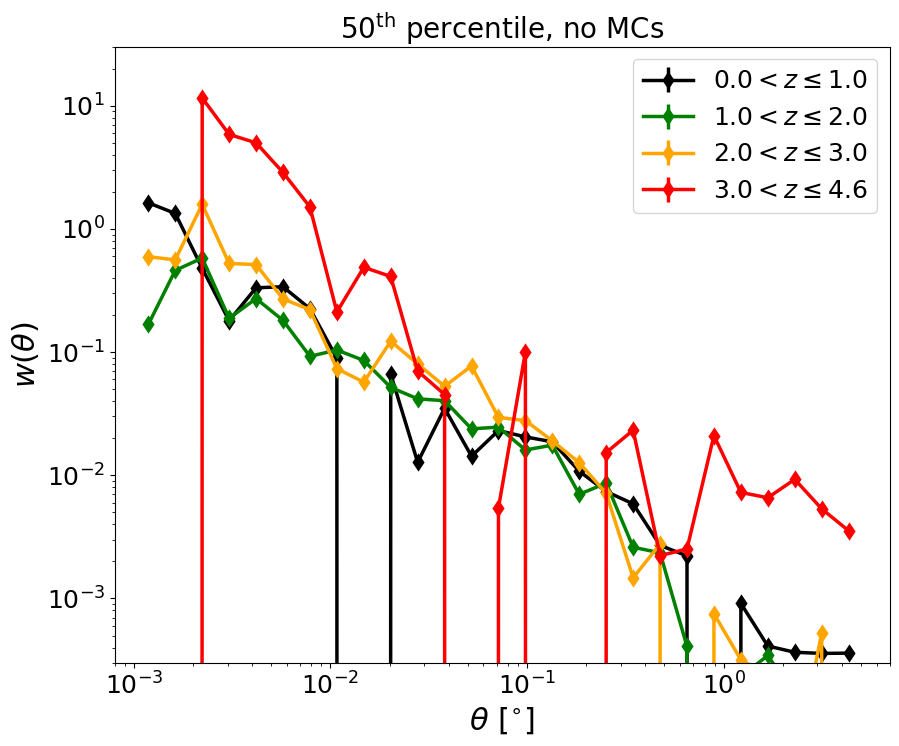

In [48]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1, wspace = 0, hspace = 0)
i = 0
# remove bottom panel and just print bq somewhere
# plot!

ax1 = fig.add_subplot(gs[0])
colors = ['black', 'green', 'orange', 'red']
for j in range(len(z_array)):

    wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask))
    a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))            
    
    ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'd', color = colors[j],
                yerr = 0, markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5

    # wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_{}_MC_mask{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], cosmo, mask))
    # ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'D', color = colors[j],
    #             yerr = sigma, markeredgewidth = 2.5, linestyle = ':', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5

ax1.set_title(r'${:.0f}^\mathrm{{th}}$ percentile, no MCs'.format(mask*100))
ax1.set_xlim(8e-4, 7)
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_ylim(3e-4, 3e1)
ax1.legend()
ax1.set_ylabel(r"$w(\theta)$")
if j > 1:
    ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 

plt.show()

<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:21: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_118412/2552624161.py:21: SyntaxWarning: invalid escape sequence '\l'
  yerr = 0, markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


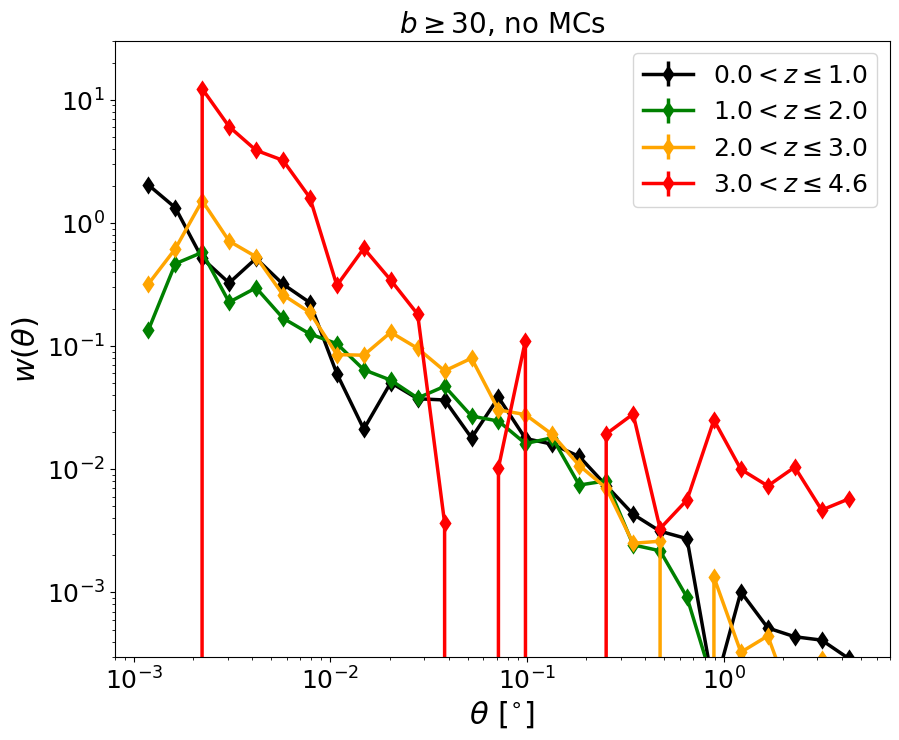

In [31]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1, wspace = 0, hspace = 0)
i = 0
b=30
# remove bottom panel and just print bq somewhere
# plot!

ax1 = fig.add_subplot(gs[0])
colors = ['black', 'green', 'orange', 'red']
for j in range(len(z_array)):

    wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], cosmo, b))

    try:
        a = float(np.load('../results/a_G{}_zmin{}zmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], cosmo, b)))    
    except Exception as e:
        a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, mask)))    
        print(e)
    
    ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'd', color = colors[j],
                yerr = 0, markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) 

ax1.set_title(r'$b\geq30$, no MCs'.format(mask*100))
ax1.set_xlim(8e-4, 7)
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_ylim(3e-4, 3e1)
ax1.legend()
ax1.set_ylabel(r"$w(\theta)$")
if j > 1:
    ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 

plt.show()

In [69]:
# Create the bins array
rmin = 0.001
rmax = 10.0
nbins = 20
thetabins = np.logspace(np.log10(rmin), np.log10(rmax), nbins+1)
np.log10(thetabins)

array([-3. , -2.8, -2.6, -2.4, -2.2, -2. , -1.8, -1.6, -1.4, -1.2, -1. ,
       -0.8, -0.6, -0.4, -0.2,  0. ,  0.2,  0.4,  0.6,  0.8,  1. ])

In [75]:
delta_xlim = np.diff(np.log10(thetabins))[0]/2
delta_xlim/2, thetabins, 10**(np.log10(thetabins) - 2*delta_xlim)

(0.050000000000000044,
 array([1.00000000e-03, 1.58489319e-03, 2.51188643e-03, 3.98107171e-03,
        6.30957344e-03, 1.00000000e-02, 1.58489319e-02, 2.51188643e-02,
        3.98107171e-02, 6.30957344e-02, 1.00000000e-01, 1.58489319e-01,
        2.51188643e-01, 3.98107171e-01, 6.30957344e-01, 1.00000000e+00,
        1.58489319e+00, 2.51188643e+00, 3.98107171e+00, 6.30957344e+00,
        1.00000000e+01]),
 array([6.30957344e-04, 1.00000000e-03, 1.58489319e-03, 2.51188643e-03,
        3.98107171e-03, 6.30957344e-03, 1.00000000e-02, 1.58489319e-02,
        2.51188643e-02, 3.98107171e-02, 6.30957344e-02, 1.00000000e-01,
        1.58489319e-01, 2.51188643e-01, 3.98107171e-01, 6.30957344e-01,
        1.00000000e+00, 1.58489319e+00, 2.51188643e+00, 3.98107171e+00,
        6.30957344e+00]))

<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_13225/3128449540.py:13: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_13225/3128449540.py:32: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, marker = 'd', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,# capsize = 2.5,


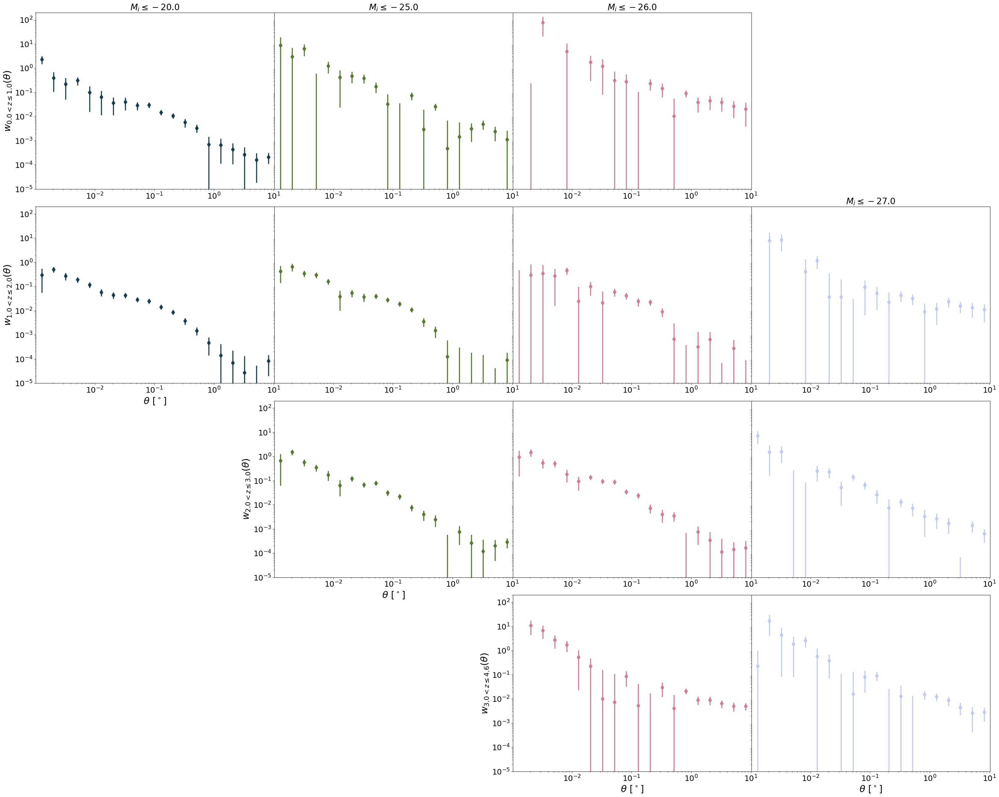

In [76]:
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
k = 3
for j in z_array:
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            if (j ==0) or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xscale('log')
            ax1.set_yscale('log')
            ax1.set_ylim(1e-5, 2e2)
            
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
            ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + delta_xlim))
                            
            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))            
            sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))))
                        
            ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, marker = 'd', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,# capsize = 2.5,
                     linewidth = 2.5, color = cmap_theta[i], yerr = sigma, linestyle = 'none')

plt.show()

<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:23: SyntaxWarning: invalid escape sequence '\l'
<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:23: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13225/3955234956.py:21: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
/tmp/ipykernel_13225/3955234956.py:23: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


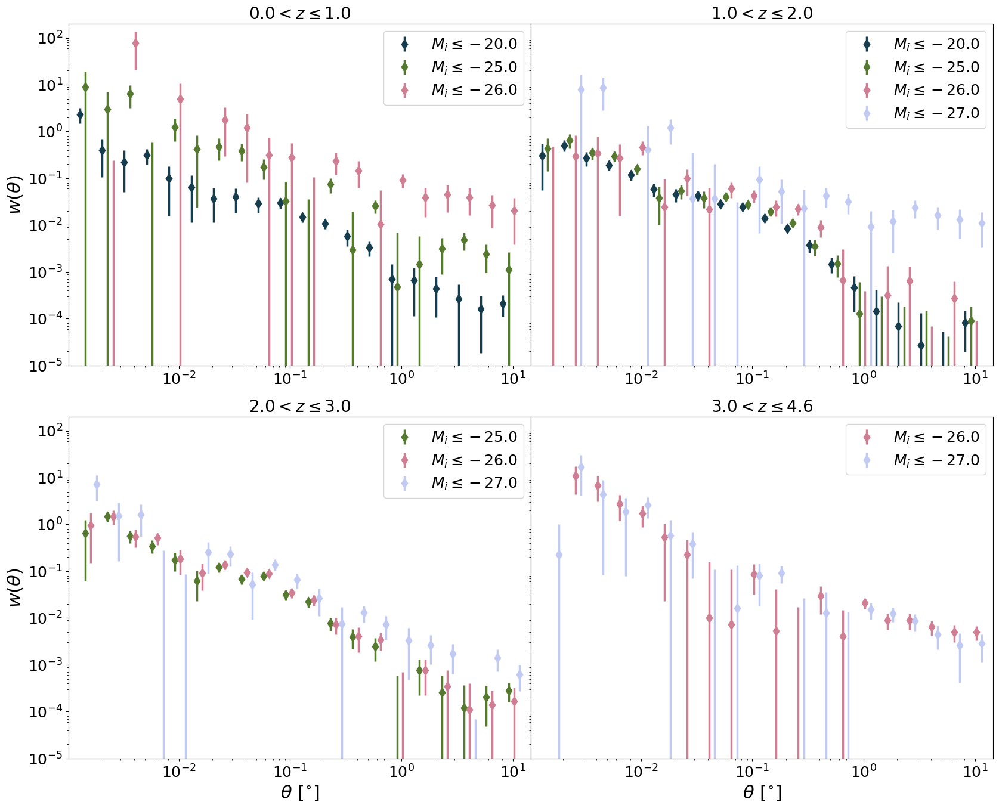

In [77]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])

    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))))
            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))            
            
            ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'd', color = cmap_theta[i],
                        yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5

            ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(1e-5, 2e2)
            
            if j%2==0:
                ax1.set_ylabel(r"$w(\theta)$")
            else:
                ax1.set_yticks([])
            if j > 1:
                ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
            ax1.legend(loc = 'upper right')

plt.show()

## Test the mask

<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:59: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:59: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_13225/3245613201.py:21: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_13225/3245613201.py:59: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(10**(np.log10(quaia.recenter(thetabins))), wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,


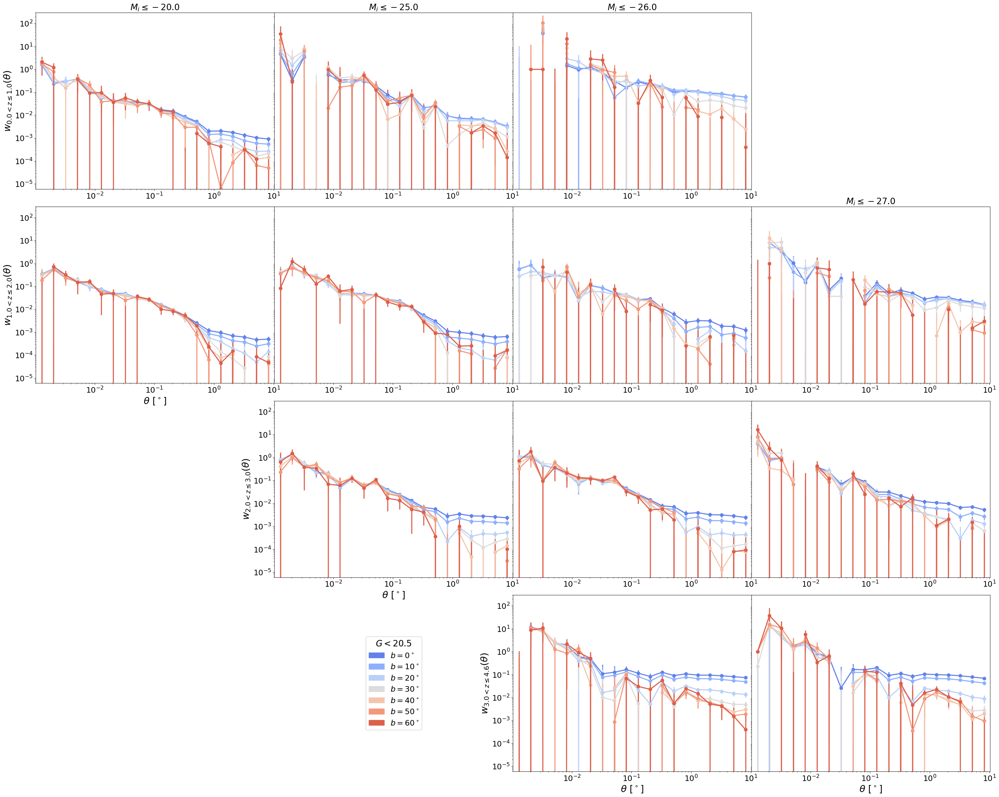

In [85]:
r = quaia.recenter(thetabins) #_chi2)
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
a_zbin = {L: [] for L in L_bins}
ylims = [[[-1, 3], [-10, 14], [-40, 60], [-200, 400]], [[-1, 2.5], [-1, 4], [-5, 7], [-30, 20]], [[np.nan, np.nan], [-2, 4], [-2, 6], [-8, 10]], 
         [[np.nan, np.nan], [np.nan, np.nan], [-20, 25], [-30, 40]]]

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc

for j in z_array:
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q_b[L_bins[i]][j]>N_q_b[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q_b[L_bins[i]][j]/1000)>1):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            if j==0 or ((j == 1) and  (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if scale == 'log':
                ax1.set_xscale('log')
            ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + delta_xlim))
            ax1.set_ylim(6e-6, 3e2)
            ax1.set_xscale('log')
            ax1.set_yscale('log')
            
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
                
            for k in range(len(b_array)):
                                        
                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b_array[k]))
                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b_array[k])))
                    
                sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b_array[k]))))

                wp_chi2[L_bins[i]].append(wp_zbin_i)
                rpavg_chi2[L_bins[i]].append(rpavg_zbin_i)
                a_zbin[L_bins[i]].append(a)

                # matter correlation function   
                s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
                s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))

                xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
                wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
                wp_matter_chi2[L_bins[i]].append(wp_matter_zbin_i)   

            # plot!
                    
                ax1.errorbar(10**(np.log10(quaia.recenter(thetabins))), wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,
                         linewidth = 2.5, color = cmap_masks[k], yerr = sigma, linestyle = '-')

        else:

            ax2 = fig.add_subplot(gs[j*4+i])
            ax2.set_axis_off()
                
custom_lines = [mpatches.Patch(color=cmap_masks[i]) for i in range(len(b_array))]
first_legend = ax2.legend(custom_lines, [r'$b={}^\circ$'.format(b) for b in b_array], loc = 'center', title = r'$G<{}$'.format(G_hi), title_fontsize = 20)
fig.add_artist(first_legend)

plt.show()

In [40]:
# Create the bins array
rmin = 0.001
rmax = 10.0
nbins = 30 #20 #30 #20
thetabins = np.logspace(np.log10(rmin), np.log10(rmax), nbins+1)
np.log10(thetabins), quaia.recenter(np.log10(thetabins)), np.diff(np.log10(thetabins))

(array([-3.        , -2.86666667, -2.73333333, -2.6       , -2.46666667,
        -2.33333333, -2.2       , -2.06666667, -1.93333333, -1.8       ,
        -1.66666667, -1.53333333, -1.4       , -1.26666667, -1.13333333,
        -1.        , -0.86666667, -0.73333333, -0.6       , -0.46666667,
        -0.33333333, -0.2       , -0.06666667,  0.06666667,  0.2       ,
         0.33333333,  0.46666667,  0.6       ,  0.73333333,  0.86666667,
         1.        ]),
 array([-2.93333333e+00, -2.80000000e+00, -2.66666667e+00, -2.53333333e+00,
        -2.40000000e+00, -2.26666667e+00, -2.13333333e+00, -2.00000000e+00,
        -1.86666667e+00, -1.73333333e+00, -1.60000000e+00, -1.46666667e+00,
        -1.33333333e+00, -1.20000000e+00, -1.06666667e+00, -9.33333333e-01,
        -8.00000000e-01, -6.66666667e-01, -5.33333333e-01, -4.00000000e-01,
        -2.66666667e-01, -1.33333333e-01, -2.35922393e-16,  1.33333333e-01,
         2.66666667e-01,  4.00000000e-01,  5.33333333e-01,  6.66666667e-01,
       

In [52]:
delta_xlim = np.diff(np.log10(thetabins))[0]/2
delta_xlim/2, thetabins, 10**(np.log10(thetabins) - 2*delta_xlim)

(0.033333333333333326,
 array([1.00000000e-03, 1.35935639e-03, 1.84784980e-03, 2.51188643e-03,
        3.41454887e-03, 4.64158883e-03, 6.30957344e-03, 8.57695899e-03,
        1.16591440e-02, 1.58489319e-02, 2.15443469e-02, 2.92864456e-02,
        3.98107171e-02, 5.41169527e-02, 7.35642254e-02, 1.00000000e-01,
        1.35935639e-01, 1.84784980e-01, 2.51188643e-01, 3.41454887e-01,
        4.64158883e-01, 6.30957344e-01, 8.57695899e-01, 1.16591440e+00,
        1.58489319e+00, 2.15443469e+00, 2.92864456e+00, 3.98107171e+00,
        5.41169527e+00, 7.35642254e+00, 1.00000000e+01]),
 array([7.35642254e-04, 1.00000000e-03, 1.35935639e-03, 1.84784980e-03,
        2.51188643e-03, 3.41454887e-03, 4.64158883e-03, 6.30957344e-03,
        8.57695899e-03, 1.16591440e-02, 1.58489319e-02, 2.15443469e-02,
        2.92864456e-02, 3.98107171e-02, 5.41169527e-02, 7.35642254e-02,
        1.00000000e-01, 1.35935639e-01, 1.84784980e-01, 2.51188643e-01,
        3.41454887e-01, 4.64158883e-01, 6.30957344e-01,

In [41]:
cmap_theta = sns.color_palette("flare_r", n_colors = len(L_bins))
cmap_theta

[(0.47936222, 0.18006056, 0.43733022),
 (0.66635279, 0.22717328, 0.43008427),
 (0.83765537, 0.30784814, 0.3723105),
 (0.90732341, 0.4939774, 0.38990532)]

<>:26: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\l'
<>:26: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_145828/238541975.py:26: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
/tmp/ipykernel_145828/238541975.py:32: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


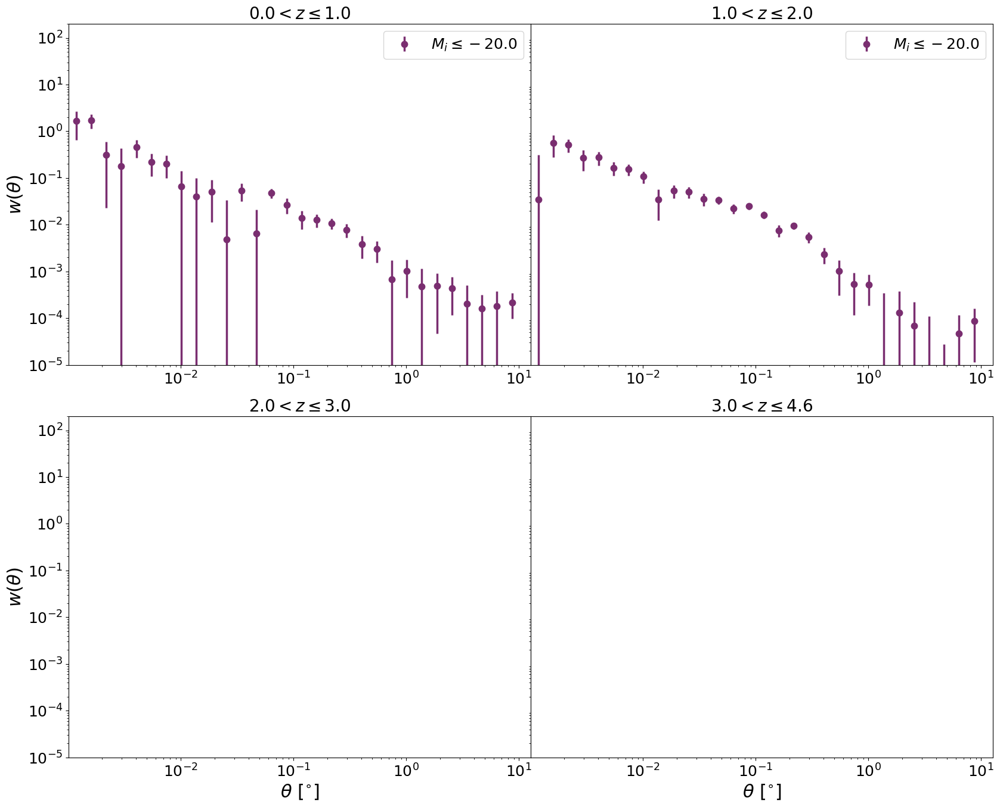

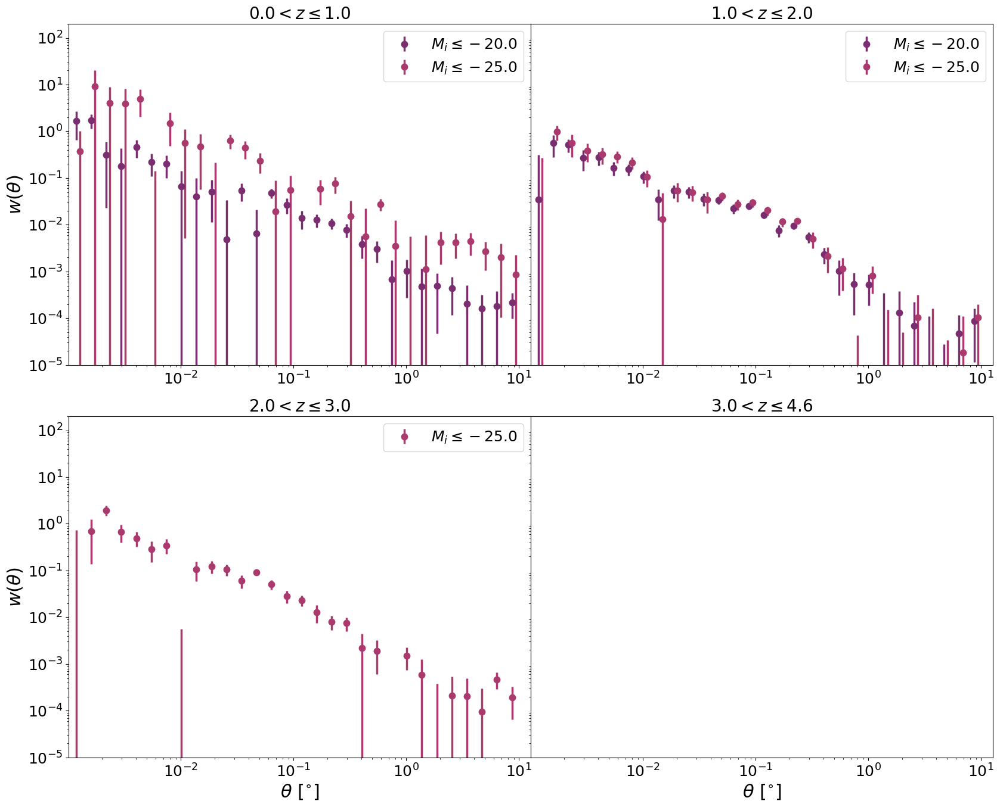

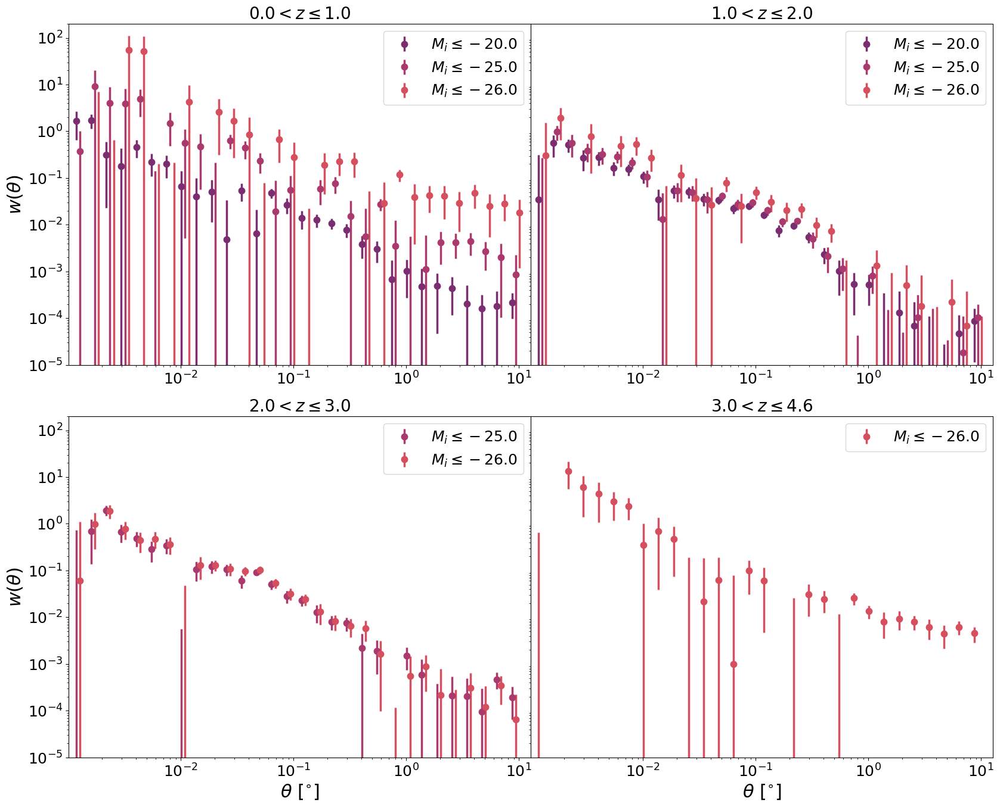

In [57]:
N=50
cosmo = 'Planck'
for l in range(1, len(L_bins)):

    fig = plt.figure(figsize = (20, 16))
    gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)
    
    # remove bottom panel and just print bq somewhere
    # plot!
    for j in range(len(z_array)):
    
        ax1 = fig.add_subplot(gs[j])
    
        k=0
        for i in range(len(L_bins[:l])):
    
            if (((i<3) and (N_q_b[L_bins[i]][j]>N_q_b[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q_b[L_bins[i]][j]/1000)>1):
                
                sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))))
                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))            
                
                ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + k*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'o', color = cmap_theta[i],
                            yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5

                ax1.legend(loc = 'upper right')

                k+=1

            ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(1e-5, 2e2)
            
            if j%2==0:
                ax1.set_ylabel(r"$w(\theta)$")
            else:
                ax1.set_yticks([])
            if j > 1:
                ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
    
    
    plt.show()

In [62]:
np.log10((5*u.arcmin).to(u.deg).value), np.log10(0.08)

(-1.0791812460476249, -1.0969100130080565)

# Load G20

In [52]:
G_lo = 20

<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:42: SyntaxWarning: invalid escape sequence '\m'
<>:49: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:42: SyntaxWarning: invalid escape sequence '\m'
<>:49: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_20596/475652251.py:27: SyntaxWarning: invalid escape sequence '\l'
  ax3.hist(tab_datahi_mask_zbin0['M_i'], color = 'white', edgecolor = colors[i], orientation = 'horizontal', bins = np.linspace(-32, -20, 30), alpha = 0.5, label = '$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_20596/475652251.py:35: SyntaxWarning: invalid escape sequence '\m'
  ax2.set_ylabel('$N_\mathrm{QSO}$')
/tmp/ipykernel_20596/475652251.py:42: SyntaxWarning: invalid escape sequence '\m'
  ax3.set_xlabel('$N_\mathrm{QSO}$')
/tmp/ipykernel_20596/475652251.py:49: SyntaxWarning: invalid escape sequenc

0.7606791583065621
Pixels masked by MC but not already by selfunc: 926
G20.0_zmin0.0zmax1.0_Lmax-20.0: 0.31              138599 vs 200785
0.7572178281423043
Pixels masked by MC but not already by selfunc: 2094
G20.0_zmin1.0zmax2.0_Lmax-20.0: 0.28              264696 vs 369335
0.7346083175107806
Pixels masked by MC but not already by selfunc: 1127
G20.0_zmin2.0zmax3.0_Lmax-20.0: 0.26              122259 vs 165277
0.862919347799225
Pixels masked by MC but not already by selfunc: 78
G20.0_zmin3.0zmax4.6_Lmax-20.0: 0.22              15923 vs 20451
0.7677528469026641
Pixels masked by MC but not already by selfunc: 493
G20.0_zmin0.0zmax1.0_Lmax-25.0: 0.39              31793 vs 51805
0.8262410502712552
Pixels masked by MC but not already by selfunc: 1963
G20.0_zmin1.0zmax2.0_Lmax-25.0: 0.30              240471 vs 343295
0.7346083175107806
Pixels masked by MC but not already by selfunc: 1127
G20.0_zmin2.0zmax3.0_Lmax-25.0: 0.26              122259 vs 165277
0.862919347799225
Pixels masked by M

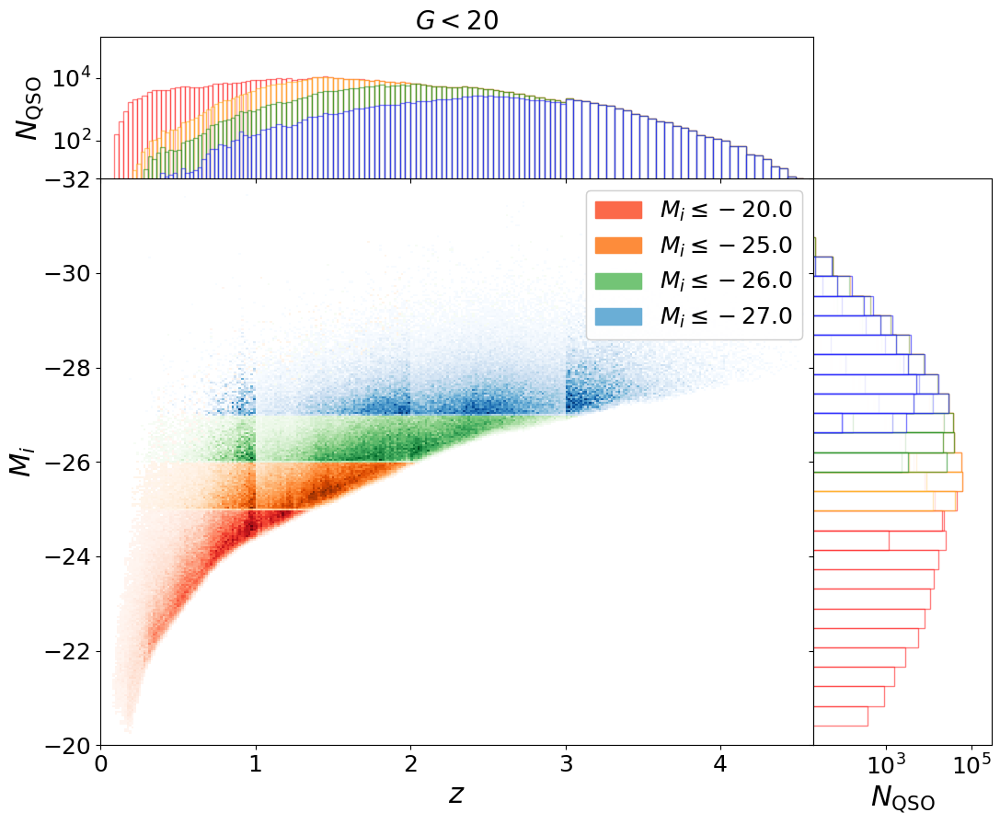

In [48]:
# plot!
fig = plt.figure(figsize = (12.5, 10))
gs = gridspec.GridSpec(2, 2, hspace = 0, height_ratios=[1,4], width_ratios=[4,1], wspace = 0)
fac_rand = 25

ax1 = fig.add_subplot(gs[2])
ax2 = fig.add_subplot(gs[0])
ax3 = fig.add_subplot(gs[3])

N_q = {L: [] for L in L_bins}

for i in range(len(L_bins)):
        
    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _ = quaia.make_bins(G_lo, [j, i], True, ['z', 'L'], 
                                                                                             bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                              method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                              mask = mask*100, percentile = True, n_bins = [None, None])
        quaia.absolute(tab_datahi_mask_zbin0, G_lo)
        h1, xedges, yedges, image = ax1.hist2d(tab_datahi_mask_zbin0['redshift_quaia'], tab_datahi_mask_zbin0['M_i'],
                                               cmap = plt.get_cmap('{}s'.format(colors[i])), bins = [np.linspace(0, 4.6, 300), np.linspace(-32, -20, 300)],
                                               cmin = 1)
        xlim = ax1.get_xlim()

        ax2.hist(tab_datahi_mask_zbin0['redshift_quaia'], color = 'white', edgecolor = colors[i], bins = 30, alpha = 0.5)
        ax3.hist(tab_datahi_mask_zbin0['M_i'], color = 'white', edgecolor = colors[i], orientation = 'horizontal', bins = np.linspace(-32, -20, 30), alpha = 0.5, label = '$M_i\leq{}$'.format(L_bins[i]))
        
        N_q[L_bins[i]].append(len(tab_datahi_mask_zbin0))
    
ax1.set_ylabel('$M_i$')
ax1.set_xlabel('$z$')
ax1.set_ylim(-20, -32)

ax2.set_ylabel('$N_\mathrm{QSO}$')
ax2.set_yscale('log')
ax2.set_xlim(xlim)
ax2.set_ylim(6,2e5)
ax2.set_xticklabels([])
ax2.set_title('$G<{}$'.format(G_lo))

ax3.set_xlabel('$N_\mathrm{QSO}$')
ax3.set_xscale('log')
ax3.set_yticklabels([])
ax3.set_ylim(-20, -32)
ax3.set_xlim(2e1,3e5)

custom_lines = [mpatches.Patch(color=plt.get_cmap('{}s'.format(colors[i]))(np.array(0.5))) for i in range(len(L_bins))]
second_legend = ax1.legend(custom_lines, ['$M_i\leq{}$'.format(L) for L in L_bins])
fig.add_artist(second_legend)

plt.show()

In [49]:
tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _ = quaia.make_bins(G_lo, 0, True, 'z', 
                                                                                             bins = [0,4.6], tab_gcat_type = 'data', fac_rand = fac_rand, 
                                                                                              mask = mask*100, percentile = True, n_bins = None)

Leaving tab_gcat_catalog unbinned
0.7194458197343285
Pixels masked by MC but not already by selfunc: 4231
G20.0: 0.28              541420 vs 755850


In [50]:
quaia.absolute(tab_datahi_mask_zbin0, G_lo)

array([14059.89879616, 10102.60285244, 14612.75678367, ...,
       31285.56565415,  8835.65755401, 20128.83921923])

<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:37: SyntaxWarning: invalid escape sequence '\m'
<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:37: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_20596/2127205833.py:29: SyntaxWarning: invalid escape sequence '\m'
  ax2_hi.set_ylabel('N$_\mathrm{QSO}$')
/tmp/ipykernel_20596/2127205833.py:37: SyntaxWarning: invalid escape sequence '\m'
  ax3_hi.set_xlabel('N$_\mathrm{QSO}$')


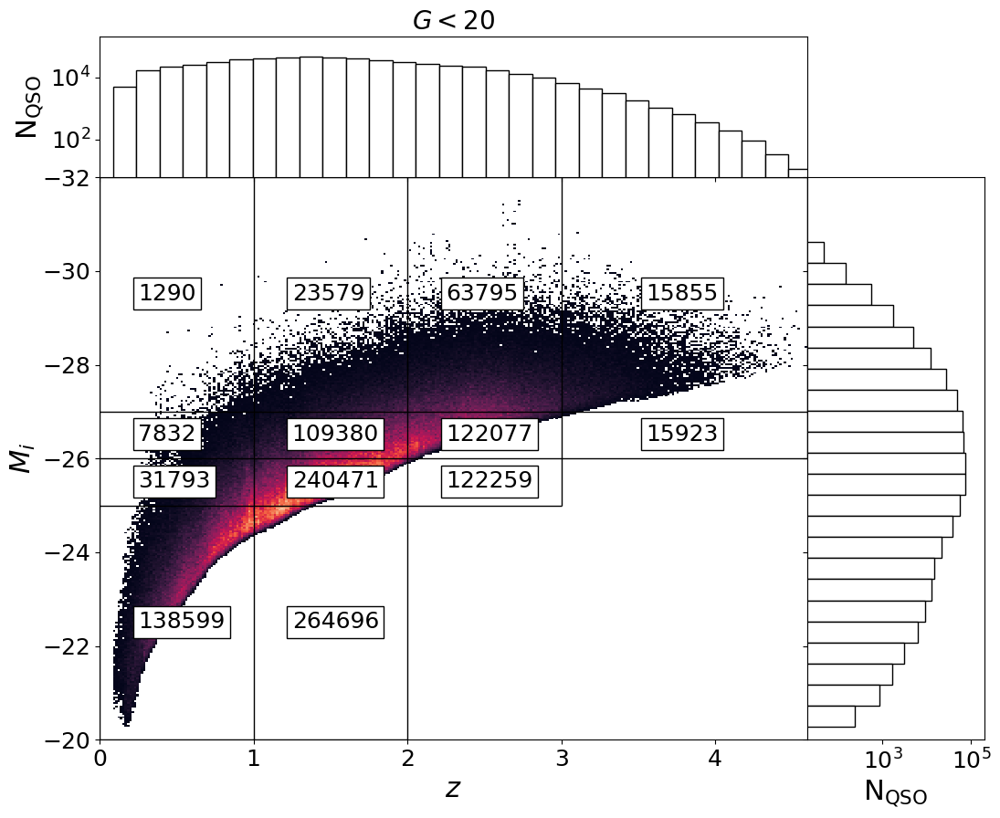

In [52]:
# plot!
fig = plt.figure(figsize = (12.5, 10))
gs = gridspec.GridSpec(2, 2, hspace = 0, height_ratios=[1,4], width_ratios=[4,1], wspace = 0)

ax1_hi = fig.add_subplot(gs[2])

h1, xedges, yedges, image = ax1_hi.hist2d(tab_datahi_mask_zbin0['redshift_quaia'], tab_datahi_mask_zbin0['M_i'], cmap = cmap_rocket, bins = 300, 
                                       cmin = 1)

for L_bin, xmax in zip(L_array, [z_bins[2], z_bins[3], z_bins[4], z_bins[4], z_bins[4]]):
    ax1_hi.hlines(L_bin, color = 'black', xmin = z_bins[0], xmax = xmax, linewidth = 1)
for z_bin, ymax in zip(z_bins, [L_bins[0], L_bins[0], L_bins[0], L_bins[1], L_bins[2]]):
    ax1_hi.vlines(z_bin, color = 'black', ymin = -32, ymax = ymax, linewidth = 1)
    
for i in z_array:
    for j in range(len(L_bins)):
        if ((j<3) and (N_q[L_bins[j]][i]>N_q[L_bins[j+1]][i])) or (j ==3):
            ax1_hi.text(quaia.recenter(z_bins)[i]-0.25, quaia.recenter(L_array)[j]+0.125, N_q[L_bins[j]][i], fontsize = 18, color = 'black', bbox=dict(facecolor='white'))
            
ax1_hi.set_ylabel('$M_i$')
xlim = ax1.get_xlim()
ax1_hi.set_xlabel('$z$')
ax1_hi.set_ylim(-20, -32)
ax1_hi.set_xlim(xlim[0], z_bins[-1])

ax2_hi = fig.add_subplot(gs[0])
ax2_hi.hist(tab_datahi_mask_zbin0['redshift_quaia'], color = 'white', edgecolor = 'black', bins = 30)
ax2_hi.set_title('$G<{}$'.format(G_lo))
ax2_hi.set_ylabel('N$_\mathrm{QSO}$')
ax2_hi.set_yscale('log')
ax2_hi.set_xlim(xlim[0], z_bins[-1])
ax2_hi.set_ylim(6,2e5)
ax2_hi.set_xticklabels([])

ax3_hi = fig.add_subplot(gs[3])
ax3_hi.hist(tab_datahi_mask_zbin0['M_i'], color = 'white', edgecolor = 'black', orientation = 'horizontal', bins = 25)
ax3_hi.set_xlabel('N$_\mathrm{QSO}$')
ax3_hi.set_xscale('log')
ax3_hi.set_yticklabels([])
ax3_hi.set_ylim(-20, -32)
ax3_hi.set_xlim(2e1,2e5)

plt.show()

## Plot correlation matrix

<>:23: SyntaxWarning: invalid escape sequence '\l'
<>:26: SyntaxWarning: invalid escape sequence '\l'
<>:23: SyntaxWarning: invalid escape sequence '\l'
<>:26: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_20596/2447837386.py:23: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$r_{{p,{:.1f}<z \leq{:.1f}}} (h^{{-1}}$ Mpc)'.format(z_bins[i], z_bins[i+1]))
/tmp/ipykernel_20596/2447837386.py:26: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[j]))


(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)
(-1.0, 1.0)


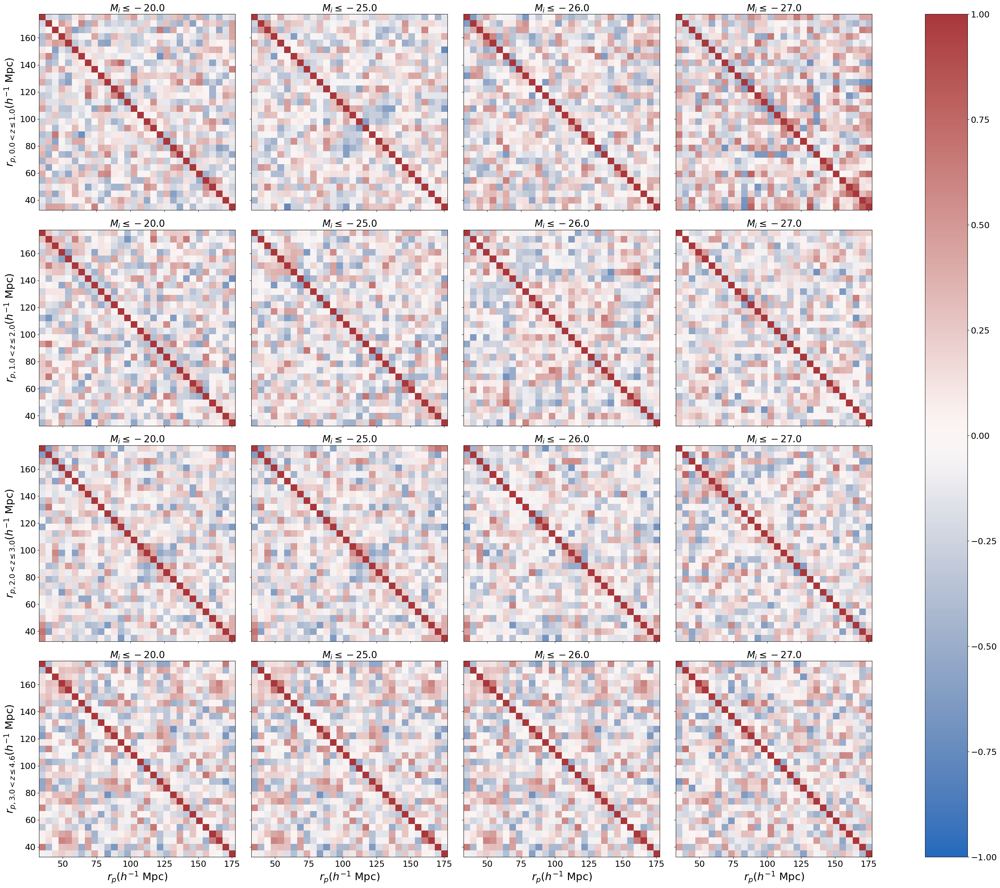

In [53]:
cmap = sns.color_palette("vlag", as_cmap=True)
r = quaia.recenter(rbins_chi2) #_chi2)

# plot!
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
axes = []
for i in range(len(z_bins)-1):
    
    for j in range(len(L_bins)):
    
        ax1 = fig.add_subplot(gs[i*4+j])

        C = np.load('../results/cov_wp_G{:.1f}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask.npy'.format(G_lo, rmin, rmax, nbins, pimax, z_bins[i], z_bins[i+1], L_bins[j], N, cosmo))
        matrix = np.corrcoef(C)
        image = ax1.imshow(matrix, cmap = cmap, extent = [r[0], r[-1], r[0], r[-1]], vmin = -1, vmax = 1)
        print(image.get_clim())
        if i > 2:
            ax1.set_xlabel('$r_p (h^{-1}$ Mpc)')
        else:
            ax1.set_xticklabels([])
        if j == 0:
            ax1.set_ylabel('$r_{{p,{:.1f}<z \leq{:.1f}}} (h^{{-1}}$ Mpc)'.format(z_bins[i], z_bins[i+1]))
        else:
            ax1.set_yticklabels([])
        ax1.set_title('$M_i\leq{}$'.format(L_bins[j]))
        axes.append(ax1)
    
fig.colorbar(image, ax = axes)
plt.show()

# Calculate derived parameters

<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:82: SyntaxWarning: invalid escape sequence '\m'
<>:19: SyntaxWarning: invalid escape sequence '\l'
<>:82: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_20596/807909714.py:19: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_20596/807909714.py:82: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5, capsize = 2.5,


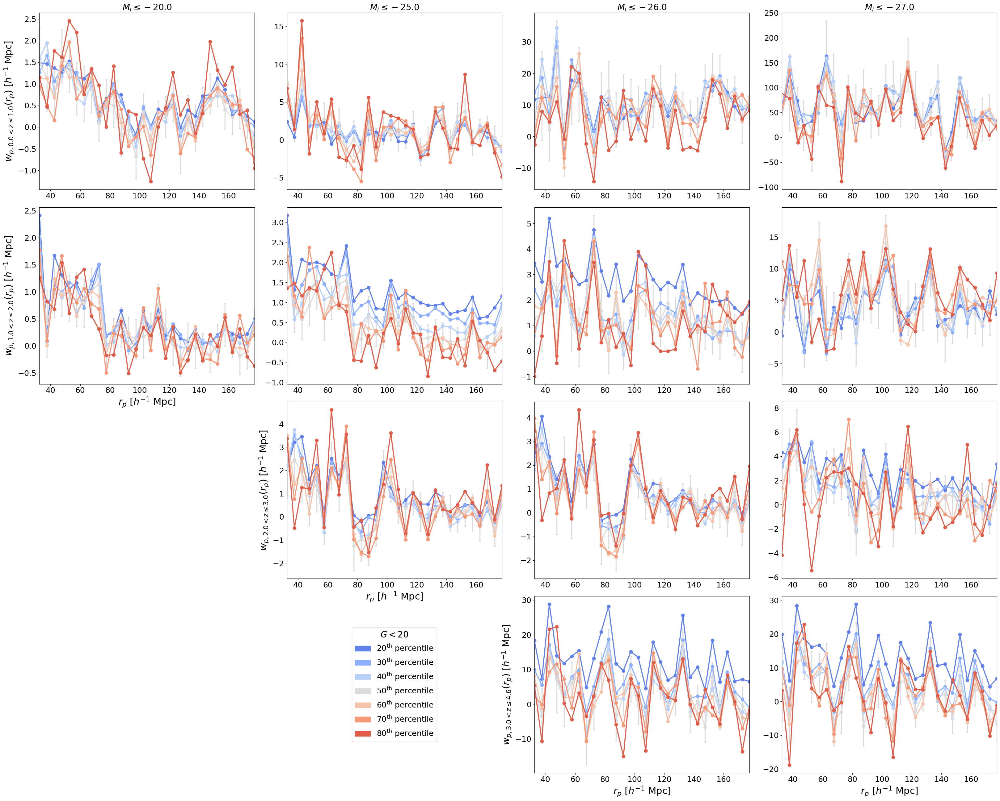

In [59]:
r = quaia.recenter(rbins_chi2) #_chi2)
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
a_zbin = {L: [] for L in L_bins}

fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.15, hspace = 0.1)

H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc

for j in z_array:
    
    for i in range(len(L_bins)):

        if ((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            if j ==0:
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if scale == 'log':
                ax1.set_xscale('log')
            ax1.set_xlim(r[0], r[-1])
            
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(r_p)$ $[h^{{-1}}$ Mpc]".format(z_bins[j], z_bins[j+1]))
        else:

            ax2 = fig.add_subplot(gs[j*4+i])
            ax2.set_axis_off()
                
        for k in range(len(masks)):
                    
            try:
                
                wp_zbin_i = np.load('../results/wp_G{:.1f}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_lo, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k]))
                rpavg_zbin_i = np.load('../results/rpavg_G{:.1f}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_lo, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k]))
                a = float(np.load('../results/a_G{:.1f}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}.npy'.format(G_lo, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k])))

            except:

                tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, selfunc_hi_bin0, = quaia.make_bins(G_lo, [j, i], True, ['z', 'L'], 
                                                                                             bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                              method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                              mask = masks[k]*100, percentile = True, n_bins = [None, None])
                
                # quasar correlation function
                wp_zbin_i, rpavg_zbin_i = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, nthreads = nthreads, 
                                                                              rbins = rbins_chi2, nbins = nbins, pimax = pimax, Om0 = Planck18.Om0, h = Planck18.h)

                # scale factor
                a = a_median(tab_datahi_mask_zbin0)
                
                np.save('../results/wp_G{:.1f}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}'.format(G_lo, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k]), wp_zbin_i)
                np.save('../results/rpavg_G{:.1f}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}'.format(G_lo, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k]), rpavg_zbin_i)
                np.save('../results/a_G{:.1f}_zmin{}zmax{}_Lmax{}_{}_MC_mask{}'.format(G_lo, z_bins[j], z_bins[j+1], L_bins[i], cosmo, masks[k]), a)
            
            if masks[k] == 0.5:
                
                sigma = np.sqrt(np.diag(np.load('../results/cov_wp_G{:.1f}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask.npy'.format(G_lo, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo))))

                wp_chi2[L_bins[i]].append(wp_zbin_i)
                rpavg_chi2[L_bins[i]].append(rpavg_zbin_i)
                a_zbin[L_bins[i]].append(a)

                # matter correlation function   
                s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
                s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))

                xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
                wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
                wp_matter_chi2[L_bins[i]].append(wp_matter_zbin_i)   
            
            else: 
                sigma = 0

            # plot!

            if ((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3):
                    
                ax1.errorbar(rpavg_zbin_i, wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5, capsize = 2.5,
                         linewidth = 2.5, color = cmap_masks[k], yerr = sigma, linestyle = '-')

                
custom_lines = [mpatches.Patch(color=cmap_masks[i]) for i in range(len(masks))]
first_legend = ax2.legend(custom_lines, [r'${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100) for mask in masks], loc = 'center', title = r'$G<{}$'.format(G_lo), title_fontsize = 20)
fig.add_artist(first_legend)

plt.show()

### Test $M_{min}$

<>:51: SyntaxWarning: invalid escape sequence '\l'
<>:51: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_20596/1121689245.py:51: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


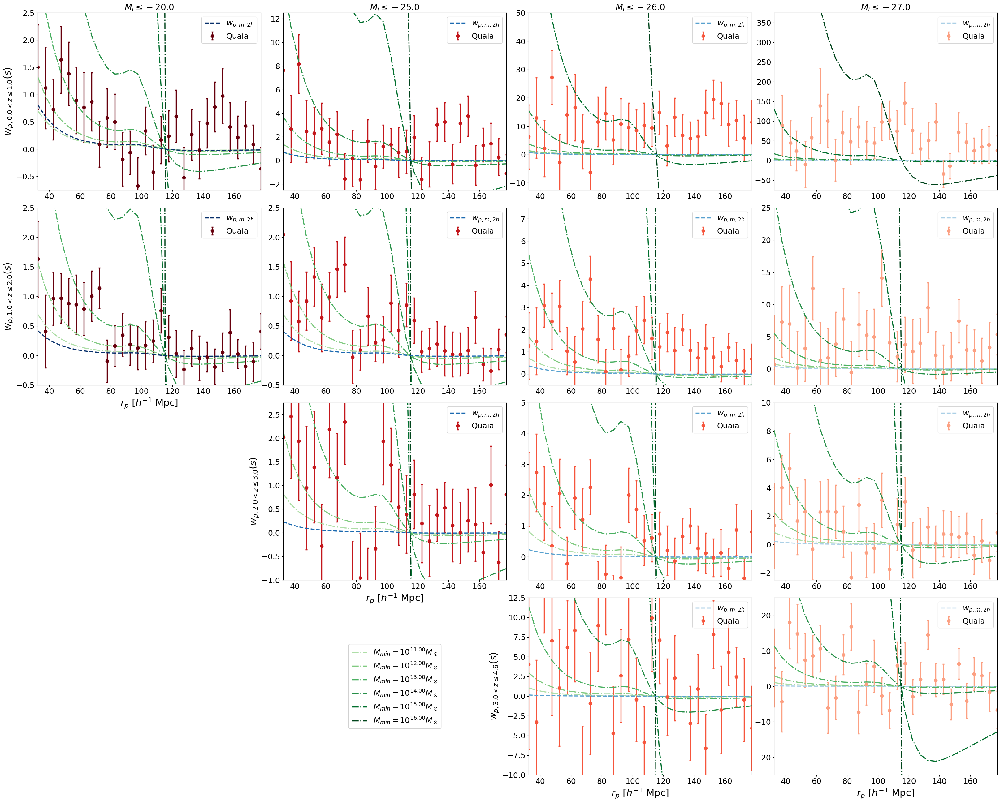

In [55]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0.1, hspace = 0.1)
ylims = [[-0.75, 2.5], [-2.5, 12.5], [-12.5, 50], [-75, 375]], [[-0.5, 2.5], [-0.5, 2.5], [-0.5, 7.5], [-2.5, 25]], [[np.nan, np.nan], [-1, 2.75], [-0.75, 5], [-2.5, 10]], [[np.nan, np.nan], [np.nan, np.nan], [-10, 12.5], [-25, 25]]
m = 0
for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if ((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3):

            ax1 = fig.add_subplot(gs[j*4+i])

            C = np.load('../results/cov_wp_G{:.1f}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask.npy'.format(G_lo, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo))
                   
            ax1.errorbar(rpavg_chi2[L_bins[i]][j], wp_chi2[L_bins[i]][j], linewidth = 2.5, marker = 'o', label = r'Quaia', color = cmap_red[::-1][i],
                        yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, capsize = 2.5, linestyle = 'none')
            if quaia.recenter(rbins_chi2)[0] < 30:
                ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                                  alpha = 0.5, label = 'scales excluded from fit')
                ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                                  alpha = 0.5)
        
            # wp_2h_samples = []
            # for l in range(len(ind)):
            #     n_m=np.ones(np.shape(bins))*f_duty_samples[L_bins[i]][j][l]
            #     wp_2h_sample, _ = wp_2h(np.logspace(M_min_samples[L_bins[i]][j][l],M_max,79), n_m, a_zbin[L_bins[i]][j], cosmo_planck18, 
            #                             wp_matter_chi2[L_bins[i]][j], recenter = False)
            #     wp_2h_samples.append(wp_2h_sample)
            # wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
            # ax1.plot(quaia.recenter(rbins_chi2), wp_2h_50, linewidth = 2.5,
            #          label = r'$w_{{p,q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot)$'.format(f_duty[L_bins[i]][j], 
            #                                                                                                     M_min[L_bins[i]][j]), 
            #          color = cmap_blue[::-1][i])
            # ax1.fill_between(quaia.recenter(rbins_chi2), wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5,
            #          color = cmap_blue[::-1][i])  
            
            # test higher Mmin values
            for k in range(len(Mmins)):
                n_m=np.ones(np.shape(bins)) #*10**f_duty[L_bins[i]][j]
                wp_2h_zbin, b_q = wp_2h(np.logspace(Mmins[k],16.8,79), n_m, a_zbin[L_bins[i]][j], cosmo_planck18, wp_matter_chi2[L_bins[i]][j], 
                                        recenter = False)
                ax1.plot(quaia.recenter(rbins_chi2), wp_2h_zbin, linewidth = 2.5, linestyle = '-.', color = cmap_green[k]) #,
                    
            # plot matter
            ax1.plot(quaia.recenter(rbins_chi2), wp_matter_chi2[L_bins[i]][j], linewidth = 2.5, linestyle = '--',
                     label = r'$w_{{p,m,2h}}$', color = cmap_blue[::-1][i])
        
            if j==0:
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
            ax1.set_ylim(ylims[j][i])
            ax1.legend()
            
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{p,{:.1f}<z \leq{:.1f}}}(s)$".format(z_bins[j], z_bins[j+1]))
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') 
        
        else:
        
            if m == 2:
                ax1 = fig.add_subplot(gs[j*4+i])
                ax1.set_axis_off()
                custom_lines = [Line2D([0], [0], color = cmap_green[i], linestyle = '-.', linewidth = 2.5) for i in range(len(Mmins))]
                second_legend = ax1.legend(custom_lines, [r'$M_{{min}}=10^{{{:.2f}}}M_\odot$'.format(Mmin) for Mmin in Mmins], bbox_to_anchor = (0.5, 0.5), 
                                           loc='center')
                fig.add_artist(second_legend)
            m+=1

plt.show()

# HOD Model

In [24]:
M_min = 12.5

In [25]:
f_duty = 1e-2

In [26]:
colors = sns.color_palette('deep', n_colors = 3)

In [27]:
cmap_HOD = sns.light_palette(colors[1], n_colors =  len(sigma_array))
palette_HOD = sns.light_palette(colors[1], as_cmap = True)

In [28]:
n_bins = 201
bins = np.logspace(9, M_max, n_bins)

<>:12: SyntaxWarning: invalid escape sequence '\S'
<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:12: SyntaxWarning: invalid escape sequence '\S'
<>:14: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_139496/4223099410.py:12: SyntaxWarning: invalid escape sequence '\S'
  label = '$\Sigma={}$ dex'.format(sigma_array[j]), color = cmap_HOD[j])
/tmp/ipykernel_139496/4223099410.py:14: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_xlabel('$\log_{10}(M_\mathrm{min}/M_\odot)$', fontsize = 27)
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))


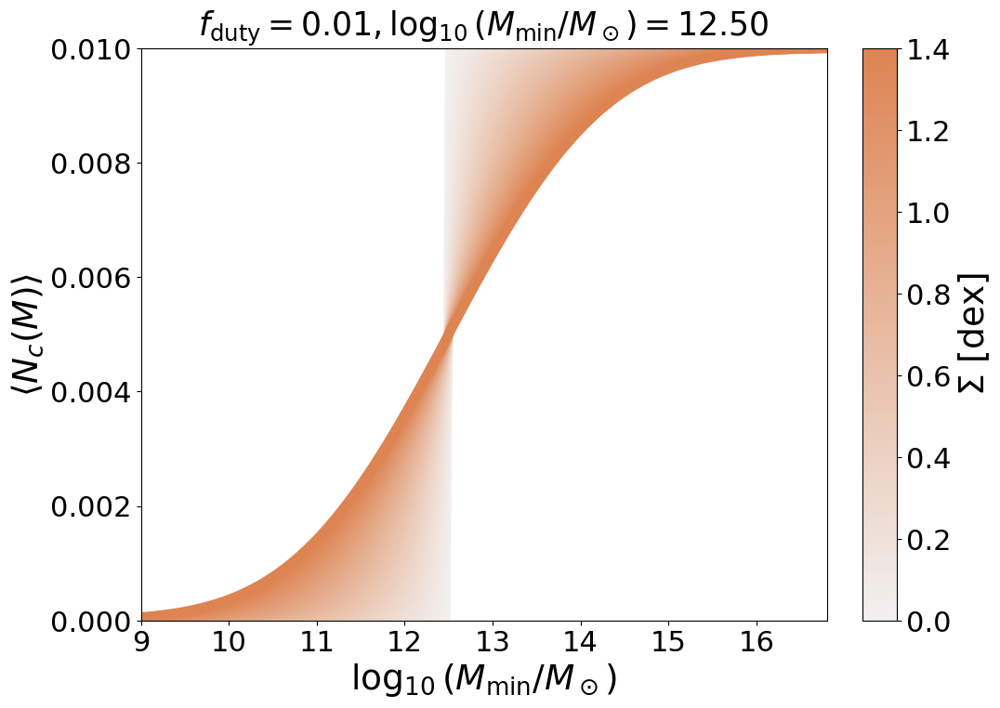

In [45]:
sigma_array = np.linspace(0, 1.4)

fig = plt.figure(figsize = (10.5, 8))
gs = gridspec.GridSpec(1, 2, width_ratios = [1,0.05], wspace = 0.1)
n_m_array, bins_M_min = [], []

ax1 = fig.add_subplot(gs[0])

for j in range(len(sigma_array)):
# j=0
    ax1.plot(np.log10(bins), sampler.N_c(bins, M_min, f_duty, 3, sigma = sigma_array[j]), linewidth = 7, linestyle ='-', 
             label = '$\Sigma={}$ dex'.format(sigma_array[j]), color = cmap_HOD[j])

ax1.set_xlabel('$\log_{10}(M_\mathrm{min}/M_\odot)$', fontsize = 27)
ax1.set_ylabel(r'$\langle N_c(M) \rangle$', fontsize = 27)
ax1.set_xlim(9,M_max)
ax1.set_ylim(0, f_duty)
ax1.tick_params(axis='both', labelsize=22)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_HOD, norm = matplotlib.colors.Normalize(vmin=0, vmax = 1.4)), cax = fig.add_subplot(gs[:,-1]))#, 
                # label = '$\Sigma$ [dex]', labelsize = 20)
cbar.set_label(r'$\Sigma$ [dex]', fontsize=27)
cbar.ax.tick_params(labelsize=22)
ax1.set_title(rf'''$f_\mathrm{{duty}}={f_duty:.2f}, \log_{{10}}(M_\mathrm{{min}}/M_\odot)={M_min:.2f}$''', fontsize = 25)

plt.savefig('../figures/HOD_Modot.pdf', bbox_inches = 'tight')
plt.show()

In [168]:
Sigma = 0.4 
n_c=sampler.N_c(bins, M_min, f_duty, 3, sigma = Sigma)

In [171]:
Alpha = 1.8
n_s = sampler.N_s(bins, f_duty, 10**M_min, 12*10**M_min, Alpha)

/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:166: RuntimeWarning: invalid value encountered in power
  n_m = fduty*((bins_m-M0)/M1)**alpha


<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:9: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_7112/2618947282.py:9: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\log_{10} (M/M_\odot)$')


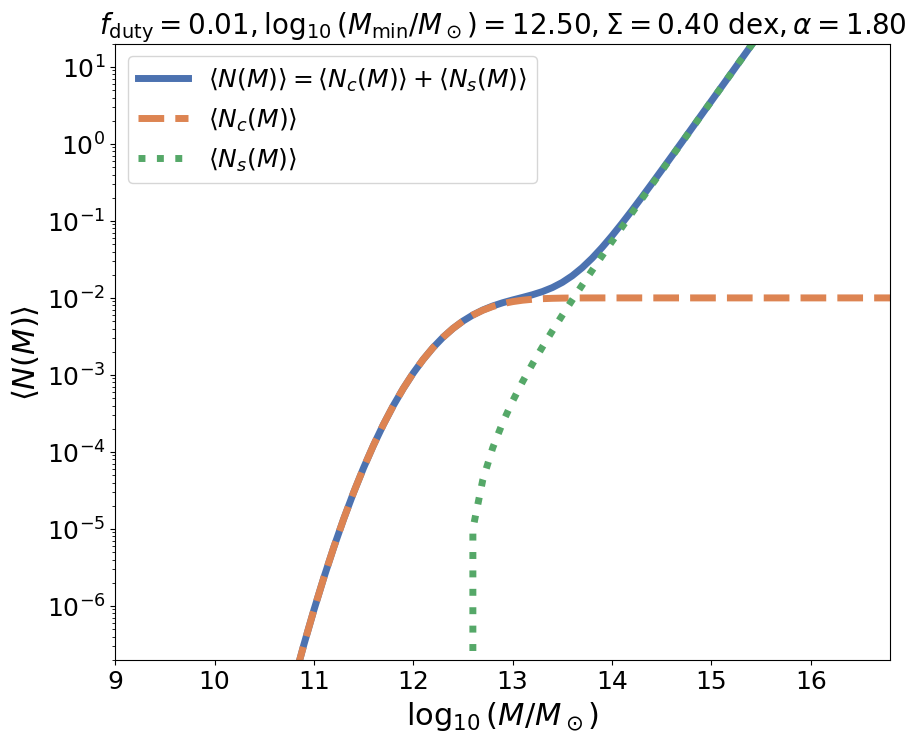

In [215]:
fig = plt.figure(figsize = (10, 8))

plt.plot(np.log10(bins), n_c+n_s, linewidth = 5, linestyle = '-', 
         label = r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', color = colors[0])
plt.plot(np.log10(bins), n_c, linewidth = 5, linestyle = '--', label = r'$\langle N_c(M) \rangle$', color = colors[1]) #color = cmap_theta[i], 
plt.plot(np.log10(bins), n_s, linewidth = 5, linestyle = ':', label = r'$\langle N_s(M) \rangle$', color = colors[2])

# plt.xscale('log')
plt.xlabel('$\log_{10} (M/M_\odot)$')
plt.ylabel(r'$\langle N(M) \rangle$')
plt.legend()
plt.yscale('log')
plt.xlim(9, M_max)
plt.ylim(2e-7, 2e1)
plt.title(rf'''$f_\mathrm{{duty}}={f_duty:.2f}, \log_{{10}}(M_\mathrm{{min}}/M_\odot)={M_min:.2f}, \Sigma={Sigma:.2f}$ dex$, \alpha = {Alpha:.2f}$''')

plt.savefig('../figures/N_m.pdf', bbox_inches = 'tight')
plt.show()

## Effect of HOD parameters on clustering

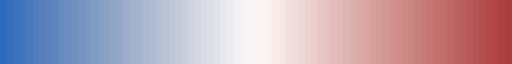

In [36]:
cmap_M_min = sns.color_palette("vlag", n_colors = len(bins))
palette_M_min = matplotlib.colors.ListedColormap(cmap_M_min)
palette_M_min

In [40]:
z = 0
a = 1/(1+z)
a

1.0

In [41]:
H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc

In [111]:
# matter correlation function   
s = np.sqrt(np.sum(np.meshgrid(np.array(quaia.recenter(rbins_chi2))**2, quaia.recenter(pibins)**2), axis = 0))
s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))
    
xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a)
wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)

In [112]:
sigma = 0.7

In [113]:
sigma_k_array = np.linspace(0,1.4, 51) #-4

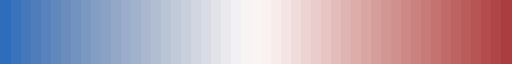

In [114]:
cmap_sigma = sns.color_palette("vlag", n_colors = len(sigma_k_array))
palette_sigma = matplotlib.colors.ListedColormap(cmap_sigma)
palette_sigma

In [115]:
delta = 0.7-1e-5 #0.1

In [234]:
delta_Mmin = 1.1

<>:46: SyntaxWarning: invalid escape sequence '\l'
<>:65: SyntaxWarning: invalid escape sequence '\D'
<>:88: SyntaxWarning: invalid escape sequence '\D'
<>:46: SyntaxWarning: invalid escape sequence '\l'
<>:65: SyntaxWarning: invalid escape sequence '\D'
<>:88: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2061/4231876577.py:46: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$\log_{{10}}(M_\mathrm{{min}})={:.1f}$ $M_\odot, \Sigma={}$ dex'.format(M_min, sigma))
/tmp/ipykernel_2061/4231876577.py:65: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_2061/4231876577.py:88: SyntaxWarning: invalid escape sequence '\D'
  cax = fig.add_subplot(gs[1,-1]), label = '$\Delta \Sigma$ [dex]')


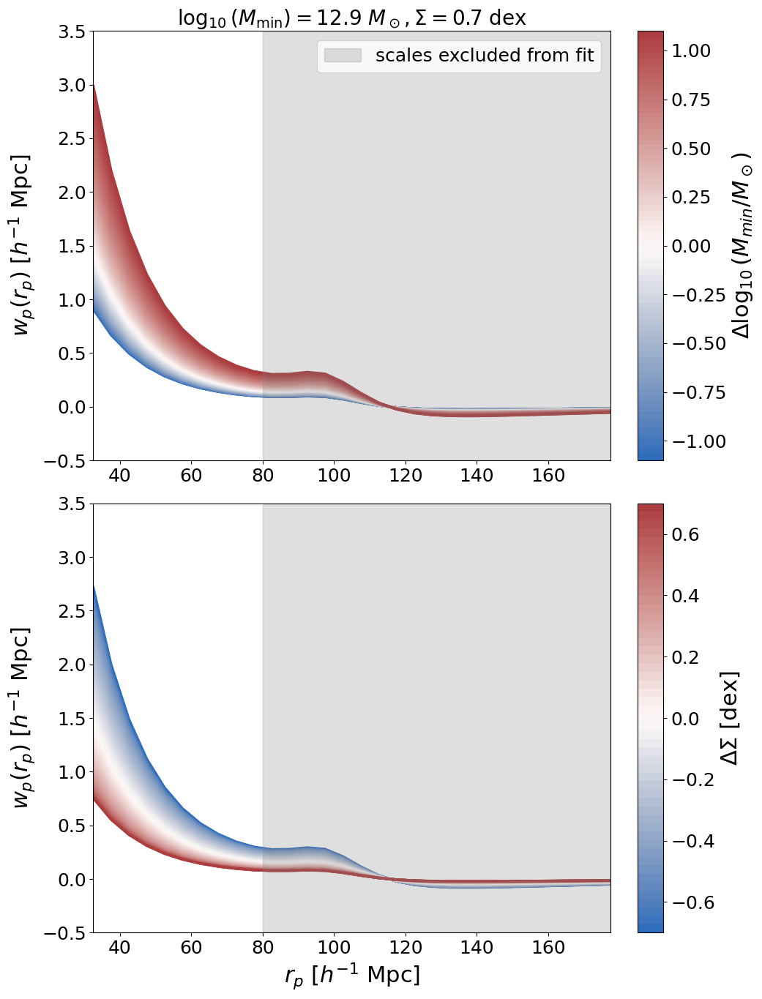

In [241]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (10.05, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0.1, hspace = 0.1, width_ratios = [1,0.05])
ylim = -0.5, 3.5
l = 0
y=np.linspace(ylim[0], ylim[-1])
alpha = 0.25
# for j in range(len(z_array)):
    
#     for i in range(len(L_bins)):

        # if ((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3):

ax1 = fig.add_subplot(gs[0])

# C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_mask.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], 
#                                                                                                         z_bins[j+1], L_bins[i], N, cosmo))

if quaia.recenter(rbins_chi2)[-1] > 80:
    ax1.fill_betweenx(y, x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                      alpha = alpha, label = 'scales excluded from fit')
    ax1.fill_betweenx(y, x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                      alpha = alpha)

for k in range(len(bins)):
    n_m=HOD_scatter(10**f_duty, M_min+delta_Mmin*(-1+k/int(len(bins)/2)), bins, sigma)
    wp_2h_sample, _ = wp_2h(bins, n_m, a, 
             cosmo_planck18, wp_matter_zbin_i, recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_sample, linewidth = 2.5, color = cmap_M_min[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    
# wp_2h_samples = []
# for k in range(len(ind)):
#     n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][k], M_min_samples[L_bins[i]][j][k], bins, sigma_samples[L_bins[i]][j][k])
#     wp_2h_sample, _ = wp_2h(bins, n_m, a_zbin[L_bins[i]][j], cosmo_planck18, 
#                             wp_matter_chi2[L_bins[i]][j], recenter = False)
#     wp_2h_samples.append(wp_2h_sample)
# wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
# ax1.plot(quaia.recenter(rbins_offset), wp_2h_50, linewidth = 2.5,
#          label = r'$w_{{p,q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex)'.format(f_duty[L_bins[i]][j], M_min[L_bins[i]][j], sigma[L_bins[i]][j]), 
#          color = cmap_blue[::-1][i])
# ax1.fill_between(quaia.recenter(rbins_chi2), wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5,
#          color = cmap_blue[::-1][i])    

# if j==0:
ax1.set_title('$\log_{{10}}(M_\mathrm{{min}})={:.1f}$ $M_\odot, \Sigma={}$ dex'.format(M_min, sigma))
# ax1.set_title('$\Sigma={}$ dex'.format(sigma))
# ax1.set_yscale('log')
ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
ax1.set_ylim(ylim)
ax1.legend()

# if i==0 or ((j>1) and (i<3) and (i!=j)):
ax1.set_ylabel(r"$w_p(r_p)$ $[h^{{-1}}$ Mpc]")
# else:
# ax1.set_yticklabels([])

# if j > 2 or ((j>0) and (i<2) and (i!=j)):
# ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') 

# if i == 3:
#     l+=2

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-delta_Mmin, vmax = delta_Mmin)), cax = fig.add_subplot(gs[0,-1]), 
                label = '$\Delta \log_{10}(M_{min}/M_\odot)$')

ax1 = fig.add_subplot(gs[2])

for k in range(len(sigma_k_array)):
    n_m=HOD_scatter(10**f_duty, M_min, bins, sigma+delta*(-1+k/int(len(sigma_k_array)/2)))
    wp_2h_sample, _ = wp_2h(bins, n_m, a, 
             cosmo_planck18, wp_matter_zbin_i, recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_sample, linewidth = 2.5, color = cmap_sigma[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))

if quaia.recenter(rbins_chi2)[-1] > 80:
    ax1.fill_betweenx(y, x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                      alpha = alpha, label = 'scales excluded from fit')
    ax1.fill_betweenx(y, x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                      alpha = alpha)
    
# ax1.set_title('$\log_{{10}}(M_\mathrm{{min}})={:.1f} M_\odot$'.format(M_min))
ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
ax1.set_ylabel(r"$w_p(r_p)$ $[h^{{-1}}$ Mpc]")
ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]')
ax1.set_ylim(ylim)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_sigma, norm = matplotlib.colors.Normalize(vmin=-delta, vmax = delta)), 
                    cax = fig.add_subplot(gs[1,-1]), label = '$\Delta \Sigma$ [dex]')

plt.savefig('../figures/HOD_clustering.pdf', bbox_inches = 'tight')
plt.show()

<>:22: SyntaxWarning: invalid escape sequence '\S'
<>:29: SyntaxWarning: invalid escape sequence '\D'
<>:45: SyntaxWarning: invalid escape sequence '\l'
<>:53: SyntaxWarning: invalid escape sequence '\D'
<>:22: SyntaxWarning: invalid escape sequence '\S'
<>:29: SyntaxWarning: invalid escape sequence '\D'
<>:45: SyntaxWarning: invalid escape sequence '\l'
<>:53: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2061/1159918185.py:22: SyntaxWarning: invalid escape sequence '\S'
  ax1.set_title('$\Sigma={}$ dex'.format(sigma))
/tmp/ipykernel_2061/1159918185.py:29: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_2061/1159918185.py:45: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$\log_{{10}}(M_\mathrm{{min}})={:.1f}$ $M_\odot$'.format(M_min))
/tmp/ipykernel_2061/1159918185.py:53: SyntaxWarning: invalid escape sequence '\D'
  cax = fig.add_subplot(gs[6]), label = '$\Delta \Sigma$ [dex]')


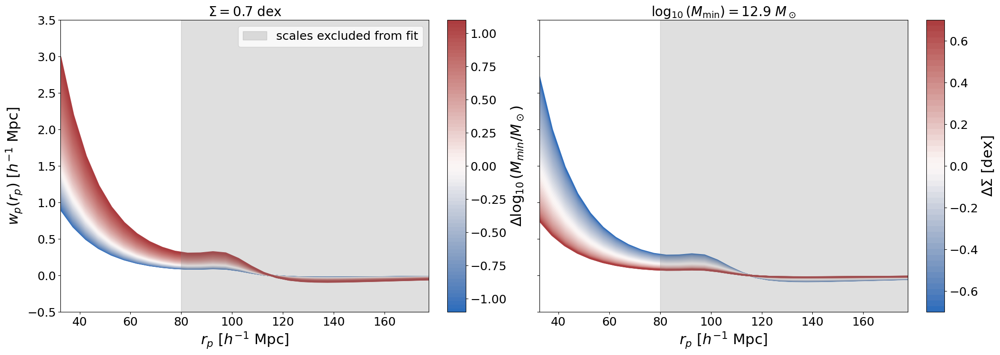

In [246]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (24, 8))
gs = gridspec.GridSpec(1, 7, wspace = 0, hspace = 0.1, width_ratios = [1, 0.05, 0.05, 0.2, 1, 0.05, 0.05])
ylim = -0.5, 3.5
l = 0

ax1 = fig.add_subplot(gs[0])

if quaia.recenter(rbins_chi2)[-1] > 80:
    ax1.fill_betweenx(y, x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                      alpha = alpha, label = 'scales excluded from fit')
    ax1.fill_betweenx(y, x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                      alpha = alpha)

for k in range(len(bins)):
    n_m=HOD_scatter(10**f_duty, M_min+delta_Mmin*(-1+k/int(len(bins)/2)), bins, sigma)
    wp_2h_sample, _ = wp_2h(bins, n_m, a, 
             cosmo_planck18, wp_matter_zbin_i, recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_sample, linewidth = 2.5, color = cmap_M_min[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))  

ax1.set_title('$\Sigma={}$ dex'.format(sigma))
ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
ax1.set_ylim(ylim)
ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]')
ax1.legend()
ax1.set_ylabel(r"$w_p(r_p)$ $[h^{{-1}}$ Mpc]")
cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-delta_Mmin, vmax = delta_Mmin)), cax = fig.add_subplot(gs[2]), 
                label = '$\Delta \log_{10}(M_{min}/M_\odot)$')

ax1 = fig.add_subplot(gs[4])

for k in range(len(sigma_k_array)):
    n_m=HOD_scatter(10**f_duty, M_min, bins, sigma+delta*(-1+k/int(len(sigma_k_array)/2)))
    wp_2h_sample, _ = wp_2h(bins, n_m, a, 
             cosmo_planck18, wp_matter_zbin_i, recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_sample, linewidth = 2.5, color = cmap_sigma[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))

if quaia.recenter(rbins_chi2)[-1] > 80:
    ax1.fill_betweenx(y, x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                      alpha = alpha, label = 'scales excluded from fit')
    ax1.fill_betweenx(y, x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                      alpha = alpha)
    
ax1.set_title('$\log_{{10}}(M_\mathrm{{min}})={:.1f}$ $M_\odot$'.format(M_min))
ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
# ax1.set_ylabel(r"$w_p(r_p)$ $[h^{{-1}}$ Mpc]")
ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]')
ax1.set_yticklabels([])
ax1.set_ylim(ylim)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_sigma, norm = matplotlib.colors.Normalize(vmin=-delta, vmax = delta)), 
                    cax = fig.add_subplot(gs[6]), label = '$\Delta \Sigma$ [dex]')

plt.savefig('../figures/HOD_clustering_horizontal.pdf', bbox_inches = 'tight')
plt.show()

<>:22: SyntaxWarning: invalid escape sequence '\S'
<>:29: SyntaxWarning: invalid escape sequence '\D'
<>:39: SyntaxWarning: invalid escape sequence '\l'
<>:47: SyntaxWarning: invalid escape sequence '\D'
<>:22: SyntaxWarning: invalid escape sequence '\S'
<>:29: SyntaxWarning: invalid escape sequence '\D'
<>:39: SyntaxWarning: invalid escape sequence '\l'
<>:47: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2061/1778038400.py:22: SyntaxWarning: invalid escape sequence '\S'
  ax1.set_title('$\Sigma={}$ dex'.format(sigma))
/tmp/ipykernel_2061/1778038400.py:29: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)[\%]$')
/tmp/ipykernel_2061/1778038400.py:39: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$\log_{{10}}(M_\mathrm{{min}})={:.1f} M_\odot$'.format(M_min))
/tmp/ipykernel_2061/1778038400.py:47: SyntaxWarning: invalid escape sequence '\D'
  cax = fig.add_subplot(gs[6]), label = '$\Delta \Sigma [\%]$')


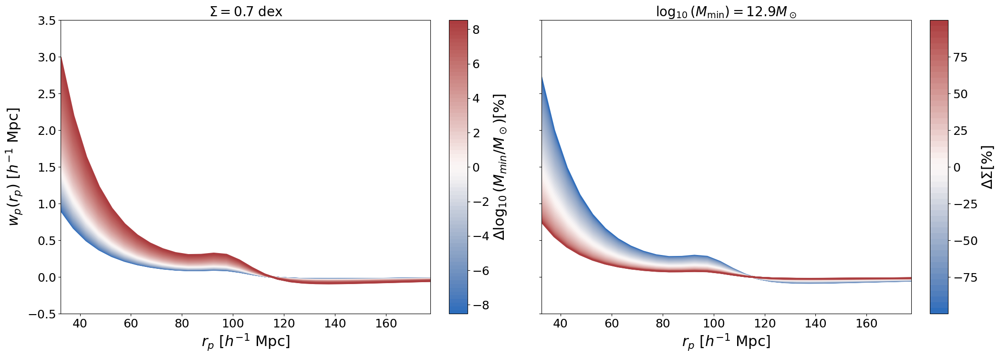

In [247]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (24, 8))
gs = gridspec.GridSpec(1, 7, wspace = 0, hspace = 0.1, width_ratios = [1, 0.05, 0.05, 0.2, 1, 0.05, 0.05])
ylim = -0.5, 3.5
l = 0

ax1 = fig.add_subplot(gs[0])

if quaia.recenter(rbins_chi2)[0] < 30:
    ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                      alpha = 0.5, label = 'scales excluded from fit')
    ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                      alpha = 0.5)

for k in range(len(bins)):
    n_m=HOD_scatter(10**f_duty, M_min+delta_Mmin*(-1+k/int(len(bins)/2)), bins, sigma)
    wp_2h_sample, _ = wp_2h(bins, n_m, a, 
             cosmo_planck18, wp_matter_zbin_i, recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_sample, linewidth = 2.5, color = cmap_M_min[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))  

ax1.set_title('$\Sigma={}$ dex'.format(sigma))
ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
ax1.set_ylim(ylim)
ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]')

ax1.set_ylabel(r"$w_p(r_p)$ $[h^{{-1}}$ Mpc]")
cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-delta_Mmin/M_min*100, vmax = delta_Mmin/M_min*100)), cax = fig.add_subplot(gs[2]), 
                label = '$\Delta \log_{10}(M_{min}/M_\odot)[\%]$')

ax1 = fig.add_subplot(gs[4])

for k in range(len(sigma_k_array)):
    n_m=HOD_scatter(10**f_duty, M_min, bins, sigma+delta*(-1+k/int(len(sigma_k_array)/2)))
    wp_2h_sample, _ = wp_2h(bins, n_m, a, 
             cosmo_planck18, wp_matter_zbin_i, recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_sample, linewidth = 2.5, color = cmap_sigma[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))

ax1.set_title('$\log_{{10}}(M_\mathrm{{min}})={:.1f} M_\odot$'.format(M_min))
ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
# ax1.set_ylabel(r"$w_p(r_p)$ $[h^{{-1}}$ Mpc]")
ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]')
ax1.set_yticklabels([])
ax1.set_ylim(ylim)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_sigma, norm = matplotlib.colors.Normalize(vmin=-delta/sigma*100, vmax = delta/sigma*100)), 
                    cax = fig.add_subplot(gs[6]), label = '$\Delta \Sigma [\%]$')

# plt.savefig('../figures/HOD_clustering_horizontal.pdf', bbox_inches = 'tight')
plt.show()

<>:22: SyntaxWarning: invalid escape sequence '\S'
<>:29: SyntaxWarning: invalid escape sequence '\D'
<>:39: SyntaxWarning: invalid escape sequence '\l'
<>:46: SyntaxWarning: invalid escape sequence '\D'
<>:22: SyntaxWarning: invalid escape sequence '\S'
<>:29: SyntaxWarning: invalid escape sequence '\D'
<>:39: SyntaxWarning: invalid escape sequence '\l'
<>:46: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2061/219632941.py:22: SyntaxWarning: invalid escape sequence '\S'
  ax1.set_title('$\Sigma={}$ dex'.format(sigma))
/tmp/ipykernel_2061/219632941.py:29: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$', location = 'top')
/tmp/ipykernel_2061/219632941.py:39: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$\log_{{10}}(M_\mathrm{{min}})={:.1f} M_\odot$'.format(M_min))
/tmp/ipykernel_2061/219632941.py:46: SyntaxWarning: invalid escape sequence '\D'
  cax = fig.add_subplot(gs[1]), label = '$\Delta \Sigma$ [dex]', locatio

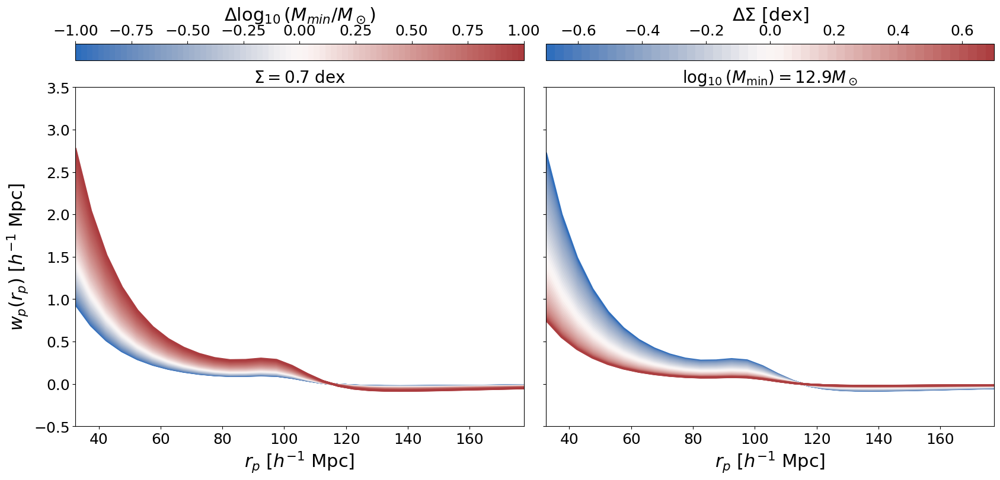

In [248]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (20, 8.4))
gs = gridspec.GridSpec(2, 2, wspace = 0.05, hspace = 0.15, height_ratios = [0.05, 1])
# ylim = -0.5, 3
l = 0

ax1 = fig.add_subplot(gs[2])

if quaia.recenter(rbins_chi2)[0] < 30:
    ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                      alpha = 0.5, label = 'scales excluded from fit')
    ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                      alpha = 0.5)

for k in range(len(bins)):
    n_m=HOD_scatter(10**f_duty, M_min-1+k/int(len(bins)/2), bins, sigma)
    wp_2h_sample, _ = wp_2h(bins, n_m, a, 
             cosmo_planck18, wp_matter_zbin_i, recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_sample, linewidth = 2.5, color = cmap_M_min[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))  

ax1.set_title('$\Sigma={}$ dex'.format(sigma))
ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
ax1.set_ylim(ylim)
ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]')

ax1.set_ylabel(r"$w_p(r_p)$ $[h^{{-1}}$ Mpc]")
cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[0]), 
                label = '$\Delta \log_{10}(M_{min}/M_\odot)$', location = 'top')

ax1 = fig.add_subplot(gs[3])

for k in range(len(sigma_k_array)):
    n_m=HOD_scatter(10**f_duty, M_min, bins, sigma+delta*(-1+k/int(len(sigma_k_array)/2)))
    wp_2h_sample, _ = wp_2h(bins, n_m, a, 
             cosmo_planck18, wp_matter_zbin_i, recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_sample, linewidth = 2.5, color = cmap_sigma[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))

ax1.set_title('$\log_{{10}}(M_\mathrm{{min}})={:.1f} M_\odot$'.format(M_min))
ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]')
ax1.set_yticklabels([])
ax1.set_ylim(ylim)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_sigma, norm = matplotlib.colors.Normalize(vmin=-delta, vmax = delta)), 
                    cax = fig.add_subplot(gs[1]), label = '$\Delta \Sigma$ [dex]', location = 'top')

plt.savefig('../figures/HOD_clustering_horizontal_top.pdf', bbox_inches = 'tight')
plt.show()

<>:22: SyntaxWarning: invalid escape sequence '\S'
<>:29: SyntaxWarning: invalid escape sequence '\D'
<>:39: SyntaxWarning: invalid escape sequence '\l'
<>:46: SyntaxWarning: invalid escape sequence '\D'
<>:22: SyntaxWarning: invalid escape sequence '\S'
<>:29: SyntaxWarning: invalid escape sequence '\D'
<>:39: SyntaxWarning: invalid escape sequence '\l'
<>:46: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2061/3797523532.py:22: SyntaxWarning: invalid escape sequence '\S'
  ax1.set_title('$\Sigma={}$ dex'.format(sigma))
/tmp/ipykernel_2061/3797523532.py:29: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$', location = 'bottom')
/tmp/ipykernel_2061/3797523532.py:39: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$\log_{{10}}(M_\mathrm{{min}})={:.1f} M_\odot$'.format(M_min))
/tmp/ipykernel_2061/3797523532.py:46: SyntaxWarning: invalid escape sequence '\D'
  cax = fig.add_subplot(gs[3]), label = '$\Delta \Sigma$ [dex]', 

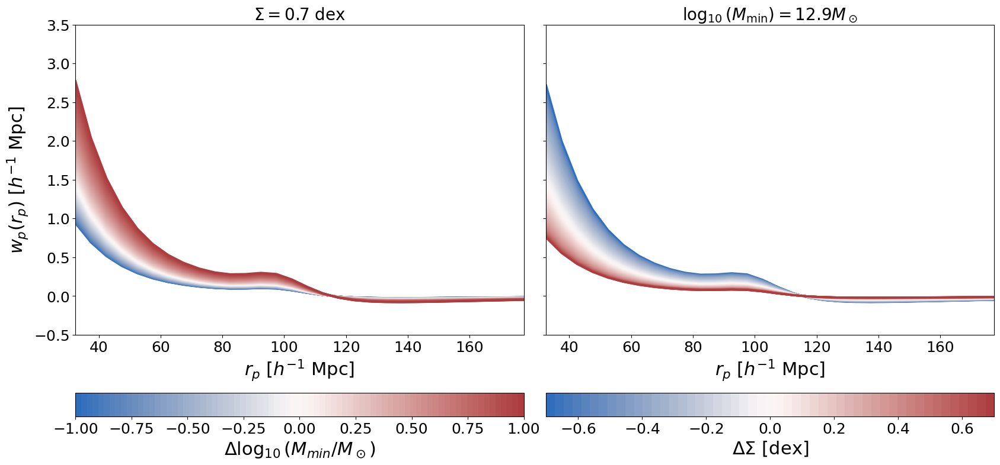

In [249]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (20, 8.6))
gs = gridspec.GridSpec(2, 2, wspace = 0.05, hspace = 0.35, height_ratios = [1, 0.075])
# ylim = -0.5, 3
l = 0

ax1 = fig.add_subplot(gs[0])

if quaia.recenter(rbins_chi2)[0] < 30:
    ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                      alpha = 0.5, label = 'scales excluded from fit')
    ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                      alpha = 0.5)

for k in range(len(bins)):
    n_m=HOD_scatter(10**f_duty, M_min-1+k/int(len(bins)/2), bins, sigma)
    wp_2h_sample, _ = wp_2h(bins, n_m, a, 
             cosmo_planck18, wp_matter_zbin_i, recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_sample, linewidth = 2.5, color = cmap_M_min[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))  

ax1.set_title('$\Sigma={}$ dex'.format(sigma))
ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
ax1.set_ylim(ylim)
ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]')

ax1.set_ylabel(r"$w_p(r_p)$ $[h^{{-1}}$ Mpc]")
cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[2]), 
                label = '$\Delta \log_{10}(M_{min}/M_\odot)$', location = 'bottom')

ax1 = fig.add_subplot(gs[1])

for k in range(len(sigma_k_array)):
    n_m=HOD_scatter(10**f_duty, M_min, bins, sigma+delta*(-1+k/int(len(sigma_k_array)/2)))
    wp_2h_sample, _ = wp_2h(bins, n_m, a, 
             cosmo_planck18, wp_matter_zbin_i, recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_sample, linewidth = 2.5, color = cmap_sigma[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))

ax1.set_title('$\log_{{10}}(M_\mathrm{{min}})={:.1f} M_\odot$'.format(M_min))
ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]')
ax1.set_yticklabels([])
ax1.set_ylim(ylim)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_sigma, norm = matplotlib.colors.Normalize(vmin=-delta, vmax = delta)), 
                    cax = fig.add_subplot(gs[3]), label = '$\Delta \Sigma$ [dex]', location = 'bottom')

plt.savefig('../figures/HOD_clustering_horizontal_bottom.pdf', bbox_inches = 'tight')
plt.show()

# Estimate min pimax

In [108]:
import importlib
importlib.reload(quaia)

<module 'quaia' from '/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/quaia.py'>

In [86]:
fac_rand = 25
for i in range(len(L_bins)):

    print('M_i<={}'.format(L_bins[i]))

    for j in z_array:

        print('{:.1f}<z<={:.1f}\n'.format(z_bins[j], z_bins[j+1]))
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, _, _, _, _, _, _, _ = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], bins = [z_bins, L_bins], 
                                                                                            tab_gcat_type = 'data', method = ['minmax', 'max'], 
                                                                                            fac_rand = fac_rand, mask_type = 'b', b = 30, 
                                                                                            n_bins = [None, None], verbose = False)

        z = np.median(tab_datahi_mask_zbin0['redshift_quaia'])
        delta_z = np.median(tab_datahi_mask_zbin0['redshift_quaia_err'])
        z1 = quaia.comoving_dist(z, h = Planck18.h, Om0 = Planck18.Om0)
        z2 = quaia.comoving_dist(z-delta_z, h = Planck18.h, Om0 = Planck18.Om0)
        pimin = z1-z2
        print('z        : {:.2f}'.format(z))
        print('delta_z  : {:.2f}'.format(delta_z))
        print('pimax    : {:.2f}'.format(pimin))
        print('5 x pimax: {:.2f}\n'.format(5*pimin))

M_i<=-20.0
0.0<z<=1.0

z        : 0.72
delta_z  : 0.08
pimax    : 161.75 Mpc / littleh
5 x pimax: 808.74 Mpc / littleh

1.0<z<=2.0

z        : 1.48
delta_z  : 0.09
pimax    : 118.77 Mpc / littleh
5 x pimax: 593.86 Mpc / littleh

2.0<z<=3.0

z        : 2.36
delta_z  : 0.09
pimax    : 77.23 Mpc / littleh
5 x pimax: 386.14 Mpc / littleh

3.0<z<=4.6

z        : 3.24
delta_z  : 0.09
pimax    : 58.00 Mpc / littleh
5 x pimax: 290.01 Mpc / littleh

M_i<=-25.0
0.0<z<=1.0

z        : 0.87
delta_z  : 0.08
pimax    : 142.47 Mpc / littleh
5 x pimax: 712.36 Mpc / littleh

1.0<z<=2.0

z        : 1.59
delta_z  : 0.08
pimax    : 95.38 Mpc / littleh
5 x pimax: 476.90 Mpc / littleh

2.0<z<=3.0

z        : 2.36
delta_z  : 0.09
pimax    : 77.23 Mpc / littleh
5 x pimax: 386.14 Mpc / littleh

3.0<z<=4.6

z        : 3.24
delta_z  : 0.09
pimax    : 58.00 Mpc / littleh
5 x pimax: 290.01 Mpc / littleh

M_i<=-26.0
0.0<z<=1.0

z        : 0.88
delta_z  : 0.10
pimax    : 179.14 Mpc / littleh
5 x pimax: 895.71 Mpc / 